# Capstone Viggy — Sleep-EDF

## Como retomar o projeto

1. Abre este notebook no Colab.
2. Deixa **`RUN_TC1_68 = False`** na célula 1.1.
3. Usa **Ambiente de execução → Executar tudo** e autoriza a Drive se for pedido.
4. Espera por **`SESSÃO PRONTA`** e **`PREPARAÇÃO CONCLUÍDA — treino TC1 desligado`**.

A secção 1 prepara o código, liga a mesma pasta da Drive, repõe o F2 e os folds A–E,
recupera os tempos e disponibiliza funções para novos treinos. A secção 4 prepara
as features temporais. As experiências anteriores ficam nas secções 2 e 3 como
arquivo de consulta; executar o notebook inteiro não volta a treiná-las.

| Secção | Conteúdo | Execução diária |
|---|---|---|
| 1 | Preparação e reposição da sessão | Automática |
| 2 | Histórico dos oito participantes | Consulta |
| 3 | Histórico dos 68 participantes | Consulta |
| 4 | Features temporais e ponto de início de novos treinos | Prepara as features; treino desligado por defeito |

**Referência atual:** F2 com Random Forest, kappa médio dos cinco folds **0,735 ± 0,017**.
Código do professor: `5949b723bbd34d172f072446dfcb802ef54b49f7`.
Os dez participantes finais continuam reservados.

Os EDF, os caches existentes e os resultados JSON/PNG continuam em
`/content/drive/MyDrive/CM2013_data`. As cópias de leitura ficam apenas no disco
temporário do Colab. O setup não descarrega novamente o Sleep-EDF.

## 1 — Preparar uma sessão nova

### 1.1 — Caminhos e opção de treino

Mantém a pasta já utilizada pelo projeto. A opção de treino fica desligada
na preparação diária.

In [10]:
# Caminhos e opções da sessão.
from pathlib import Path
import errno
import hashlib
import importlib.metadata
import importlib.util
import json
import os
import pickle
import platform
import shutil
import subprocess
import sys
import time

COURSE_REVISION = "5949b723bbd34d172f072446dfcb802ef54b49f7"
COURSE_URL = "https://github.com/farhad-abtahi/CM2013.git"
DATA = "/content/drive/MyDrive/CM2013_data"
TRAIN_DIR = Path(DATA) / "train"
CACHE_VIGGY = str(Path(DATA) / "cache" / "viggy")
EXPERIMENTS_DIR = Path(DATA) / "experiments"
LOCAL_SESSION_DIR = Path("/content/CM2013_viggy_runtime")
COURSE_DIR = Path("/content/_bsp_repo")

# Deixar False na preparação diária. Só alterar quando decidirmos treinar.
RUN_TC1_68 = False
USE_REAL = True
BASELINE_CONFIG = {}
SESSAO_PRONTA = False
_SETUP_STAGES_68 = set()
_IO_RETRIES = 3
_DRIVE_REMOUNT_USED = False
_DRIVER_RECOVERIES = []

EXPECTED_FOLDS_68 = {
    "A": "SC400 SC405 SC411 SC417 SC422 SC428 SC434 SC441 SC446 SC452 SC458 SC463 SC471 SC477".split(),
    "B": "SC401 SC406 SC412 SC418 SC423 SC429 SC435 SC442 SC447 SC453 SC459 SC465 SC473 SC481".split(),
    "C": "SC402 SC407 SC413 SC419 SC425 SC430 SC436 SC443 SC449 SC454 SC460 SC466 SC474 SC482".split(),
    "D": "SC403 SC409 SC414 SC420 SC426 SC431 SC437 SC444 SC450 SC455 SC461 SC467 SC475".split(),
    "E": "SC404 SC410 SC415 SC421 SC427 SC433 SC438 SC445 SC451 SC457 SC462 SC470 SC476".split(),
}
HOLDOUT_GROUPS = set(
    "SC408 SC416 SC424 SC432 SC440 SC448 SC456 SC464 SC472 SC480".split()
)
LOCAL_SESSION_DIR.mkdir(parents=True, exist_ok=True)

def _require_stage_68(nome):
    if nome not in _SETUP_STAGES_68:
        raise RuntimeError(
            f"Preparação incompleta ({nome}). Executa a secção 1 por ordem."
        )

print("Dados:", DATA)
print("Novos treinos ativados:", RUN_TC1_68)


Dados: /content/drive/MyDrive/CM2013_data
Novos treinos ativados: True


### 1.2 — Ligar a Drive e preparar leituras fiáveis

Os caches de features, os relatórios e as marcações são lidos através de cópias
temporárias no disco do Colab. Em erros transitórios de ligação, há no máximo
três tentativas por operação e uma remontagem da Drive por preparação.
Os ficheiros de origem não são alterados.

In [11]:
from google.colab import drive
import stat as _stat

drive.mount("/content/drive")

def _drive_io(operacao, descricao):
    """Repetir apenas erros transitórios de I/O, com um remount no máximo."""
    global _DRIVE_REMOUNT_USED
    transitorios = {
        errno.EIO, errno.ECONNABORTED, errno.ECONNRESET,
        errno.ENOTCONN, errno.ETIMEDOUT, getattr(errno, "ESTALE", 116),
    }
    for tentativa in range(_IO_RETRIES):
        try:
            return operacao()
        except OSError as exc:
            if exc.errno not in transitorios or tentativa == _IO_RETRIES - 1:
                raise OSError(
                    exc.errno,
                    f"{descricao}: {exc.strerror or str(exc)}. "
                    "A preparação parou; os dados e resultados anteriores não foram apagados.",
                    getattr(exc, "filename", None),
                ) from exc
            print(
                f"Falha temporária na Drive: {descricao}. "
                f"Nova tentativa {tentativa + 2}/{_IO_RETRIES}.",
                flush=True,
            )
            if exc.errno in {errno.ECONNABORTED, errno.ENOTCONN, errno.ECONNRESET}:
                if not _DRIVE_REMOUNT_USED:
                    _DRIVE_REMOUNT_USED = True
                    _DRIVER_RECOVERIES.append(descricao)
                    drive.mount("/content/drive", force_remount=True)
            time.sleep(1)

def _file_signature(caminho):
    caminho = Path(caminho)
    st = _drive_io(caminho.stat, f"verificar {caminho.name}")
    return {"name": caminho.name, "bytes": st.st_size, "mtime_ns": st.st_mtime_ns}

def _drive_is_file(caminho):
    caminho = Path(caminho)
    try:
        st = _drive_io(caminho.stat, f"verificar {caminho.name}")
    except FileNotFoundError:
        return False
    return _stat.S_ISREG(st.st_mode)

def _local_copy(caminho, grupo="files"):
    """Cópia temporária no Colab. A origem na Drive é só lida."""
    caminho = Path(caminho)
    assinatura = _file_signature(caminho)
    chave = hashlib.sha256(
        json.dumps([str(caminho), assinatura], sort_keys=True).encode()
    ).hexdigest()[:20]
    destino = LOCAL_SESSION_DIR / grupo / f"{chave}_{caminho.name}"
    destino.parent.mkdir(parents=True, exist_ok=True)

    if destino.is_file() and destino.stat().st_size == assinatura["bytes"]:
        return destino

    def copiar():
        temporario = destino.with_suffix(destino.suffix + ".tmp")
        shutil.copyfile(caminho, temporario)
        assert temporario.stat().st_size == assinatura["bytes"], (
            f"Cópia incompleta: {caminho.name}"
        )
        assert _file_signature(caminho) == assinatura, (
            f"O ficheiro mudou durante a leitura: {caminho.name}"
        )
        temporario.replace(destino)
        return destino

    return _drive_io(copiar, f"copiar {caminho.name} para o disco local")

def _read_json(caminho):
    local = _local_copy(caminho, "reports")
    return json.loads(local.read_text(encoding="utf-8"))

def _atomic_bytes(caminho, conteudo):
    caminho = Path(caminho)
    def escrever():
        caminho.parent.mkdir(parents=True, exist_ok=True)
        temporario = caminho.with_suffix(caminho.suffix + ".tmp")
        temporario.write_bytes(conteudo)
        temporario.replace(caminho)
    _drive_io(escrever, f"guardar {caminho.name}")

def converter_numpy(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    raise TypeError(f"Tipo não suportado: {type(obj).__name__}")

def _atomic_json(caminho, objeto):
    conteudo = json.dumps(
        objeto, default=converter_numpy, ensure_ascii=False, indent=2
    ).encode("utf-8")
    _atomic_bytes(caminho, conteudo)

assert _stat.S_ISDIR(_drive_io(Path(DATA).stat, "abrir a pasta de dados").st_mode), DATA
assert _stat.S_ISDIR(_drive_io(TRAIN_DIR.stat, "abrir a pasta train").st_mode), TRAIN_DIR
print("Drive ligada e pasta de dados acessível.")
_SETUP_STAGES_68.add("drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive ligada e pasta de dados acessível.


### 1.3 — Preparar os programas e manter a referência

O notebook lê a configuração do F2 guardado, mantém a revisão do curso e alinha
os pacotes com as versões registadas. Se um pacote já carregado precisar de
reinício após a instalação, o código indica-o antes de avançar.

In [12]:
# Ler primeiro a configuração antiga, antes de importar os pacotes científicos.
_require_stage_68("drive")
ref_a_path = EXPERIMENTS_DIR / "F2_68_fixed_AE_fold_A.json"
ref_a_guardada_68 = _read_json(ref_a_path)
config_f2_guardada_68 = ref_a_guardada_68.get("metadata", ref_a_guardada_68)
assert config_f2_guardada_68["course_revision"] == COURSE_REVISION
assert config_f2_guardada_68["fold_assignment"] == EXPECTED_FOLDS_68

# Reutilizar ou obter apenas o código do professor, na revisão original.
if not (COURSE_DIR / ".git").is_dir():
    if COURSE_DIR.exists() and any(COURSE_DIR.iterdir()):
        raise RuntimeError(
            f"{COURSE_DIR} já contém ficheiros. Usa outra pasta para o código do curso."
        )
    COURSE_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "init", "--quiet", str(COURSE_DIR)], check=True)
    subprocess.run(
        ["git", "-C", str(COURSE_DIR), "remote", "add", "origin", COURSE_URL],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(COURSE_DIR), "fetch", "--quiet", "--depth", "1",
         "origin", COURSE_REVISION], check=True,
    )
    subprocess.run(
        ["git", "-C", str(COURSE_DIR), "checkout", "--quiet",
         "--detach", "FETCH_HEAD"], check=True,
    )

course_revision_loaded = subprocess.check_output(
    ["git", "-C", str(COURSE_DIR), "rev-parse", "HEAD"], text=True
).strip()
assert course_revision_loaded == COURSE_REVISION, (
    "O checkout existente é de outra revisão. Preserva as alterações "
    "e usa uma sessão nova ou uma pasta separada para o curso."
)

# Alinhar os pacotes com as versões realmente registadas no F2.
PACKAGE_MAP = {
    "numpy": "numpy", "scipy": "scipy", "sklearn": "scikit-learn",
    "mne": "mne", "matplotlib": "matplotlib", "pandas": "pandas",
    "imblearn": "imbalanced-learn",
}
reference_runtime = config_f2_guardada_68["runtime"]
instalar = []
for module, distribution in PACKAGE_MAP.items():
    expected = reference_runtime.get(distribution)
    try:
        installed = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if expected and expected != "not installed" and installed != expected:
        instalar.append(f"{distribution}=={expected}")
    elif installed is None:
        instalar.append(distribution)

if instalar:
    print("A alinhar pacotes:", ", ".join(instalar), flush=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *instalar],
        check=True,
    )

# Um módulo já carregado não muda de versão só por reinstalar o pacote.
loaded_conflicts = {}
for module, distribution in PACKAGE_MAP.items():
    expected = reference_runtime.get(distribution)
    loaded = sys.modules.get(module)
    if expected and loaded is not None and hasattr(loaded, "__version__"):
        if loaded.__version__ != expected:
            loaded_conflicts[distribution] = {
                "carregada": loaded.__version__, "necessária": expected
            }
if loaded_conflicts:
    raise RuntimeError(
        "Os pacotes foram alinhados, mas a sessão ainda tem versões antigas na memória. "
        "No Colab, reinicia a sessão e volta a usar Executar tudo. "
        + str(loaded_conflicts)
    )

for subfolder in ("tracks", "src", "src/bsp"):
    entry = str(COURSE_DIR / subfolder)
    if entry not in sys.path:
        sys.path.insert(0, entry)

import sleep_edf
from sleep_edf import SleepEDFTrack
import numpy as np
import pandas as pd
import scipy
import sklearn
import mne
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

assert Path(sleep_edf.__file__).resolve().parent == COURSE_DIR / "tracks", (
    "Outro módulo sleep_edf já está carregado. Reinicia a sessão."
)

runtime_versions = {"python": platform.python_version()}
for distribution in PACKAGE_MAP.values():
    runtime_versions[distribution] = importlib.metadata.version(distribution)

def verificar_runtime_referencia_68():
    diferentes = {
        p: {"F2": reference_runtime[p], "agora": runtime_versions[p]}
        for p in ("numpy", "scipy", "scikit-learn", "mne")
        if p in reference_runtime and runtime_versions[p] != reference_runtime[p]
    }
    if diferentes:
        raise RuntimeError("Versões diferentes da referência F2: " + str(diferentes))

verificar_runtime_referencia_68()
print("Código do curso:", course_revision_loaded)
print("Runtime:", json.dumps(runtime_versions, sort_keys=True))
_SETUP_STAGES_68.add("runtime")


Código do curso: 5949b723bbd34d172f072446dfcb802ef54b49f7
Runtime: {"imbalanced-learn": "0.14.2", "matplotlib": "3.10.0", "mne": "1.13.2", "numpy": "2.1.3", "pandas": "2.2.3", "python": "3.13.18", "scikit-learn": "1.6.1", "scipy": "1.16.3"}


### 1.4 — Repor as features e os folds A–E

Lê os 133 caches B0, reconstrói as cinco potências relativas e confirma a ordem
das épocas contra os cinco relatórios F2. Não ajusta um classificador.

In [13]:
# A ordem dos caches é arbitrária. A ordem válida vem do relatório F2.
_require_stage_68("runtime")
resultados_f2_68 = {
    fold: (ref_a_guardada_68 if fold == "A" else _read_json(
        EXPERIMENTS_DIR / f"F2_68_fixed_AE_fold_{fold}.json"
    ))
    for fold in "ABCDE"
}
FOLDS_68 = {k: list(v) for k, v in config_f2_guardada_68["fold_assignment"].items()}
assert FOLDS_68 == EXPECTED_FOLDS_68
DEVELOPMENT_GROUPS_68 = sorted(s for v in FOLDS_68.values() for s in v)
assert len(DEVELOPMENT_GROUPS_68) == len(set(DEVELOPMENT_GROUPS_68)) == 68
assert set(DEVELOPMENT_GROUPS_68).isdisjoint(HOLDOUT_GROUPS)

def identificar_gravacao_reposta_68(entrada):
    if isinstance(entrada, dict):
        entrada = entrada["record"]
    return Path(str(entrada)).name.removesuffix(".edf").removesuffix("-PSG")

registos_guardados_68 = config_f2_guardada_68["recordings"]
ordem_gravacoes_reposta_68 = [
    identificar_gravacao_reposta_68(r) for r in registos_guardados_68
]
assert len(ordem_gravacoes_reposta_68) == len(set(ordem_gravacoes_reposta_68)) == 133

def _listar_caches_b0():
    with os.scandir(CACHE_VIGGY) as entradas:
        return sorted(
            Path(e.path) for e in entradas
            if e.name.startswith("_cache_viggy_b0_features_") and e.name.endswith(".pkl")
        )

caches_b0_para_repor = _drive_io(_listar_caches_b0, "listar os caches B0")
assert len(caches_b0_para_repor) == 133, (
    f"Encontrei {len(caches_b0_para_repor)} caches B0, esperava 133. "
    "Verifica a pasta antes de continuar; não será iniciado nenhum download."
)
cache_por_gravacao_68 = {}
for i, caminho in enumerate(caches_b0_para_repor, 1):
    local = _local_copy(caminho, "features_b0")
    with local.open("rb") as f:
        dados = pickle.load(f)
    assert {"record", "X", "y", "groups", "feature_names"} <= dados.keys()
    record = identificar_gravacao_reposta_68(dados["record"])
    assert record not in cache_por_gravacao_68, f"Cache repetido para {record}."
    cache_por_gravacao_68[record] = dados
    if i % 25 == 0 or i == len(caches_b0_para_repor):
        print(f"Caches recuperados: {i}/{len(caches_b0_para_repor)}", flush=True)

assert set(cache_por_gravacao_68) == set(ordem_gravacoes_reposta_68)
b0_gravacoes_68 = [cache_por_gravacao_68[r] for r in ordem_gravacoes_reposta_68]
nomes_features_b0 = list(b0_gravacoes_68[0]["feature_names"])
nomes_features_f2_68 = list(config_f2_guardada_68["feature_names"])
assert len(nomes_features_b0) == 11
assert nomes_features_f2_68[:11] == nomes_features_b0
assert len(nomes_features_f2_68) == 16

_X, _y, _groups, _record_ids = [], [], [], []
for record, dados, registo in zip(
    ordem_gravacoes_reposta_68, b0_gravacoes_68, registos_guardados_68
):
    xx = np.asarray(dados["X"], dtype=float)
    yy = np.asarray(dados["y"]).astype(str)
    gg = np.asarray(dados["groups"]).astype(str)
    if gg.ndim == 0:
        gg = np.full(len(yy), gg.item())
    assert list(dados["feature_names"]) == nomes_features_b0
    assert xx.shape == (len(yy), 11)
    assert gg.shape == yy.shape == (len(yy),)
    assert np.isfinite(xx).all() and np.all(gg == record[:5])
    if isinstance(registo, dict) and "epochs" in registo:
        assert len(yy) == registo["epochs"]
    _X.append(xx); _y.append(yy); _groups.append(gg)
    _record_ids.append(np.full(len(yy), record))

X_b0_68 = np.vstack(_X)
y_b0_68 = np.concatenate(_y)
groups_b0_68 = np.concatenate(_groups)
record_ids_b0_68 = np.concatenate(_record_ids)
del _X, _y, _groups, _record_ids

B0_FEATURE_VERSION = config_f2_guardada_68.get("details", {}).get("base_feature_version", 1)
F2_FEATURE_VERSION = config_f2_guardada_68["feature_version"]
assert B0_FEATURE_VERSION == F2_FEATURE_VERSION == 1
bandas_f2_68 = ["delta", "theta", "alpha", "sigma", "beta"]
indices_bandas_f2_68 = [nomes_features_b0.index(f"eeg_{b}") for b in bandas_f2_68]
potencias_f2_68 = X_b0_68[:, indices_bandas_f2_68]
assert np.all(potencias_f2_68 >= 0)
_total_f2 = potencias_f2_68.sum(axis=1, keepdims=True)
_relativas_f2 = np.divide(
    potencias_f2_68, _total_f2,
    out=np.zeros_like(potencias_f2_68), where=_total_f2 > 0,
)
X_f2_68 = np.column_stack([X_b0_68, _relativas_f2])
assert X_b0_68.shape == (360621, 11)
assert X_f2_68.shape == (360621, 16)
assert np.isfinite(X_f2_68).all()
assert set(groups_b0_68) == set(DEVELOPMENT_GROUPS_68)

SPLITS_68 = {}
previsoes_f2_68 = np.empty_like(y_b0_68)
fold_por_epoca_68 = np.empty(len(y_b0_68), dtype="<U1")
_cobertura_68 = np.zeros(len(y_b0_68), dtype=np.uint8)
for fold in "ABCDE":
    teste = np.isin(groups_b0_68, FOLDS_68[fold])
    tr, te = np.flatnonzero(~teste), np.flatnonzero(teste)
    ref = resultados_f2_68[fold]
    assert ref["fold_assignment"] == FOLDS_68
    np.testing.assert_array_equal(te, ref["test_indices"])
    np.testing.assert_array_equal(y_b0_68[te], ref["report"]["y_true"])
    np.testing.assert_array_equal(groups_b0_68[te], ref["report"]["y_group"])
    assert set(groups_b0_68[tr]).isdisjoint(set(groups_b0_68[te]))
    assert np.all(_cobertura_68[te] == 0)
    assert len(ref["report"]["y_pred"]) == len(te)
    SPLITS_68[fold] = (tr, te)
    previsoes_f2_68[te] = ref["report"]["y_pred"]
    fold_por_epoca_68[te] = fold
    _cobertura_68[te] += 1
assert np.all(_cobertura_68 == 1)

def _erro_walk_68(exc):
    raise exc

def _indexar_psg_68():
    encontrados = {}
    for pasta, _, ficheiros in os.walk(TRAIN_DIR, onerror=_erro_walk_68):
        for nome in ficheiros:
            if nome.endswith("-PSG.edf"):
                record = identificar_gravacao_reposta_68(nome)
                if record in cache_por_gravacao_68:
                    assert record not in encontrados, f"PSG repetido: {record}"
                    encontrados[record] = Path(pasta) / nome
    return encontrados

psg_por_gravacao_68 = _drive_io(_indexar_psg_68, "localizar os PSG")
assert set(psg_por_gravacao_68) == set(ordem_gravacoes_reposta_68)
ficheiros_b0_68 = [psg_por_gravacao_68[r] for r in ordem_gravacoes_reposta_68]
limites_gravacoes_68 = np.r_[0, np.cumsum([len(d["y"]) for d in b0_gravacoes_68])]

print("F2 reposto:", X_f2_68.shape)
print("68 participantes, 133 gravações e folds A–E verificados.")
_SETUP_STAGES_68.add("features")


Caches recuperados: 25/133
Caches recuperados: 50/133
Caches recuperados: 75/133
Caches recuperados: 100/133
Caches recuperados: 125/133
Caches recuperados: 133/133
F2 reposto: (360621, 16)
68 participantes, 133 gravações e folds A–E verificados.


### 1.5 — Repor os tempos originais

O cache de tempos é reutilizado se os ficheiros, as labels e a configuração
corresponderem. Quando é necessário ler marcações, o Hypnogram é copiado para o
disco local antes de ser aberto pelo MNE. O PSG é aberto sem carregar os sinais
completos.

O progresso fica guardado na primeira gravação e a cada 25. Se ocorrer uma falha,
o trabalho pendente também é conservado no disco temporário da sessão.

In [14]:
_require_stage_68("features")
EPOCH_TIMES_VERSION_68 = 1
EPOCH_SECONDS_68 = 30.0
CONSECUTIVE_TOL_68 = 1e-6
RK_TEMPOS_68 = {
    "Sleep stage W": "W", "Sleep stage 1": "N1", "Sleep stage 2": "N2",
    "Sleep stage 3": "N3", "Sleep stage 4": "N3", "Sleep stage R": "REM",
}
META_TEMPOS_68 = {
    "version": EPOCH_TIMES_VERSION_68,
    "course_revision": COURSE_REVISION,
    "epoch_seconds": EPOCH_SECONDS_68,
    "required_native_fs": 100.0,
    "time_origin": "PSG sample zero",
    "event_rounding": True,
    "stage_mapping": RK_TEMPOS_68,
    "mne": mne.__version__,
    "numpy": np.__version__,
}
FICHEIRO_TEMPOS_68 = Path(CACHE_VIGGY) / "viggy_epoch_times_68_v1.json"
_LOCAL_TIMES_PENDING = LOCAL_SESSION_DIR / "epoch_times_pending_v1.json"

def _ler_tempos_edf_68(psg, hyp_local, labels):
    # PSG: apenas cabeçalho. Hypnogram: cópia pequena no disco local.
    raw = mne.io.read_raw_edf(psg, preload=False, verbose="ERROR")
    try:
        fs = float(raw.info["sfreq"])
        assert abs(fs - 100.0) < 1e-6 and raw.first_samp == 0
        raw.set_annotations(mne.read_annotations(hyp_local), emit_warning=False)
        eventos, ids = mne.events_from_annotations(
            raw,
            event_id={k: i for i, k in enumerate(RK_TEMPOS_68)},
            use_rounding=True, chunk_duration=EPOCH_SECONDS_68, verbose="ERROR",
        )
        assert np.all(eventos[:, 0] >= 0)
        passo = int(EPOCH_SECONDS_68 * fs)
        eventos = eventos[eventos[:, 0] + passo <= raw.n_times]
        inverso = {codigo: RK_TEMPOS_68[nome] for nome, codigo in ids.items()}
        lidas = np.asarray([inverso[int(e[2])] for e in eventos]).astype(str)
        np.testing.assert_array_equal(lidas, labels, err_msg=f"Labels: {psg.name}")
        return eventos[:, 0].astype(float) / fs, float(raw.n_times / fs)
    finally:
        raw.close()

def _validar_tempos_68(tempos, duracao, labels):
    assert tempos.shape == labels.shape and len(labels) > 0
    assert np.isfinite(tempos).all() and np.isfinite(duracao)
    assert np.all(np.diff(tempos) > 0) and tempos[0] >= 0
    assert tempos[-1] + EPOCH_SECONDS_68 <= duracao + CONSECUTIVE_TOL_68

def preparar_tempos_sessao_68():
    cache = {"metadata": META_TEMPOS_68, "records": {}}
    pendente_reposto = False
    if _drive_is_file(FICHEIRO_TEMPOS_68):
        anterior = _read_json(FICHEIRO_TEMPOS_68)
        if anterior.get("metadata") == META_TEMPOS_68:
            cache = anterior
    if _LOCAL_TIMES_PENDING.is_file():
        pendente = json.loads(_LOCAL_TIMES_PENDING.read_text(encoding="utf-8"))
        if pendente.get("metadata") == META_TEMPOS_68:
            cache["records"].update(pendente["records"])
            pendente_reposto = True

    tempos_por_gravacao, blocos_t, blocos_prev = {}, [], []
    calculadas = reutilizadas = posicao = 0
    alterado = pendente_reposto

    try:
        for numero, (psg, dados) in enumerate(zip(ficheiros_b0_68, b0_gravacoes_68), 1):
            record = identificar_gravacao_reposta_68(dados["record"])
            assert psg.name == f"{record}-PSG.edf"
            assert record[:5] in DEVELOPMENT_GROUPS_68
            labels = np.asarray(dados["y"]).astype(str)

            hyp = psg.with_name(psg.name.replace("-PSG.edf", "-Hypnogram.edf"))
            if not _drive_is_file(hyp):
                candidatos = _drive_io(
                    lambda: sorted(psg.parent.glob(f"{record[:6]}*Hypnogram.edf")),
                    f"localizar marcações de {record}",
                )
                assert len(candidatos) == 1, f"Marcações ambíguas: {record}"
                hyp = candidatos[0]

            assinatura = {
                "psg": _file_signature(psg),
                "hypnogram": _file_signature(hyp),
                "labels_sha256": hashlib.sha256("\n".join(labels).encode()).hexdigest(),
            }
            entrada = cache["records"].get(record)
            if entrada is not None and entrada.get("signature") == assinatura:
                tempos = np.asarray(entrada["onsets_seconds"], dtype=float)
                duracao = float(entrada["duration_seconds"])
                reutilizadas += 1
            else:
                hyp_local = _local_copy(hyp, "annotations")
                tempos, duracao = _drive_io(
                    lambda: _ler_tempos_edf_68(psg, hyp_local, labels),
                    f"ler o cabeçalho de {record}",
                )
                _validar_tempos_68(tempos, duracao, labels)
                assert _file_signature(psg) == assinatura["psg"]
                assert _file_signature(hyp) == assinatura["hypnogram"]
                cache["records"][record] = {
                    "signature": assinatura,
                    "onsets_seconds": tempos.tolist(),
                    "duration_seconds": duracao,
                }
                calculadas += 1
                alterado = True

            _validar_tempos_68(tempos, duracao, labels)
            fim = posicao + len(labels)
            assert np.all(record_ids_b0_68[posicao:fim] == record)
            np.testing.assert_array_equal(y_b0_68[posicao:fim], labels)
            posicao = fim

            anterior_valida = np.zeros(len(tempos), dtype=bool)
            anterior_valida[1:] = np.isclose(
                np.diff(tempos), EPOCH_SECONDS_68, rtol=0, atol=CONSECUTIVE_TOL_68
            )
            tempos_por_gravacao[record] = (tempos, duracao)
            blocos_t.append(tempos)
            blocos_prev.append(anterior_valida)

            # Guardar a primeira gravação e depois os checkpoints normais.
            if numero == 1 or numero % 25 == 0 or numero == len(ficheiros_b0_68):
                if alterado:
                    _atomic_json(FICHEIRO_TEMPOS_68, cache)
                    alterado = False
                if numero % 25 == 0 or numero == len(ficheiros_b0_68):
                    print(f"Tempos verificados: {numero}/{len(ficheiros_b0_68)}", flush=True)
    except (Exception, KeyboardInterrupt):
        # Preservar o trabalho desta sessão mesmo se a Drive ficar indisponível.
        _LOCAL_TIMES_PENDING.write_text(
            json.dumps(cache, ensure_ascii=False), encoding="utf-8"
        )
        raise

    assert posicao == len(y_b0_68)
    if _LOCAL_TIMES_PENDING.is_file():
        _LOCAL_TIMES_PENDING.unlink()  # Apenas ficheiro temporário no disco local.
    return tempos_por_gravacao, np.concatenate(blocos_t), np.concatenate(blocos_prev), calculadas, reutilizadas

(
    tempos_epocas_68, onsets_epocas_68, anterior_consecutiva_68,
    calculados_tempos_68, reutilizados_tempos_68,
) = preparar_tempos_sessao_68()

# Nome antigo mantido para compatibilidade; isto não aplica um corte de Wake.
tempos_c1_68 = tempos_epocas_68
print(
    f"Tempos prontos: {len(tempos_epocas_68)} gravações | "
    f"{calculados_tempos_68} lidas agora | {reutilizados_tempos_68} reutilizadas."
)
print("Cache de tempos:", FICHEIRO_TEMPOS_68)
_SETUP_STAGES_68.add("times")


Tempos verificados: 25/133
Tempos verificados: 50/133
Tempos verificados: 75/133
Tempos verificados: 100/133
Tempos verificados: 125/133
Tempos verificados: 133/133
Tempos prontos: 133 gravações | 0 lidas agora | 133 reutilizadas.
Cache de tempos: /content/drive/MyDrive/CM2013_data/cache/viggy/viggy_epoch_times_68_v1.json


### 1.6 — Preparar o Random Forest e as funções comuns

Recria o modelo de referência sem o treinar e disponibiliza as funções de avaliação,
relatório e exportação. Os ajustes só acontecem quando a função de treino é
chamada explicitamente na secção 4.2.

In [15]:
import copy
import io
import re
import warnings
from datetime import datetime, timezone

_require_stage_68("times")

ESTAGIOS_68 = ["W", "N1", "N2", "N3", "REM"]
METRICAS_68 = ["cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"]

track_ref_68 = SleepEDFTrack(cfg={})
track_b0_68 = track_ref_68
track_c1_68 = track_ref_68
modelo_base_f2_68 = Pipeline([
    ("scale", StandardScaler(**config_f2_guardada_68["scaler_params"])),
    ("clf", RandomForestClassifier(**config_f2_guardada_68["classifier_params"])),
])
modelo_base_b0 = modelo_base_f2_68
relatorio_f2_68 = track_ref_68._make_report(
    y_b0_68, previsoes_f2_68, groups=groups_b0_68, folds=fold_por_epoca_68
)
tabela_f2_68 = pd.DataFrame([
    {"Fold": f, **{m: resultados_f2_68[f]["report"][m] for m in METRICAS_68},
     "Treino (min)": resultados_f2_68[f]["fit_seconds"] / 60}
    for f in "ABCDE"
]).set_index("Fold")
_RESULTADOS_DA_SESSAO_68 = globals().get("_RESULTADOS_DA_SESSAO_68", {})

def assinatura_arrays_68(*arrays):
    h = hashlib.sha256()
    for arr in arrays:
        a = np.asarray(arr)
        if a.dtype.kind in "OUS":
            a = a.astype(str)
        a = np.ascontiguousarray(a)
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(memoryview(a).cast("B"))
    return h.hexdigest()

def juntar_previsoes_68(resultados):
    assert set(resultados) == set("ABCDE")
    previsoes = np.empty_like(y_b0_68)
    cobertura = np.zeros(len(y_b0_68), dtype=np.uint8)
    folds = np.empty(len(y_b0_68), dtype="<U1")
    for fold in "ABCDE":
        r = resultados[fold]
        te = np.asarray(r["test_indices"], dtype=int)
        rep = r["report"]
        np.testing.assert_array_equal(te, SPLITS_68[fold][1])
        np.testing.assert_array_equal(rep["y_true"], y_b0_68[te])
        np.testing.assert_array_equal(rep["y_group"], groups_b0_68[te])
        pred = np.asarray(rep["y_pred"])
        assert pred.shape == te.shape and np.isin(pred, ESTAGIOS_68).all()
        assert np.all(cobertura[te] == 0)
        previsoes[te] = pred
        folds[te] = fold
        cobertura[te] += 1
    assert np.all(cobertura == 1)
    rep = track_ref_68._make_report(
        y_b0_68, previsoes, groups=groups_b0_68, folds=folds
    )
    return previsoes, rep

def avaliar_nova_experiencia_68(nome, X, nomes_features, receita, modelo=None):
    """Cinco fits apenas quando esta função é chamada explicitamente."""
    assert SESSAO_PRONTA, "Executa primeiro a secção 1 completa."
    verificar_runtime_referencia_68()
    assert re.fullmatch(r"[A-Za-z0-9_-]+", nome), "Usa um identificador simples."
    assert nome not in {
        "B0_68_fixed_AE", "F2_68_fixed_AE", "LP40_68_fixed_AE",
        "C1_68_crop30_fixed_AE", "LR1_68_fixed_AE",
    }, "Os identificadores das experiências fechadas ficam reservados."

    X = np.asarray(X)
    assert X.shape == (len(y_b0_68), len(nomes_features))
    assert np.isfinite(X).all()
    base = clone(modelo_base_f2_68 if modelo is None else modelo)
    assert isinstance(base, Pipeline)
    manifesto_modelo = [
        {"step": n, "class": f"{type(e).__module__}.{type(e).__qualname__}",
         "params": e.get_params(deep=False)}
        for n, e in base.steps
    ]
    meta = {
        "experiment": nome, "schema_version": 1,
        "course_revision": COURSE_REVISION,
        "reference_experiment": "F2_68_fixed_AE",
        "split_unit": "subject", "cv_method": "five fixed subject folds A-E",
        "fold_assignment": FOLDS_68, "n_subjects": 68,
        "n_recordings": 133, "n_epochs": len(y_b0_68),
        "feature_names": list(nomes_features), "recipe": receita,
        "training_selection": "all original retained training epochs",
        "data_sha256": assinatura_arrays_68(X, y_b0_68, groups_b0_68, record_ids_b0_68),
        "model": manifesto_modelo, "runtime": runtime_versions,
        "feature_cache_runtime": reference_runtime,
    }
    meta = json.loads(json.dumps(meta, default=converter_numpy))
    resultados = {}
    for fold in "ABCDE":
        tr, te = SPLITS_68[fold]
        assert set(groups_b0_68[te]) == set(FOLDS_68[fold])
        assert set(groups_b0_68[tr]).isdisjoint(set(groups_b0_68[te]))
        destino = EXPERIMENTS_DIR / f"{nome}_fold_{fold}.json"
        novo = False
        if _drive_is_file(destino):
            r = _read_json(destino)
        elif (nome, fold) in _RESULTADOS_DA_SESSAO_68:
            r = _RESULTADOS_DA_SESSAO_68[(nome, fold)]
            novo = True
        else:
            print(f"{nome} — fold {fold}: a treinar...", flush=True)
            clf = clone(base)
            inicio = time.perf_counter()
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                clf.fit(X[tr], y_b0_68[tr])
            fit_seconds = time.perf_counter() - inicio
            estimator = clf.steps[-1][1]
            n_iter = getattr(estimator, "n_iter_", None)
            if n_iter is not None and hasattr(estimator, "max_iter"):
                assert np.all(np.asarray(n_iter) < estimator.max_iter), (
                    "O ajuste atingiu max_iter; resolver antes de aceitar o resultado."
                )
            inicio = time.perf_counter()
            pred = clf.predict(X[te])
            predict_seconds = time.perf_counter() - inicio
            r = {
                "metadata": copy.deepcopy(meta), "fold": fold,
                "created_at_utc": datetime.now(timezone.utc).isoformat(),
                "train_indices": tr, "test_indices": te,
                "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
                "n_iter": n_iter, "converged": True,
                "report": track_ref_68._make_report(
                    y_b0_68[te], pred, groups=groups_b0_68[te],
                    folds=np.full(len(te), fold),
                ),
            }
            novo = True
        assert r["metadata"] == meta, (
            f"{nome}, fold {fold}: configuração/dados diferentes. "
            "Usa um novo identificador ou versão; o ficheiro anterior foi preservado."
        )
        assert r["fold"] == fold and r["converged"]
        np.testing.assert_array_equal(r["train_indices"], tr)
        np.testing.assert_array_equal(r["test_indices"], te)
        np.testing.assert_array_equal(r["report"]["y_true"], y_b0_68[te])
        np.testing.assert_array_equal(r["report"]["y_group"], groups_b0_68[te])
        assert len(r["report"]["y_pred"]) == len(te)
        _RESULTADOS_DA_SESSAO_68[(nome, fold)] = r
        if novo:
            _atomic_json(destino, r)
        resultados[fold] = r
        print(
            f"Fold {fold}: kappa {r['report']['cohens_kappa']:.3f} | "
            f"treino {r['fit_seconds']/60:.2f} min"
            + ("" if novo else " | reutilizado"),
            flush=True,
        )
    tabela = pd.DataFrame([
        {"Fold": f, **{m: resultados[f]["report"][m] for m in METRICAS_68},
         "Treino (min)": resultados[f]["fit_seconds"] / 60}
        for f in "ABCDE"
    ]).set_index("Fold")
    previsoes, relatorio = juntar_previsoes_68(resultados)
    return resultados, tabela, previsoes, relatorio

def apresentar_experiencia_68(nome, resultados, tabela, previsoes, relatorio, guardar=True):
    """Painel completo e exportação, sem novo ajuste."""
    print("MÉTRICAS POR FOLD")
    display(tabela.round(3))
    print(
        f"Kappa médio ± SD dos folds: {tabela['cohens_kappa'].mean():.3f}"
        f" ± {tabela['cohens_kappa'].std(ddof=1):.3f}"
    )
    print(f"Treino total: {tabela['Treino (min)'].sum():.1f} min")
    comparacao = pd.DataFrame({
        "F2": {m: relatorio_f2_68[m] for m in METRICAS_68},
        nome: {m: relatorio[m] for m in METRICAS_68},
    })
    comparacao["Diferença"] = comparacao[nome] - comparacao["F2"]
    print("\nMÉTRICAS GLOBAIS")
    display(comparacao.round(3))
    print("\nRESULTADOS POR ESTÁGIO")
    print(classification_report(
        y_b0_68, previsoes, labels=ESTAGIOS_68, digits=3, zero_division=0
    ))
    classes = classification_report(
        y_b0_68, previsoes, labels=ESTAGIOS_68, output_dict=True, zero_division=0
    )
    sujeito = pd.DataFrame({
        "F2": pd.DataFrame(relatorio_f2_68["per_group"]).set_index("group")["cohens_kappa"],
        nome: pd.DataFrame(relatorio["per_group"]).set_index("group")["cohens_kappa"],
    })
    assert len(sujeito) == 68 and not sujeito.isna().any().any()
    sujeito["Diferença"] = sujeito[nome] - sujeito["F2"]
    dif = sujeito["Diferença"]
    print(
        "\nParticipantes — kappa antes de arredondar:",
        f"{int((dif > 0).sum())} aumentaram |",
        f"{int((dif < 0).sum())} diminuíram |",
        f"{int((dif == 0).sum())} iguais",
    )
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, pred, titulo in [
        (axes[0], previsoes_f2_68, "F2 — referência"),
        (axes[1], previsoes, nome),
    ]:
        disp = ConfusionMatrixDisplay.from_predictions(
            y_b0_68, pred, labels=ESTAGIOS_68, normalize="true",
            values_format=".3f", cmap="Blues", colorbar=False, ax=ax,
        )
        disp.im_.set_clim(0, 1)
        ax.set_title(titulo)
    fig.suptitle("68 subjects — fixed folds A–E — complete test recordings")
    fig.tight_layout(rect=(0, 0, 1, .94))
    plt.show()

    if guardar:
        exportacao = {
            **resultados["A"]["metadata"],
            "cv_mean_sd_across_folds": {
                m: {"mean": float(tabela[m].mean()), "sd": float(tabela[m].std(ddof=1))}
                for m in METRICAS_68
            },
            "sd_ddof": 1, "fold_metrics": tabela.reset_index().to_dict(orient="records"),
            "total_fit_seconds": sum(float(r["fit_seconds"]) for r in resultados.values()),
            "total_predict_seconds": sum(float(r["predict_seconds"]) for r in resultados.values()),
            "report": relatorio, "classification_report": classes,
            "comparison_vs_F2_global": comparacao.rename_axis("metric").reset_index().to_dict(orient="records"),
            "comparison_vs_F2_subject_kappa": sujeito.reset_index().to_dict(orient="records"),
            "working_decision": "Pending review; no automatic replacement of F2.",
        }
        destino = EXPERIMENTS_DIR / f"{nome}.json"
        _atomic_json(destino, exportacao)
        fig_ind, ax = plt.subplots(figsize=(7, 6))
        disp = ConfusionMatrixDisplay.from_predictions(
            y_b0_68, previsoes, labels=ESTAGIOS_68, normalize="true",
            values_format=".3f", cmap="Blues", colorbar=False, ax=ax,
        )
        disp.im_.set_clim(0, 1)
        ax.set_title(f"{nome} — 68 subjects — fixed folds A–E")
        fig_ind.tight_layout()
        buffer = io.BytesIO()
        fig_ind.savefig(buffer, format="png", dpi=200, bbox_inches="tight")
        plt.close(fig_ind)
        imagem = EXPERIMENTS_DIR / f"{nome}_confusion.png"
        _atomic_bytes(imagem, buffer.getvalue())
        print("Relatório guardado:", destino)
        print("Imagem guardada:", imagem)
    return comparacao, sujeito

_SETUP_STAGES_68.add("helpers")


### 1.7 — Confirmar que a sessão está pronta

As tabelas B0/F2, as labels, os participantes, as gravações, os tempos, os folds e o
modelo de referência ficam disponíveis na memória desta sessão.

In [16]:
for _stage in ("drive", "runtime", "features", "times", "helpers"):
    _require_stage_68(_stage)
assert X_b0_68.shape == (360621, 11)
assert X_f2_68.shape == (360621, 16)
assert len(onsets_epocas_68) == len(anterior_consecutiva_68) == len(y_b0_68)
assert len(tempos_epocas_68) == len(ficheiros_b0_68) == 133
assert len(set(groups_b0_68)) == 68
assert FOLDS_68 == EXPECTED_FOLDS_68
assert not set(groups_b0_68).intersection(HOLDOUT_GROUPS)
assert modelo_base_f2_68.named_steps["clf"].n_estimators == 200
assert modelo_base_f2_68.named_steps["clf"].class_weight == "balanced"
assert modelo_base_f2_68.named_steps["clf"].random_state == 0
verificar_runtime_referencia_68()
SESSAO_PRONTA = True
track = trk = track_ref_68

print("SESSÃO PRONTA")
print("F2:", X_f2_68.shape)
print("Participantes: 68 | Gravações: 133 | Folds: A, B, C, D, E")
print("Referência: F2 com Random Forest — nenhum novo ajuste nesta preparação.")
print("Épocas com anterior consecutiva:", int(anterior_consecutiva_68.sum()))
print("Inícios ou intervalos:", int((~anterior_consecutiva_68).sum()))
print("Treino TC1 ativado:", RUN_TC1_68)


SESSÃO PRONTA
F2: (360621, 16)
Participantes: 68 | Gravações: 133 | Folds: A, B, C, D, E
Referência: F2 com Random Forest — nenhum novo ajuste nesta preparação.
Épocas com anterior consecutiva: 360357
Inícios ou intervalos: 264
Treino TC1 ativado: True


## 2 — Histórico dos oito participantes

**Arquivo de consulta.** SC400–SC407, 16 gravações, 44 303 épocas,
oito folds LOSO por participante. Estes scores não são diretamente comparáveis
com os scores dos 68 participantes.

| Experiência | Alteração | Kappa médio ± SD por participante | Kappa global | Macro-F1 | Accuracy |
|---|---|---|---|---|---|
| B0 | 11 features originais + Random Forest | 0,824 ± 0,068 | 0,825 | 0,751 | 0,917 |
| F1 | Substituir potências absolutas por relativas | 0,828 ± 0,054 | 0,829 | 0,758 | 0,918 |
| F2 | Features originais + cinco potências relativas | 0,837 ± 0,052 | 0,837 | 0,762 | 0,922 |
| C1 | Corte de Wake apenas no treino | 0,813 ± 0,051 | 0,813 | 0,758 | 0,906 |
| P1 | LPF de 35 Hz no EEG, com features F2 | 0,833 ± 0,054 | 0,833 | 0,757 | 0,920 |

O F2 ficou como referência desta fase. O piloto anterior com SC400–SC402 teve
kappa médio 0,720 ± 0,119 e kappa global 0,729; não foi uma comparação na mesma
população. A proposta M1 nos oito participantes não chegou a ser executada.

Nos blocos abaixo, as tabelas e figuras são cópias dos outputs guardados no
notebook original, identificadas como resultados anteriores.

### 2.1 — Métodos e resultados anteriores

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


```text
Célula opcional não executada.
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 10
if RUN_8_EXPERIMENTS:
    DEVELOPMENT_SUBJECTS = list(range(8))
else:
    print("Célula opcional não executada.")


# Célula original 11
if RUN_8_EXPERIMENTS:
    import tempfile

    track = SleepEDFTrack(cfg=BASELINE_CONFIG)
    requested_groups = {f"SC4{int(s):02d}" for s in DEVELOPMENT_SUBJECTS}

    track.download(str(TRAIN_DIR), subset=DEVELOPMENT_SUBJECTS)

    if CACHE_8_FILE.is_file():
        # Este cache já contém só SC400–SC407, mesmo que a pasta tenha mais EDF agora.
        recs = track.load_cached(str(TRAIN_DIR), cache_file=str(CACHE_8_FILE))
    else:
        # A pasta temporária contém apenas ligações aos ficheiros originais.
        # Desaparece depois da leitura; os ficheiros no Drive ficam no mesmo sítio.
        selected_files = sorted(
            p for p in TRAIN_DIR.rglob("*.edf")
            if p.name[:5] in requested_groups
        )
        with tempfile.TemporaryDirectory(prefix="viggy_8_") as tmp:
            for p in selected_files:
                link = Path(tmp) / p.name
                if link.exists():
                    raise ValueError(f"Nome de EDF repetido: {p.name}")
                link.symlink_to(p.resolve())
            recs = track.load(tmp)

    track.assert_no_holdout(recs)
    actual_groups = {r.group for r in recs}
    if actual_groups != requested_groups or len(recs) != 16:
        raise ValueError("A Fase 2 tem de conter apenas SC400–SC407, com 16 gravações.")

    print("recordings:", len(recs), "| subjects:", sorted(actual_groups))
else:
    print("Célula opcional não executada.")


# Célula original 13
if RUN_8_EXPERIMENTS:
    X8, y8, groups8 = track.build_dataset(recs)
    rep8 = track.evaluate(X8, y8, groups8)

    print(f"Épocas: {len(y8)} | Features: {X8.shape[1]}")
    print(f"Split: {rep8['split_unit']} | Participantes: {rep8['n_groups']}")
    print("Variação entre participantes:", rep8["summary"])

    print(f"\nKappa global: {rep8['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8['macro_f1']:.3f}")
    print(f"Accuracy: {rep8['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


# Célula original 15
if RUN_8_EXPERIMENTS:
    import numpy as np

    # Encontrar as cinco colunas de potência do EEG.
    nomes = track.feature_names()
    bandas = ["delta", "theta", "alpha", "sigma", "beta"]
    idx = [nomes.index(f"eeg_{b}") for b in bandas]

    potencias = X8[:, idx]
    if not np.isfinite(potencias).all() or (potencias < 0).any():
        raise ValueError("Verificar potências inválidas antes de continuar.")

    # Calcular proporções separadamente para cada época.
    total = potencias.sum(axis=1, keepdims=True)
    X8_rel = X8.copy()
    X8_rel[:, idx] = np.divide(
        potencias, total,
        out=np.zeros_like(potencias),
        where=total > 0
    )

    # Avaliar novamente nos mesmos oito participantes.
    rep8_rel = track.evaluate(X8_rel, y8, groups8)

    print("Baseline:", rep8["summary"])
    print("Relativas:", rep8_rel["summary"])
    print(f"\nKappa global: {rep8_rel['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8_rel['macro_f1']:.3f}")
    print(f"Accuracy: {rep8_rel['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


# Célula original 16
if RUN_8_EXPERIMENTS:
    import pandas as pd
    from IPython.display import display
    from sklearn.metrics import classification_report

    # Comparação do kappa de cada participante.
    b0 = pd.DataFrame(rep8["per_group"]).set_index("group")
    f1 = pd.DataFrame(rep8_rel["per_group"]).set_index("group")

    comparacao = pd.DataFrame({
        "Baseline": b0["cohens_kappa"],
        "Relativas": f1["cohens_kappa"]
    }).sort_index()

    comparacao["Diferença"] = (
        comparacao["Relativas"] - comparacao["Baseline"]
    )
    display(comparacao.round(3))

    # Resultados por estágio: precisão, recall, F1 e número de épocas.
    for nome, resultado in [("BASELINE", rep8), ("RELATIVAS", rep8_rel)]:
        print(f"\n{nome}")
        print(classification_report(
            resultado["y_true"],
            resultado["y_pred"],
            labels=["W", "N1", "N2", "N3", "REM"],
            digits=3,
            zero_division=0
        ))
else:
    print("Célula opcional não executada.")


# Célula original 18
if RUN_8_EXPERIMENTS:
    # Acrescentar apenas as cinco potências relativas.
    X8_comb = np.column_stack([X8, X8_rel[:, idx]])

    nomes_comb = track.feature_names() + [
        f"eeg_{b}_relative" for b in bandas
    ]

    print("Features:", X8_comb.shape[1])

    # Mesmo modelo, participantes e avaliação.
    rep8_comb = track.evaluate(X8_comb, y8, groups8)

    print("\nBaseline:", rep8["summary"])
    print("Relativas:", rep8_rel["summary"])
    print("Combinadas:", rep8_comb["summary"])

    print(f"\nKappa global: {rep8_comb['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8_comb['macro_f1']:.3f}")
    print(f"Accuracy: {rep8_comb['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


# Célula original 19
if RUN_8_EXPERIMENTS:
    from sklearn.metrics import classification_report, ConfusionMatrixDisplay

    # Kappa por participante.
    k_rel = {r["group"]: r["cohens_kappa"] for r in rep8_rel["per_group"]}
    k_comb = {r["group"]: r["cohens_kappa"] for r in rep8_comb["per_group"]}

    tabela = pd.DataFrame({
        "Relativas": k_rel,
        "Combinadas": k_comb
    }).sort_index()

    tabela["Diferença"] = tabela["Combinadas"] - tabela["Relativas"]
    display(tabela.round(3))

    # Resultados por estágio.
    ordem = ["W", "N1", "N2", "N3", "REM"]

    print(classification_report(
        rep8_comb["y_true"], rep8_comb["y_pred"],
        labels=ordem, digits=3, zero_division=0
    ))

    # Matriz de confusão: cada linha soma 1.
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        rep8_comb["y_true"], rep8_comb["y_pred"],
        labels=ordem, normalize="true",
        values_format=".2f", cmap="Blues", colorbar=False, ax=ax
    )
    ax.set(title="Combinadas", xlabel="Previsto", ylabel="Real")
    plt.tight_layout()
    plt.show()
else:
    print("Célula opcional não executada.")


# Célula original 21
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    from pathlib import Path

    arquivo = Path(DATA) / "experiments" / "features_B0_F1_F2.json"
    arquivo.parent.mkdir(parents=True, exist_ok=True)

    conteudo = {
        "course_revision": COURSE_REVISION,
        "runtime": runtime_versions,
        "baseline_config": BASELINE_CONFIG,
        "recordings": [
            {
                "record": r.meta["record"],
                "subject": r.group,
                "epochs": len(r.labels)
            }
            for r in recs
        ],
        "reports": {
            "B0_absolute": rep8,
            "F1_relative": rep8_rel,
            "F2_combined": rep8_comb
        }
    }

    arquivo.write_text(
        json.dumps(conteudo, default=converter_numpy, indent=2),
        encoding="utf-8"
    )
    print("Guardado:", arquivo)
else:
    print("Célula opcional não executada.")


# Célula original 23
if RUN_8_EXPERIMENTS:
    import pandas as pd
    from IPython.display import display

    ordem = ["W", "N1", "N2", "N3", "REM"]

    contagens = pd.crosstab(
        pd.Series(groups8, name="Participante"),
        pd.Series(y8, name="Estágio")
    ).reindex(columns=ordem, fill_value=0)

    percentagens = (
        contagens.div(contagens.sum(axis=1), axis=0) * 100
    )

    print("Percentagem de cada estágio por participante:")
    display(percentagens.round(1))
else:
    print("Célula opcional não executada.")


# Célula original 24
if RUN_8_EXPERIMENTS:
    linhas = []

    for rec in recs:
        etapas = np.asarray(rec.labels)
        sono = np.flatnonzero(
            np.isin(etapas, ["N1", "N2", "N3", "REM"])
        )

        if sono.size == 0:
            raise ValueError(f"{rec.meta['record']}: sem épocas de sono.")

        primeira, ultima = sono[0], sono[-1]
        wake = etapas == "W"

        # Duração de cada época, em minutos.
        minutos = rec.epochs["eeg"].shape[1] / rec.fs / 60

        linhas.append({
            "Gravação": rec.meta["record"],
            "W total (min)": wake.sum() * minutos,
            "W início (min)": wake[:primeira].sum() * minutos,
            "W fim (min)": wake[ultima + 1:].sum() * minutos,
            "W entre sono (min)": wake[primeira:ultima + 1].sum() * minutos,
        })

    display(pd.DataFrame(linhas).round(1))
else:
    print("Célula opcional não executada.")


# Célula original 25
if RUN_8_EXPERIMENTS:
    from sklearn.model_selection import LeaveOneGroupOut
    from sklearn.metrics import classification_report

    MARGEM_MIN = 30

    # Localizar as linhas de cada gravação na matriz de features.
    limites = np.cumsum([0] + [len(r.labels) for r in recs])

    # Confirmar que gravações, features e labels estão alinhadas.
    assert X8_comb.shape[0] == len(y8) == limites[-1]
    np.testing.assert_array_equal(
        y8, np.concatenate([r.labels for r in recs])
    )
    np.testing.assert_array_equal(
        groups8,
        np.repeat([r.group for r in recs], [len(r.labels) for r in recs])
    )

    previsoes = np.empty_like(y8)
    numero_fold = np.empty(len(y8), dtype=int)

    for fold, (treino, teste) in enumerate(
        LeaveOneGroupOut().split(X8_comb, y8, groups8)
    ):
        participantes_treino = set(groups8[treino])
        manter = np.zeros(len(y8), dtype=bool)

        for rec, offset in zip(recs, limites[:-1]):
            if rec.group not in participantes_treino:
                continue

            # Usar apenas labels dos participantes de treino.
            sono = np.flatnonzero(
                np.isin(rec.labels, ["N1", "N2", "N3", "REM"])
            )
            minutos_por_epoca = rec.epochs["eeg"].shape[1] / rec.fs / 60
            margem = int(round(MARGEM_MIN / minutos_por_epoca))

            inicio = max(0, int(sono[0]) - margem)
            fim = min(len(rec.labels), int(sono[-1]) + margem + 1)
            manter[offset + inicio:offset + fim] = True

        treino = treino[manter[treino]]

        # Modelo novo: scaler e RF ajustados apenas neste treino.
        modelo = track.baseline()
        modelo.fit(X8_comb[treino], y8[treino])

        # O participante de teste conserva todas as suas épocas.
        previsoes[teste] = modelo.predict(X8_comb[teste])
        numero_fold[teste] = fold

        print(f"Fold {fold + 1}/8 concluído: {len(treino)} épocas de treino")

    rep8_crop30 = track._make_report(
        y8, previsoes, groups=groups8, folds=numero_fold
    )

    print("\nF2 — treino completo:", rep8_comb["summary"])
    print("C1 — treino recortado:", rep8_crop30["summary"])

    for metrica in ["cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"]:
        print(f"{metrica}: {rep8_crop30[metrica]:.3f}")

    print(classification_report(
        rep8_crop30["y_true"], rep8_crop30["y_pred"],
        labels=["W", "N1", "N2", "N3", "REM"],
        digits=3, zero_division=0
    ))
else:
    print("Célula opcional não executada.")


# Célula original 27
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    from pathlib import Path

    arquivo_c1 = Path(DATA) / "experiments" / "C1_crop30.json"
    arquivo_c1.parent.mkdir(parents=True, exist_ok=True)

    arquivo_c1.write_text(
        json.dumps({
            "course_revision": COURSE_REVISION,
            "runtime": runtime_versions,
            "baseline_config": BASELINE_CONFIG,
            "feature_names": nomes_comb,
            "margin_minutes": MARGEM_MIN,
            "crop_scope": "training_only",
            "evaluation_scope": "all_original_epochs",
            "report": rep8_crop30,
        }, default=converter_numpy, indent=2),
        encoding="utf-8"
    )
    print("Guardado:", arquivo_c1)
else:
    print("Célula opcional não executada.")


# Célula original 28
if RUN_8_EXPERIMENTS:
    k_f2 = pd.DataFrame(rep8_comb["per_group"]).set_index("group")
    k_c1 = pd.DataFrame(rep8_crop30["per_group"]).set_index("group")

    comparacao_c1 = pd.DataFrame({
        "F2": k_f2["cohens_kappa"],
        "C1": k_c1["cohens_kappa"],
    }).sort_index()

    comparacao_c1["Diferença"] = comparacao_c1["C1"] - comparacao_c1["F2"]
    display(comparacao_c1.round(3))
else:
    print("Célula opcional não executada.")


# Célula original 30
if RUN_8_EXPERIMENTS:
    qc_linhas = []
    qc_amplitudes = {}

    for rec in recs:
        eeg = np.asarray(rec.epochs["eeg"])
        validos = np.isfinite(eeg).all(axis=1)

        # Amplitude pico a pico de cada época, em microvolts.
        amplitudes = np.full(len(eeg), np.nan)
        amplitudes[validos] = np.ptp(eeg[validos], axis=1) * 1e6

        registo = rec.meta["record"]
        qc_amplitudes[registo] = amplitudes

        if validos.any():
            p50, p95 = np.percentile(amplitudes[validos], [50, 95])
            maximo = amplitudes[validos].max()
        else:
            p50 = p95 = maximo = np.nan

        qc_linhas.append({
            "Gravação": registo,
            "Épocas": len(eeg),
            "NaN/Inf": int((~validos).sum()),
            "Constantes": int((amplitudes == 0).sum()),
            "P50 (µV)": p50,
            "P95 (µV)": p95,
            "Máx (µV)": maximo,
        })

    qc_eeg = pd.DataFrame(qc_linhas)
    display(qc_eeg.round(1))
else:
    print("Célula opcional não executada.")


# Célula original 31
if RUN_8_EXPERIMENTS:
    from scipy.signal import welch

    alvo = "SC4061E0"
    rec = next(r for r in recs if r.meta["record"] == alvo)

    amp = qc_amplitudes[alvo]
    indices_validos = np.flatnonzero(np.isfinite(amp))

    i_med = indices_validos[
        np.argmin(np.abs(amp[indices_validos] - np.median(amp[indices_validos])))
    ]
    i_max = indices_validos[np.argmax(amp[indices_validos])]

    exemplos = [("Mediana", i_med), ("Máxima", i_max)]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    for linha, (nome, i) in enumerate(exemplos):
        x = np.asarray(rec.epochs["eeg"][i]) * 1e6
        fs = float(rec.fs)
        t = np.arange(len(x)) / fs

        # Época completa.
        axes[linha, 0].plot(t, x, lw=0.7)
        axes[linha, 0].set(
            title=f"{nome}: época {i} ({rec.labels[i]})\n"
                  f"Pico a pico = {amp[i]:.1f} µV",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )

        # Detalhe de 2 segundos em torno da maior excursão.
        pico = np.argmax(np.abs(x - np.median(x)))
        n_zoom = int(round(2 * fs))
        inicio = int(np.clip(pico - n_zoom // 2, 0, len(x) - n_zoom))
        fim = inicio + n_zoom

        axes[linha, 1].plot(t[inicio:fim], x[inicio:fim], ".-", ms=2, lw=0.7)
        axes[linha, 1].set(
            title="Detalhe de 2 segundos",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )
        axes[linha, 1].set_ylim(axes[linha, 0].get_ylim())

        # Espectro diagnóstico: janela de 8 segundos.
        nperseg = min(len(x), int(round(8 * fs)))
        f, psd = welch(
            x, fs=fs, window="hann",
            nperseg=nperseg, noverlap=nperseg // 2,
            detrend="constant", scaling="density"
        )
        mostrar = (f > 0) & (psd > 0)
        axes[linha, 2].semilogy(f[mostrar], psd[mostrar])
        axes[linha, 2].set(
            title="PSD Welch — janela de 8 s",
            xlabel="Frequência (Hz)", ylabel="PSD (µV²/Hz)",
            xlim=(0, fs / 2)
        )

        for ax in axes[linha]:
            ax.grid(alpha=0.2)

        print(
            f"{nome}: época {i}, estágio {rec.labels[i]}, "
            f"mínimo {x.min():.3f} µV, máximo {x.max():.3f} µV"
        )

    fig.suptitle(f"{alvo} — EEG Fpz-Cz, sem filtragem adicional")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
else:
    print("Célula opcional não executada.")


# Célula original 32
if RUN_8_EXPERIMENTS:
    from pathlib import Path

    alvo = "SC4061E0"
    rec = next(r for r in recs if r.meta["record"] == alvo)
    ficheiro = (
        Path(DATA) / "train" / "physionet-sleep-data"
        / f"{alvo}-PSG.edf"
    )

    # Ler apenas o cabeçalho técnico do EDF.
    with ficheiro.open("rb") as f_edf:
        f_edf.seek(252)
        n_canais = int(f_edf.read(4))

        def campo(largura):
            bloco = f_edf.read(n_canais * largura).decode("ascii")
            return [
                bloco[i * largura:(i + 1) * largura].strip()
                for i in range(n_canais)
            ]

        canais = campo(16)
        campo(80)  # Informação do transdutor.
        unidades = campo(8)
        fis_min = np.array(campo(8), dtype=float)
        fis_max = np.array(campo(8), dtype=float)
        dig_min = np.array(campo(8), dtype=float)
        dig_max = np.array(campo(8), dtype=float)
        pre_filtros = campo(80)

    j = canais.index("EEG Fpz-Cz")
    unidade = unidades[j].replace("µ", "u").replace("μ", "u").lower()
    fator = {"uv": 1e-6, "mv": 1e-3, "v": 1.0}[unidade]

    # Converter os limites para volts, como os dados carregados.
    lim_inf = fis_min[j] * fator
    lim_sup = fis_max[j] * fator
    passo = (lim_sup - lim_inf) / (dig_max[j] - dig_min[j])

    eeg = np.asarray(rec.epochs["eeg"])
    nos_limites = (
        np.isclose(eeg, lim_inf, rtol=0, atol=passo / 2)
        | np.isclose(eeg, lim_sup, rtol=0, atol=passo / 2)
    )
    epocas_limite = nos_limites.any(axis=1)

    print("Limites EDF:", fis_min[j], "a", fis_max[j], unidades[j])
    print("Pré-filtros declarados no EDF:", pre_filtros[j])

    resumo_limites = []
    for etapa in ["W", "N1", "N2", "N3", "REM"]:
        mascara = np.asarray(rec.labels) == etapa
        if not mascara.any():
            continue

        resumo_limites.append({
            "Estágio": etapa,
            "Épocas": int(mascara.sum()),
            "Épocas com algum limite (%)": 100 * epocas_limite[mascara].mean(),
            "Amostras nos limites (%)": 100 * nos_limites[mascara].mean(),
        })

    display(pd.DataFrame(resumo_limites).round(3))
else:
    print("Célula opcional não executada.")


# Célula original 34
if RUN_8_EXPERIMENTS:
    from scipy.signal import butter, sosfiltfilt, welch

    PREPROCESS_VERSION = 1
    PREPROCESS_SETTINGS = {"cutoff_hz": 35.0, "order": 4}

    def eeg_lowpass(eeg, fs, cutoff_hz=35.0, order=4):
        sos = butter(
            order, cutoff_hz, btype="lowpass", fs=fs, output="sos"
        )
        return sosfiltfilt(sos, eeg, axis=-1, padtype="odd")

    rec = next(r for r in recs if r.meta["record"] == "SC4061E0")
    indices_n3 = np.flatnonzero(np.asarray(rec.labels) == "N3")
    exemplos_filtro = [4, int(indices_n3[len(indices_n3) // 2])]

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))

    for linha, i in enumerate(exemplos_filtro):
        original = np.asarray(rec.epochs["eeg"][i])
        filtrado = eeg_lowpass(original, rec.fs, **PREPROCESS_SETTINGS)

        fs = float(rec.fs)
        t = np.arange(len(original)) / fs

        # Selecionar um detalhe de 4 segundos no sinal original.
        pico = np.argmax(np.abs(original - np.median(original)))
        n_zoom = int(round(4 * fs))
        inicio = int(np.clip(pico - n_zoom // 2, 0, len(original) - n_zoom))
        fim = inicio + n_zoom

        for sinal, nome in [(original, "Original"), (filtrado, "Passa-baixo")]:
            x = sinal * 1e6

            axes[linha, 0].plot(
                t[inicio:fim], x[inicio:fim],
                label=nome, lw=0.8, alpha=0.8
            )

            nperseg = min(len(x), int(round(8 * fs)))
            f, psd = welch(
                x, fs=fs, window="hann",
                nperseg=nperseg, noverlap=nperseg // 2,
                detrend="constant", scaling="density"
            )
            mostrar = (f > 0) & (psd > 0)
            axes[linha, 1].semilogy(f[mostrar], psd[mostrar], label=nome)

        axes[linha, 0].set(
            title=f"{rec.labels[i]} — época {i}, detalhe de 4 s",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )
        axes[linha, 1].set(
            title="PSD antes e depois",
            xlabel="Frequência (Hz)", ylabel="PSD (µV²/Hz)",
            xlim=(0, fs / 2)
        )
        axes[linha, 1].axvline(35, color="grey", ls="--", lw=0.8)

        for ax in axes[linha]:
            ax.legend()
            ax.grid(alpha=0.2)

    fig.suptitle("SC4061E0 — efeito do passa-baixo")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
else:
    print("Célula opcional não executada.")


# Célula original 35
if RUN_8_EXPERIMENTS:
    from adapter import cached
    import hashlib
    from pathlib import Path

    FEATURE_VERSION = 1
    CACHE_VIGGY = str(Path(DATA) / "cache" / "viggy")

    nomes_base = track.feature_names()
    bandas_viggy = ["delta", "theta", "alpha", "sigma", "beta"]
    idx_viggy = [nomes_base.index(f"eeg_{b}") for b in bandas_viggy]
    nomes_viggy = nomes_base + [f"eeg_{b}_relative" for b in bandas_viggy]

    def extrair_features_viggy(rec):
        X11, _, _ = track.extract_features(rec, cfg=BASELINE_CONFIG)
        potencias = X11[:, idx_viggy]

        if not np.isfinite(potencias).all() or (potencias < 0).any():
            raise ValueError("Potências inválidas.")

        total = potencias.sum(axis=1, keepdims=True)
        relativas = np.divide(
            potencias, total,
            out=np.zeros_like(potencias),
            where=total > 0
        )
        return np.column_stack([X11, relativas])

    # Confirmar a mesma construção de F2 na primeira gravação.
    n0 = len(recs[0].labels)
    np.testing.assert_allclose(
        extrair_features_viggy(recs[0]),
        X8_comb[:n0],
        rtol=1e-12, atol=0
    )
    assert nomes_viggy == nomes_comb

    def features_p1_com_cache(rec):
        # Identificar os dados de entrada sem usar as labels.
        h = hashlib.sha256()
        for canal in ["eeg", "eog", "emg"]:
            a = np.ascontiguousarray(rec.epochs[canal])
            h.update(f"{canal}:{a.shape}:{a.dtype}".encode())
            h.update(memoryview(a).cast("B"))

        origem = {
            "record": rec.meta["record"],
            "fs": float(rec.fs),
            "sha256": h.hexdigest(),
        }
        chave_pre = {
            "version": PREPROCESS_VERSION,
            "settings": dict(PREPROCESS_SETTINGS),
            "input": origem,
            "runtime": {k: runtime_versions[k] for k in ["numpy", "scipy"]},
        }

        cfg = track._cfg(BASELINE_CONFIG)
        chave_feat = {
            "version": FEATURE_VERSION,
            "input": chave_pre,
            "course_revision": COURSE_REVISION,
            "settings": {
                k: cfg[k] for k in track.feature_cfg_keys() if k in cfg
            },
            "names": nomes_viggy,
        }

        def calcular_features():
            eeg_filtrado = cached(
                "viggy_preprocess",
                chave_pre,
                lambda: eeg_lowpass(
                    rec.epochs["eeg"], rec.fs, **PREPROCESS_SETTINGS
                ),
                CACHE_VIGGY
            )
            rec_filtrado = rec.replace_epochs(
                dict(rec.epochs, eeg=eeg_filtrado)
            )
            return extrair_features_viggy(rec_filtrado)

        X16 = cached(
            "viggy_features", chave_feat, calcular_features, CACHE_VIGGY
        )
        assert X16.shape == (len(rec.labels), len(nomes_viggy))
        return X16

    X8_p1 = np.vstack([features_p1_com_cache(r) for r in recs])

    # Confirmar os mesmos exemplos, labels, grupos e sinais auxiliares.
    np.testing.assert_array_equal(
        np.concatenate([r.labels for r in recs]), y8
    )
    np.testing.assert_array_equal(
        np.repeat([r.group for r in recs], [len(r.labels) for r in recs]),
        groups8
    )
    assert X8_p1.shape == X8_comb.shape

    aux = [nomes_base.index("eog_movement"), nomes_base.index("emg_rms")]
    np.testing.assert_allclose(
        X8_p1[:, aux], X8_comb[:, aux], rtol=1e-12, atol=0
    )

    print("Extrator F2 confirmado na primeira gravação.")
    print(
        f"P1: {len(y8)} épocas | {X8_p1.shape[1]} features | "
        f"{len(np.unique(groups8))} participantes"
    )
    print("Labels, grupos, EOG e EMG confirmados.")
else:
    print("Célula opcional não executada.")


# Célula original 36
if RUN_8_EXPERIMENTS:
    from sklearn.metrics import classification_report

    assert np.isfinite(X8_p1).all()

    rep8_p1 = track.evaluate(
        X8_p1, y8, groups8, cfg=BASELINE_CONFIG
    )

    print("F2 — sem LPF adicional:", rep8_comb["summary"])
    print("P1 — LPF de 35 Hz:", rep8_p1["summary"])

    print("\nMétricas globais do P1:")
    for metrica in [
        "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
    ]:
        print(f"{metrica}: {rep8_p1[metrica]:.3f}")

    print("\nResultados por estágio:")
    print(classification_report(
        rep8_p1["y_true"],
        rep8_p1["y_pred"],
        labels=["W", "N1", "N2", "N3", "REM"],
        digits=3,
        zero_division=0
    ))
else:
    print("Célula opcional não executada.")


# Célula original 38
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    import pandas as pd
    from pathlib import Path

    registo_p1 = {
        "experiment": "P1_lowpass35",
        "course_revision": COURSE_REVISION,
        "runtime": runtime_versions,
        "baseline_config": BASELINE_CONFIG,
        "preprocessing": {
            "version": PREPROCESS_VERSION,
            "settings": dict(PREPROCESS_SETTINGS),
            "method": "Butterworth SOS; EEG only; forward-backward; per epoch; odd padding"
        },
        "feature_version": FEATURE_VERSION,
        "feature_names": nomes_viggy,
        "evaluation_scope": "all_original_epochs",
        "training_crop": False,
        "records": [
            {"record": r.meta["record"],
             "subject": r.group,
             "epochs": len(r.labels)}
            for r in recs
        ],
        "report": rep8_p1
    }

    destino = Path(DATA) / "experiments" / "P1_lowpass35.json"
    destino.parent.mkdir(parents=True, exist_ok=True)

    with destino.open("w", encoding="utf-8") as f:
        json.dump(registo_p1, f, default=converter_numpy,
                  ensure_ascii=False, indent=2)

    print("Guardado:", destino)
else:
    print("Célula opcional não executada.")


# Célula original 39
if RUN_8_EXPERIMENTS:
    tabela = pd.DataFrame({
        nome: {r["group"]: r["cohens_kappa"] for r in rep["per_group"]}
        for nome, rep in {"F2": rep8_comb, "P1": rep8_p1}.items()
    })
    tabela["Diferença"] = tabela["P1"] - tabela["F2"]
    display(tabela.round(3))
else:
    print("Célula opcional não executada.")


# Célula original 40
if RUN_8_EXPERIMENTS:
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay

    estagios = ["W", "N1", "N2", "N3", "REM"]
    comparacoes = [
        ("F2 — sem LPF adicional", rep8_comb),
        ("P1 — LPF de 35 Hz", rep8_p1)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    for ax, (nome, rep) in zip(axes, comparacoes):
        ConfusionMatrixDisplay.from_predictions(
            rep["y_true"], rep["y_pred"],
            labels=estagios,
            normalize="true",
            values_format=".2f",
            cmap="Blues",
            colorbar=False,
            im_kw={"vmin": 0, "vmax": 1},
            ax=ax
        )
        ax.set_title(nome)
        ax.set_xlabel("Estágio previsto")
        ax.set_ylabel("Estágio real")

    plt.tight_layout()
    plt.show()
else:
    print("Célula opcional não executada.")
```

</details>

## 3 — Histórico dos 68 participantes

68 participantes, 133 gravações e 360 621 épocas válidas. Todos os métodos usam
os mesmos cinco folds A–E e os testes completos, incluindo Wake.

| Experiência | Método | Kappa global | Média ± SD dos folds | Macro-F1 global | Accuracy global | Balanced accuracy global | Treino total (min) |
|---|---|---|---|---|---|---|---|
| B0 | 11 features + Random Forest | 0,728 | 0,728 ± 0,012 | 0,651 | 0,873 | 0,628 | 35,2 |
| F2 | 16 features + Random Forest | 0,735 | 0,735 ± 0,017 | 0,659 | 0,876 | 0,638 | 46,3 |
| LP40 | LPF de 40 Hz no EEG + F2 | 0,736 | 0,736 ± 0,018 | 0,661 | 0,876 | 0,641 | 44,6 |
| C1 | Corte de Wake só no treino + F2 | 0,729 | 0,729 ± 0,024 | 0,666 | 0,868 | 0,653 | 20,0 |
| LR1 | F2 com regressão logística | 0,591 | 0,592 ± 0,024 | 0,600 | 0,768 | 0,705 | 2,8 |

**Decisão atual: manter F2 com Random Forest.** O LP40 teve ganhos/perdas mistos.
O C1 melhorou N1 mas reduziu o kappa. O LR1 foi rápido e aumentou o recall de
alguns estágios, com muitos falsos positivos; o kappa piorou em 63 dos 68
participantes.

Os JSON por fold, relatórios consolidados e imagens ficam na pasta `experiments`.
A confirmação separada do export consolidado B0 continua pendente. Os exports
F2, LP40, C1 e LR1 foram confirmados. Os valores aqui são resultados anteriores,
não medições recalculadas nesta preparação.

### Divisão comum A–E

Cada lista contém os participantes de teste. O treino usa os outros quatro grupos;
as duas noites de um participante ficam sempre juntas.

| Fold de teste | Participantes |
|---|---|
| A | SC400, SC405, SC411, SC417, SC422, SC428, SC434, SC441, SC446, SC452, SC458, SC463, SC471, SC477 |
| B | SC401, SC406, SC412, SC418, SC423, SC429, SC435, SC442, SC447, SC453, SC459, SC465, SC473, SC481 |
| C | SC402, SC407, SC413, SC419, SC425, SC430, SC436, SC443, SC449, SC454, SC460, SC466, SC474, SC482 |
| D | SC403, SC409, SC414, SC420, SC426, SC431, SC437, SC444, SC450, SC455, SC461, SC467, SC475 |
| E | SC404, SC410, SC415, SC421, SC427, SC433, SC438, SC445, SC451, SC457, SC462, SC470, SC476 |

Os dez finais: SC408, SC416, SC424, SC432, SC440, SC448, SC456, SC464, SC472 e SC480.

### 3.1 — B0: preparação e baseline

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

```text
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_70271cb6daa7.pkl

Gravação: SC4001E0
Participante: ['SC400']
Épocas: 2650
Características: 11
Tempo de preparação: 75.2 segundos
```


```text
[cache] viggy_b0_features: reused _cache_viggy_b0_features_70271cb6daa7.pkl
[001/133] SC4001E0 | 2650 épocas | 0.0 s | total: 0.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_4cf4ad58458a.pkl
[002/133] SC4002E0 | 2829 épocas | 64.8 s | total: 1.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b00b09db5690.pkl
[003/133] SC4011E0 | 2802 épocas | 59.9 s | total: 2.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_a6ac6305e792.pkl
[004/133] SC4012E0 | 2848 épocas | 52.8 s | total: 3.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_3a27968d735f.pkl
[005/133] SC4021E0 | 2804 épocas | 59.1 s | total: 3.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_df884331d60d.pkl
[006/133] SC4022E0 | 2755 épocas | 59.8 s | total: 4.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b2b4c898555e.pkl
[007/133] SC4031E0 | 2820 épocas | 50.1 s | total: 5.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5923e5a5c4b9.pkl
[008/133] SC4032E0 | 2732 épocas | 55.0 s | total: 6.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_aae6c3b3f9d4.pkl
[009/133] SC4041E0 | 2569 épocas | 47.5 s | total: 7.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_70bbbe68d78b.pkl
[010/133] SC4042E0 | 2788 épocas | 55.5 s | total: 8.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d852dc572026.pkl
[011/133] SC4051E0 | 2722 épocas | 64.0 s | total: 9.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_61c73e788ba8.pkl
[012/133] SC4052E0 | 2804 épocas | 50.1 s | total: 10.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_bc86c39dcd06.pkl
[013/133] SC4061E0 | 2770 épocas | 49.9 s | total: 11.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_429bcc3d2ac8.pkl
[014/133] SC4062E0 | 2830 épocas | 49.7 s | total: 12.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_35f06c5b4c2a.pkl
[015/133] SC4071E0 | 2810 épocas | 50.7 s | total: 12.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8a839776e785.pkl
[016/133] SC4072E0 | 2770 épocas | 52.7 s | total: 13.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_69c8664ef765.pkl
[017/133] SC4091E0 | 2721 épocas | 61.4 s | total: 14.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_fcb55b18b420.pkl
[018/133] SC4092E0 | 2044 épocas | 58.5 s | total: 15.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_225099738be4.pkl
[019/133] SC4101E0 | 2719 épocas | 43.3 s | total: 16.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c0e75487a3bb.pkl
[020/133] SC4102E0 | 2857 épocas | 67.1 s | total: 17.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_52046b564113.pkl
[021/133] SC4111E0 | 2641 épocas | 60.1 s | total: 18.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_efa0120112dd.pkl
[022/133] SC4112E0 | 2780 épocas | 49.0 s | total: 19.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_eaf3b68a56c2.pkl
[023/133] SC4121E0 | 2685 épocas | 48.9 s | total: 20.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1c85baf302c1.pkl
[024/133] SC4122E0 | 2606 épocas | 59.9 s | total: 21.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b68ac4f6e485.pkl
[025/133] SC4131E0 | 2814 épocas | 48.4 s | total: 22.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8b7ced0a77ac.pkl
[026/133] SC4141E0 | 2756 épocas | 45.3 s | total: 22.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_9657b9be4ef7.pkl
[027/133] SC4142E0 | 2774 épocas | 45.9 s | total: 23.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1b105d7e2180.pkl
[028/133] SC4151E0 | 2616 épocas | 42.6 s | total: 24.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_bfbb0a67fa08.pkl
[029/133] SC4152E0 | 2859 épocas | 55.0 s | total: 25.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6279e25dcf9b.pkl
[030/133] SC4171E0 | 2741 épocas | 56.5 s | total: 26.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b00c43a419bf.pkl
[031/133] SC4172E0 | 2720 épocas | 50.8 s | total: 26.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6eb3976a2560.pkl
[032/133] SC4181E0 | 2756 épocas | 48.0 s | total: 27.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_bdccbd3519e2.pkl
[033/133] SC4182E0 | 2842 épocas | 46.7 s | total: 28.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_0ac752cb0f55.pkl
[034/133] SC4191E0 | 2774 épocas | 49.6 s | total: 29.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d82b50ed6f0a.pkl
[035/133] SC4192E0 | 2605 épocas | 43.6 s | total: 30.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_f51d40a05298.pkl
[036/133] SC4201E0 | 2803 épocas | 51.1 s | total: 30.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_41630318639f.pkl
[037/133] SC4202E0 | 2670 épocas | 42.1 s | total: 31.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c8fe2716001d.pkl
[038/133] SC4211E0 | 2805 épocas | 52.8 s | total: 32.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_7d0b127417d3.pkl
[039/133] SC4212E0 | 2694 épocas | 48.8 s | total: 33.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_89db27d52fca.pkl
[040/133] SC4221E0 | 2700 épocas | 46.0 s | total: 34.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_64c803420ddf.pkl
[041/133] SC4222E0 | 2760 épocas | 55.7 s | total: 35.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c9424508667d.pkl
[042/133] SC4231E0 | 2743 épocas | 62.8 s | total: 36.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_842d6cdf7eee.pkl
[043/133] SC4232E0 | 2635 épocas | 44.4 s | total: 36.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_3228e2782882.pkl
[044/133] SC4251E0 | 2760 épocas | 44.1 s | total: 37.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e2e48ea3015a.pkl
[045/133] SC4252E0 | 2665 épocas | 45.9 s | total: 38.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_4a93c4ee7f55.pkl
[046/133] SC4261F0 | 2800 épocas | 48.3 s | total: 39.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_f5967a8f281c.pkl
[047/133] SC4262F0 | 2720 épocas | 44.4 s | total: 39.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5372b8df8f74.pkl
[048/133] SC4271F0 | 2440 épocas | 48.3 s | total: 40.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6e0b779a17ff.pkl
[049/133] SC4272F0 | 2870 épocas | 54.5 s | total: 41.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_0b9807e667a4.pkl
[050/133] SC4281G0 | 2788 épocas | 49.3 s | total: 42.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_fec6c6acb363.pkl
[051/133] SC4282G0 | 2814 épocas | 46.8 s | total: 43.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e642c915503e.pkl
[052/133] SC4291G0 | 2756 épocas | 58.4 s | total: 44.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_216f77001102.pkl
[053/133] SC4292G0 | 2807 épocas | 56.6 s | total: 45.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_37d5518e3043.pkl
[054/133] SC4301E0 | 2644 épocas | 57.0 s | total: 46.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8f43ad77a03e.pkl
[055/133] SC4302E0 | 2808 épocas | 50.7 s | total: 46.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d4b182a82658.pkl
[056/133] SC4311E0 | 2670 épocas | 49.2 s | total: 47.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_17aea89f8cf8.pkl
[057/133] SC4312E0 | 2700 épocas | 54.2 s | total: 48.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b96afd17751b.pkl
[058/133] SC4331F0 | 2809 épocas | 55.0 s | total: 49.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5fdc8ad0ee8e.pkl
[059/133] SC4332F0 | 2758 épocas | 47.5 s | total: 50.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e6829287eeda.pkl
[060/133] SC4341F0 | 2750 épocas | 43.5 s | total: 51.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_71b057cc23ab.pkl
[061/133] SC4342F0 | 2790 épocas | 47.1 s | total: 51.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6b10565e742f.pkl
[062/133] SC4351F0 | 2710 épocas | 50.7 s | total: 52.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_7bc9b49ebe7b.pkl
[063/133] SC4352F0 | 2530 épocas | 48.2 s | total: 53.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_3c63619aa51d.pkl
[064/133] SC4362F0 | 2266 épocas | 39.1 s | total: 54.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_04a04d515130.pkl
[065/133] SC4371F0 | 2850 épocas | 47.4 s | total: 54.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_78fef02403b2.pkl
[066/133] SC4372F0 | 2840 épocas | 55.5 s | total: 55.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_f6487a4be252.pkl
[067/133] SC4381F0 | 2750 épocas | 47.2 s | total: 56.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_9f54a87d7c4b.pkl
[068/133] SC4382F0 | 2770 épocas | 53.1 s | total: 57.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_715b41e71932.pkl
[069/133] SC4411E0 | 2728 épocas | 49.7 s | total: 58.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_212d5c8c98fe.pkl
[070/133] SC4412E0 | 2765 épocas | 69.4 s | total: 59.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1e7370d4d269.pkl
[071/133] SC4421E0 | 2764 épocas | 55.5 s | total: 60.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_85c3ce511c70.pkl
[072/133] SC4422E0 | 2682 épocas | 52.6 s | total: 61.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_08c5a3e942cf.pkl
[073/133] SC4431E0 | 2723 épocas | 49.4 s | total: 62.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d0c8adf0de74.pkl
[074/133] SC4432E0 | 2780 épocas | 47.9 s | total: 62.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_086df0e1ae67.pkl
[075/133] SC4441E0 | 2620 épocas | 46.1 s | total: 63.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_9d605a7663e2.pkl
[076/133] SC4442E0 | 2778 épocas | 53.6 s | total: 64.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_a6554ed3e011.pkl
[077/133] SC4451F0 | 2790 épocas | 52.3 s | total: 65.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_fe81f0f2d97c.pkl
[078/133] SC4452F0 | 2670 épocas | 62.3 s | total: 66.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d9a393fb38c6.pkl
[079/133] SC4461F0 | 2695 épocas | 50.3 s | total: 67.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_34eb43c0bca6.pkl
[080/133] SC4462F0 | 2854 épocas | 47.5 s | total: 68.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b06af4d49474.pkl
[081/133] SC4471F0 | 2739 épocas | 54.8 s | total: 69.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5d5dd19acdb6.pkl
[082/133] SC4472F0 | 2789 épocas | 53.8 s | total: 69.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8780fbfbe704.pkl
[083/133] SC4491G0 | 2800 épocas | 48.0 s | total: 70.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5e9b34736469.pkl
[084/133] SC4492G0 | 2135 épocas | 38.5 s | total: 71.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6fef41d9ba91.pkl
[085/133] SC4501E0 | 2750 épocas | 43.9 s | total: 72.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_4aa059e961d7.pkl
[086/133] SC4502E0 | 2770 épocas | 49.3 s | total: 72.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_f70d3333ac71.pkl
[087/133] SC4511E0 | 2712 épocas | 44.5 s | total: 73.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_bc06ccbcb635.pkl
[088/133] SC4512E0 | 2750 épocas | 45.4 s | total: 74.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_62f9a7d7ff70.pkl
[089/133] SC4522E0 | 2774 épocas | 46.0 s | total: 75.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_eb2be255c37c.pkl
[090/133] SC4531E0 | 2602 épocas | 70.4 s | total: 76.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_10b400828753.pkl
[091/133] SC4532E0 | 2744 épocas | 47.7 s | total: 77.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c7ce0dd1d18b.pkl
[092/133] SC4541F0 | 2739 épocas | 52.0 s | total: 78.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e2452d89bacc.pkl
[093/133] SC4542F0 | 2680 épocas | 50.6 s | total: 78.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_356626e4041c.pkl
[094/133] SC4551F0 | 2772 épocas | 45.8 s | total: 79.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_fca9de8f4058.pkl
[095/133] SC4552F0 | 2810 épocas | 50.2 s | total: 80.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b1185f0ddb9f.pkl
[096/133] SC4571F0 | 2836 épocas | 52.6 s | total: 81.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_72fa75dfc2f6.pkl
[097/133] SC4572F0 | 2873 épocas | 47.1 s | total: 82.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b3cfcaa3a70f.pkl
[098/133] SC4581G0 | 2738 épocas | 47.7 s | total: 82.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_333c64627af0.pkl
[099/133] SC4582G0 | 2634 épocas | 51.9 s | total: 83.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_840a681def90.pkl
[100/133] SC4591G0 | 2819 épocas | 51.1 s | total: 84.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b217bdaf1e41.pkl
[101/133] SC4592G0 | 2040 épocas | 38.9 s | total: 85.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5e23a511db51.pkl
[102/133] SC4601E0 | 2730 épocas | 56.2 s | total: 86.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6f66a3a14538.pkl
[103/133] SC4602E0 | 2800 épocas | 57.5 s | total: 87.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_2c36e45b9bf7.pkl
[104/133] SC4611E0 | 2644 épocas | 50.6 s | total: 88.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c6ccf7c27de7.pkl
[105/133] SC4612E0 | 2730 épocas | 47.2 s | total: 88.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_9cfed27e1ac9.pkl
[106/133] SC4621E0 | 2612 épocas | 54.9 s | total: 89.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6edd65da08b0.pkl
[107/133] SC4622E0 | 2856 épocas | 52.2 s | total: 90.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8d952aebc35a.pkl
[108/133] SC4631E0 | 2758 épocas | 54.2 s | total: 91.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_a723e5a4ff01.pkl
[109/133] SC4632E0 | 2848 épocas | 52.6 s | total: 92.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_99c96b3116dc.pkl
[110/133] SC4651E0 | 2860 épocas | 55.6 s | total: 93.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_ccf19eecf7e2.pkl
[111/133] SC4652E0 | 2838 épocas | 62.4 s | total: 94.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e2f7b1773856.pkl
[112/133] SC4661E0 | 2664 épocas | 51.4 s | total: 95.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_6a7645d3734a.pkl
[113/133] SC4662E0 | 2820 épocas | 52.7 s | total: 96.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1ac240b958d2.pkl
[114/133] SC4671G0 | 2780 épocas | 66.0 s | total: 97.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_ae24b836e9df.pkl
[115/133] SC4672G0 | 2580 épocas | 45.5 s | total: 97.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_41e156f87c83.pkl
[116/133] SC4701E0 | 2679 épocas | 45.8 s | total: 98.7 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_fb8752e6fbde.pkl
[117/133] SC4702E0 | 2624 épocas | 44.6 s | total: 99.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b2a0cf0501ed.pkl
[118/133] SC4711E0 | 2730 épocas | 46.2 s | total: 100.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8d4969611a65.pkl
[119/133] SC4712E0 | 2820 épocas | 49.3 s | total: 101.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_d8663b926273.pkl
[120/133] SC4731E0 | 2780 épocas | 48.6 s | total: 101.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e15d44ce97c1.pkl
[121/133] SC4732E0 | 2519 épocas | 46.4 s | total: 102.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_5cbc1db63cbe.pkl
[122/133] SC4741E0 | 2689 épocas | 48.6 s | total: 103.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e971817bc068.pkl
[123/133] SC4742E0 | 2650 épocas | 43.0 s | total: 104.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_522e335cf6e9.pkl
[124/133] SC4751E0 | 2680 épocas | 42.1 s | total: 104.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1a382536d978.pkl
[125/133] SC4752E0 | 2470 épocas | 42.0 s | total: 105.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8496d9948f68.pkl
[126/133] SC4761E0 | 2610 épocas | 47.8 s | total: 106.3 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_1191ac2c8348.pkl
[127/133] SC4762E0 | 2662 épocas | 66.1 s | total: 107.4 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_e7fda728d0c0.pkl
[128/133] SC4771G0 | 2756 épocas | 49.0 s | total: 108.2 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_c9585f2c3d1d.pkl
[129/133] SC4772G0 | 2242 épocas | 37.7 s | total: 108.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_beac6dd3bb22.pkl
[130/133] SC4811G0 | 2402 épocas | 57.3 s | total: 109.8 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_8c3d31035417.pkl
[131/133] SC4812G0 | 2414 épocas | 44.9 s | total: 110.5 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_3b7de65af63e.pkl
[132/133] SC4821G0 | 2721 épocas | 64.5 s | total: 111.6 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_9605fc2d1dff.pkl
[133/133] SC4822G0 | 2810 épocas | 52.2 s | total: 112.5 min

PREPARAÇÃO CONCLUÍDA
Participantes: 68
Gravações: 133
Total de épocas: 360621
Características por época: 11
```


```text
Dados do baseline: (360621, 11)
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Participantes treino</th>
      <th>Participantes teste</th>
      <th>Épocas treino</th>
      <th>Épocas teste</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>54</td>
      <td>14</td>
      <td>286790</td>
      <td>73831</td>
    </tr>
    <tr>
      <th>B</th>
      <td>54</td>
      <td>14</td>
      <td>285309</td>
      <td>75312</td>
    </tr>
    <tr>
      <th>C</th>
      <td>54</td>
      <td>14</td>
      <td>290405</td>
      <td>70216</td>
    </tr>
    <tr>
      <th>D</th>
      <td>55</td>
      <td>13</td>
      <td>290337</td>
      <td>70284</td>
    </tr>
    <tr>
      <th>E</th>
      <td>55</td>
      <td>13</td>
      <td>289643</td>
      <td>70978</td>
    </tr>
  </tbody>
</table>

```text
Divisão A–E preparada e verificada.
```


```text
Fold A: resultado guardado reutilizado.

Fold B: a treinar...
Fold B concluído: kappa = 0.716 | treino = 7.10 min

Fold C: a treinar...
Fold C concluído: kappa = 0.730 | treino = 7.01 min

Fold D: a treinar...
Fold D concluído: kappa = 0.715 | treino = 7.12 min

Fold E: a treinar...
Fold E concluído: kappa = 0.737 | treino = 7.02 min

BASELINE — CINCO FOLDS CONCLUÍDOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>cohens_kappa</th>
      <th>macro_f1</th>
      <th>accuracy</th>
      <th>balanced_accuracy</th>
      <th>Treino (min)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.743</td>
      <td>0.667</td>
      <td>0.881</td>
      <td>0.661</td>
      <td>6.953</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.716</td>
      <td>0.642</td>
      <td>0.861</td>
      <td>0.629</td>
      <td>7.104</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.730</td>
      <td>0.643</td>
      <td>0.874</td>
      <td>0.612</td>
      <td>7.011</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.715</td>
      <td>0.636</td>
      <td>0.873</td>
      <td>0.597</td>
      <td>7.118</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.737</td>
      <td>0.658</td>
      <td>0.874</td>
      <td>0.633</td>
      <td>7.025</td>
    </tr>
  </tbody>
</table>

```text
Kappa médio ± SD entre os cinco folds: 0.728 ± 0.012
```


```text
BASELINE — MÉTRICAS GLOBAIS
cohens_kappa: 0.728
macro_f1: 0.651
accuracy: 0.873
balanced_accuracy: 0.628

RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.937     0.980     0.958    248341
          N1      0.352     0.131     0.191     17877
          N2      0.751     0.809     0.779     60494
          N3      0.828     0.667     0.739     11610
         REM      0.623     0.553     0.586     22299

    accuracy                          0.873    360621
   macro avg      0.698     0.628     0.651    360621
weighted avg      0.854     0.873     0.860    360621
```


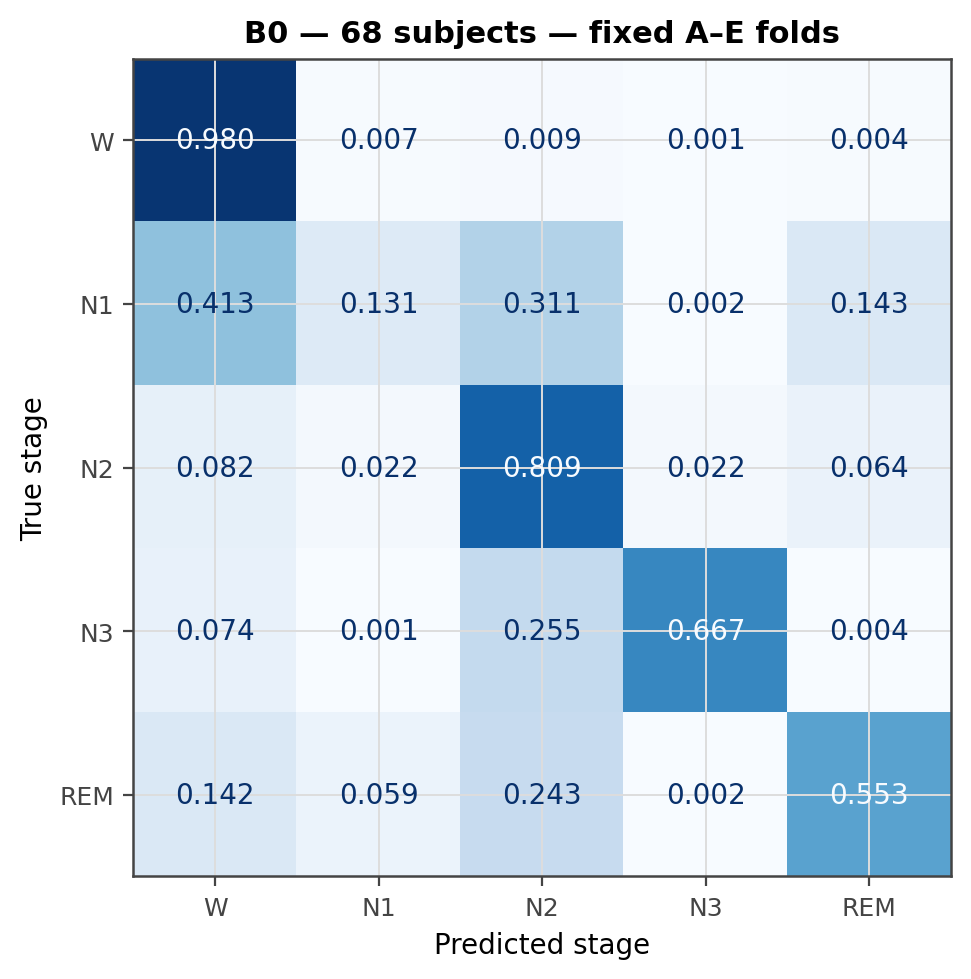

```text

MATRIZ PARA COPIAR PARA O GOOGLE SHEETS
True / Predicted	W	N1	N2	N3	REM
W	0.9797	0.0065	0.0090	0.0007	0.0041
N1	0.4131	0.1308	0.3115	0.0021	0.1425
N2	0.0824	0.0224	0.8093	0.0222	0.0637
N3	0.0737	0.0005	0.2555	0.6667	0.0036
REM	0.1417	0.0593	0.2433	0.0022	0.5535
```


```text
Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/B0_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/B0_68_fixed_AE_confusion.png
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 57
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
from adapter import cached

# O mesmo baseline original usado nos oito participantes.
track_b0_68 = SleepEDFTrack(cfg={})
B0_FEATURE_VERSION = 1

def preparar_b0_gravacao(psg):
    psg = Path(psg).resolve()

    assert psg.name[:5] in DEVELOPMENT_GROUPS_68

    marcacoes = sorted(
        psg.parent.glob(f"{psg.name[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1, f"Verificar marcações de {psg.name}"
    hyp = marcacoes[0]

    chave = {
        "version": B0_FEATURE_VERSION,
        "course_revision": COURSE_REVISION,
        "load": {"fs_target": 100.0, "epoch_s": 30.0},
        "preprocessing": "none",
        "features": "original_11_welch",
        "runtime": {
            nome: runtime_versions[nome]
            for nome in ("python", "numpy", "scipy", "mne")
        },
        "files": [
            (p.name, p.stat().st_size, p.stat().st_mtime_ns)
            for p in (psg, hyp)
        ],
    }

    def calcular():
        # Ligações temporárias aos EDF existentes, sem os copiar.
        with TemporaryDirectory() as temporaria:
            for origem in (psg, hyp):
                (Path(temporaria) / origem.name).symlink_to(
                    origem.resolve()
                )

            gravacoes = track_b0_68.load(
                temporaria, fs_target=100.0, epoch_s=30.0
            )
            assert len(gravacoes) == 1

            X, y, grupos = track_b0_68.build_dataset(gravacoes)

            assert X.shape == (len(y), 11)
            assert np.isfinite(X).all()

            return {
                "record": gravacoes[0].meta["record"],
                "X": X,
                "y": y,
                "groups": grupos,
                "feature_names": track_b0_68.feature_names(),
            }

    return cached(
        "viggy_b0_features",
        chave,
        calcular,
        CACHE_VIGGY,
    )

# Célula original 58
from time import perf_counter

# Selecionar apenas as gravações dos 68 participantes definidos.
ficheiros_b0_68 = sorted(
    p for p in TRAIN_DIR.rglob("*-PSG.edf")
    if p.name[:5] in DEVELOPMENT_GROUPS_68
)

assert len(ficheiros_b0_68) == 133
assert len({p.name for p in ficheiros_b0_68}) == 133
assert {p.name[:5] for p in ficheiros_b0_68} == set(
    DEVELOPMENT_GROUPS_68
)

nomes_features_b0 = track_b0_68.feature_names()

# Esta lista guarda apenas características, labels e identificadores.
b0_gravacoes_68 = []

inicio_preparacao_68 = perf_counter()

for numero, psg in enumerate(ficheiros_b0_68, start=1):
    inicio_gravacao = perf_counter()

    dados = preparar_b0_gravacao(psg)

    # Confirmar que cada resultado pertence à gravação esperada.
    assert dados["record"] == psg.name.removesuffix("-PSG.edf")
    assert set(dados["groups"]) == {psg.name[:5]}
    assert dados["feature_names"] == nomes_features_b0
    assert dados["X"].shape == (len(dados["y"]), 11)
    assert len(dados["groups"]) == len(dados["y"])

    b0_gravacoes_68.append(dados)

    segundos = perf_counter() - inicio_gravacao
    minutos_total = (
        perf_counter() - inicio_preparacao_68
    ) / 60

    print(
        f"[{numero:03d}/133] {dados['record']} | "
        f"{len(dados['y'])} épocas | "
        f"{segundos:.1f} s | "
        f"total: {minutos_total:.1f} min",
        flush=True,
    )

total_epocas_b0_68 = sum(
    len(dados["y"]) for dados in b0_gravacoes_68
)

print("\nPREPARAÇÃO CONCLUÍDA")
print("Participantes:", len(DEVELOPMENT_GROUPS_68))
print("Gravações:", len(b0_gravacoes_68))
print("Total de épocas:", total_epocas_b0_68)
print("Características por época:", len(nomes_features_b0))

# Célula original 59
import numpy as np
import pandas as pd

# Juntar apenas as características e os identificadores.
X_b0_68 = np.concatenate([
    dados["X"] for dados in b0_gravacoes_68
])

y_b0_68 = np.concatenate([
    dados["y"] for dados in b0_gravacoes_68
])

groups_b0_68 = np.concatenate([
    dados["groups"] for dados in b0_gravacoes_68
])

# Identificar a gravação de origem de cada época.
record_ids_b0_68 = np.concatenate([
    np.repeat(dados["record"], len(dados["y"]))
    for dados in b0_gravacoes_68
])

assert X_b0_68.shape == (360621, 11)
assert len(y_b0_68) == len(groups_b0_68) == len(record_ids_b0_68)
assert set(groups_b0_68) == set(DEVELOPMENT_GROUPS_68)
assert not (set(groups_b0_68) & HOLDOUT_GROUPS)
assert np.isfinite(X_b0_68).all()

# Guardar os índices de treino e teste definidos pelas listas A–E.
SPLITS_68 = {}
resumo_folds = []
vezes_em_teste = np.zeros(len(y_b0_68), dtype=np.uint8)

for fold, participantes_teste in FOLDS_68.items():
    mascara_teste = np.isin(groups_b0_68, participantes_teste)

    treino = np.flatnonzero(~mascara_teste)
    teste = np.flatnonzero(mascara_teste)

    sujeitos_treino = set(groups_b0_68[treino])
    sujeitos_teste = set(groups_b0_68[teste])

    assert sujeitos_teste == set(participantes_teste)
    assert sujeitos_treino.isdisjoint(sujeitos_teste)

    SPLITS_68[fold] = (treino, teste)
    vezes_em_teste[teste] += 1

    resumo_folds.append({
        "Fold": fold,
        "Participantes treino": len(sujeitos_treino),
        "Participantes teste": len(sujeitos_teste),
        "Épocas treino": len(treino),
        "Épocas teste": len(teste),
    })

# Cada época deve aparecer no teste exatamente uma vez.
assert np.all(vezes_em_teste == 1)

print("Dados do baseline:", X_b0_68.shape)
display(pd.DataFrame(resumo_folds).set_index("Fold"))
print("Divisão A–E preparada e verificada.")

# Célula original 61
from sklearn.base import clone

# Modelo de referência: cada fold recebe uma cópia nova.
modelo_base_b0 = track_b0_68.baseline()
modelo_base_b0.set_params(clf__n_jobs=-1)

# Informação comum aos cinco resultados.
meta_b0_68 = {
    "experiment": "B0_68_fixed_AE",
    "course_revision": COURSE_REVISION,
    "runtime": runtime_versions,
    "feature_version": B0_FEATURE_VERSION,
    "feature_names": nomes_features_b0,
    "fold_assignment": FOLDS_68,
    "recordings": [
        {"record": d["record"], "epochs": len(d["y"])}
        for d in b0_gravacoes_68
    ],
    "classifier_params": modelo_base_b0.named_steps["clf"].get_params(),
    "scaler_params": modelo_base_b0.named_steps["scale"].get_params(),
}

resultados_b0_68 = {}

for fold in "ABCDE":
    treino, teste = SPLITS_68[fold]
    destino = EXPERIMENTS_DIR / f"B0_68_fixed_AE_fold_{fold}.json"

    if destino.exists():
        resultado = json.loads(destino.read_text(encoding="utf-8"))

        # Reutilizar apenas resultados com os mesmos dados e configuração.
        assert resultado["fold"] == fold
        for campo, valor in meta_b0_68.items():
            assert resultado[campo] == valor, (
                f"Fold {fold}: configuração diferente em {campo}."
            )

        np.testing.assert_array_equal(
            resultado["test_indices"], teste
        )
        np.testing.assert_array_equal(
            resultado["report"]["y_true"], y_b0_68[teste]
        )
        np.testing.assert_array_equal(
            resultado["report"]["y_group"], groups_b0_68[teste]
        )

        print(f"Fold {fold}: resultado guardado reutilizado.",
              flush=True)

    else:
        print(f"\nFold {fold}: a treinar...", flush=True)

        modelo = clone(modelo_base_b0)

        inicio = perf_counter()
        modelo.fit(X_b0_68[treino], y_b0_68[treino])
        tempo_treino = perf_counter() - inicio

        inicio = perf_counter()
        previsoes = modelo.predict(X_b0_68[teste])
        tempo_previsao = perf_counter() - inicio

        relatorio = track_b0_68._make_report(
            y_b0_68[teste],
            previsoes,
            groups=groups_b0_68[teste],
        )

        resultado = {
            **meta_b0_68,
            "fold": fold,
            "training_subjects": sorted(set(groups_b0_68[treino])),
            "test_subjects": sorted(set(groups_b0_68[teste])),
            "test_indices": teste,
            "fit_seconds": tempo_treino,
            "predict_seconds": tempo_previsao,
            "report": relatorio,
        }

        # Escrever primeiro um ficheiro temporário.
        temporario = destino.with_suffix(".tmp")
        temporario.write_text(
            json.dumps(
                resultado, default=converter_numpy, indent=2
            ),
            encoding="utf-8",
        )
        temporario.replace(destino)

        print(
            f"Fold {fold} concluído: "
            f"kappa = {relatorio['cohens_kappa']:.3f} | "
            f"treino = {tempo_treino / 60:.2f} min",
            flush=True,
        )

    resultados_b0_68[fold] = resultado

# Resumir os cinco folds.
tabela_b0_68 = pd.DataFrame([
    {
        "Fold": fold,
        **{
            metrica: resultado["report"][metrica]
            for metrica in [
                "cohens_kappa", "macro_f1",
                "accuracy", "balanced_accuracy"
            ]
        },
        "Treino (min)": resultado["fit_seconds"] / 60,
    }
    for fold, resultado in resultados_b0_68.items()
]).set_index("Fold")

print("\nBASELINE — CINCO FOLDS CONCLUÍDOS")
display(tabela_b0_68.round(3))

kappas = tabela_b0_68["cohens_kappa"]
print(
    f"Kappa médio ± SD entre os cinco folds: "
    f"{kappas.mean():.3f} ± {kappas.std(ddof=1):.3f}"
)

# Célula original 62
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

estagios = ["W", "N1", "N2", "N3", "REM"]

# Colocar cada previsão na posição da sua época original.
previsoes_b0_68 = np.empty_like(y_b0_68)
fold_por_epoca_b0_68 = np.empty(len(y_b0_68), dtype="<U1")
cobertura_b0_68 = np.zeros(len(y_b0_68), dtype=np.uint8)

for fold, resultado in resultados_b0_68.items():
    indices = np.asarray(resultado["test_indices"], dtype=int)
    relatorio = resultado["report"]

    np.testing.assert_array_equal(
        indices, SPLITS_68[fold][1]
    )
    np.testing.assert_array_equal(
        relatorio["y_true"], y_b0_68[indices]
    )
    np.testing.assert_array_equal(
        relatorio["y_group"], groups_b0_68[indices]
    )

    assert len(relatorio["y_pred"]) == len(indices)
    assert np.all(cobertura_b0_68[indices] == 0)

    previsoes_b0_68[indices] = relatorio["y_pred"]
    fold_por_epoca_b0_68[indices] = fold
    cobertura_b0_68[indices] += 1

assert np.all(cobertura_b0_68 == 1)

# Relatório conjunto, incluindo resultados por fold e participante.
relatorio_b0_68 = track_b0_68._make_report(
    y_b0_68,
    previsoes_b0_68,
    groups=groups_b0_68,
    folds=fold_por_epoca_b0_68,
)

print("BASELINE — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]:
    print(f"{metrica}: {relatorio_b0_68[metrica]:.3f}")

print("\nRESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_b0_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Matriz conjunta: cada linha soma 1.
cm_b0_68 = confusion_matrix(
    y_b0_68, previsoes_b0_68, labels=estagios
)
cm_b0_68_normalizada = (
    cm_b0_68 / cm_b0_68.sum(axis=1, keepdims=True)
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    cm_b0_68_normalizada,
    display_labels=estagios,
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=False,
    im_kw={"vmin": 0, "vmax": 1},
)

ax.set_title("B0 — 68 subjects — fixed A–E folds")
ax.set_xlabel("Predicted stage")
ax.set_ylabel("True stage")
plt.tight_layout()
plt.show()

# Valores para copiar para a folha da equipa.
tabela_cm_b0_68 = pd.DataFrame(
    cm_b0_68_normalizada,
    index=estagios,
    columns=estagios,
)
tabela_cm_b0_68.index.name = "True / Predicted"

print("\nMATRIZ PARA COPIAR PARA O GOOGLE SHEETS")
print(tabela_cm_b0_68.to_csv(
    sep="\t", float_format="%.4f"
))

# Célula original 63
metricas = [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]

resumo_folds_b0_68 = {
    metrica: {
        "mean": tabela_b0_68[metrica].mean(),
        "std": tabela_b0_68[metrica].std(ddof=1),
        "n": 5,
        "ddof": 1,
    }
    for metrica in metricas
}

consolidado_b0_68 = {
    **meta_b0_68,
    "cv_method": "fixed_subject_5fold_AE",
    "preprocessing": "no additional filtering",
    "spectral_method": "welch",
    "training_crop": False,
    "evaluation_scope": "all original valid epochs, including Wake",
    "fold_metric_summary": resumo_folds_b0_68,
    "fit_seconds_total": sum(
        r["fit_seconds"] for r in resultados_b0_68.values()
    ),
    "report": relatorio_b0_68,
}

destino = EXPERIMENTS_DIR / "B0_68_fixed_AE.json"
temporario = destino.with_suffix(".tmp")

temporario.write_text(
    json.dumps(
        consolidado_b0_68,
        default=converter_numpy,
        indent=2,
    ),
    encoding="utf-8",
)
temporario.replace(destino)

imagem = EXPERIMENTS_DIR / "B0_68_fixed_AE_confusion.png"
fig.savefig(imagem, dpi=200, bbox_inches="tight")

print("Relatório guardado:", destino)
print("Imagem guardada:", imagem)
```

</details>

### 3.2 — F2: potências absolutas e relativas

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

```text
Baseline: (360621, 11)
F2: (360621, 16)
F2 preparado para usar as mesmas labels e os mesmos folds A–E.
```


```text

F2_68_fixed_AE — fold A: a treinar...
Fold A concluído: kappa = 0.753 | treino = 9.23 min

F2_68_fixed_AE — fold B: a treinar...
Fold B concluído: kappa = 0.718 | treino = 9.08 min

F2_68_fixed_AE — fold C: a treinar...
Fold C concluído: kappa = 0.739 | treino = 9.25 min

F2_68_fixed_AE — fold D: a treinar...
Fold D concluído: kappa = 0.717 | treino = 9.35 min

F2_68_fixed_AE — fold E: a treinar...
Fold E concluído: kappa = 0.748 | treino = 9.36 min

F2 — CINCO FOLDS CONCLUÍDOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>cohens_kappa</th>
      <th>macro_f1</th>
      <th>accuracy</th>
      <th>balanced_accuracy</th>
      <th>Treino (min)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.753</td>
      <td>0.679</td>
      <td>0.885</td>
      <td>0.676</td>
      <td>9.232</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.718</td>
      <td>0.647</td>
      <td>0.862</td>
      <td>0.636</td>
      <td>9.083</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.739</td>
      <td>0.652</td>
      <td>0.878</td>
      <td>0.622</td>
      <td>9.248</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.717</td>
      <td>0.638</td>
      <td>0.875</td>
      <td>0.598</td>
      <td>9.350</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.748</td>
      <td>0.673</td>
      <td>0.879</td>
      <td>0.653</td>
      <td>9.364</td>
    </tr>
  </tbody>
</table>

```text
Kappa médio ± SD entre os cinco folds: 0.735 ± 0.017

COMPARAÇÃO DO KAPPA NOS MESMOS FOLDS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>B0</th>
      <th>F2</th>
      <th>Diferença</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.743</td>
      <td>0.753</td>
      <td>0.010</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.716</td>
      <td>0.718</td>
      <td>0.002</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.730</td>
      <td>0.739</td>
      <td>0.009</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.715</td>
      <td>0.717</td>
      <td>0.002</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.737</td>
      <td>0.748</td>
      <td>0.011</td>
    </tr>
  </tbody>
</table>

```text
F2 — MÉTRICAS GLOBAIS
cohens_kappa: 0.735
macro_f1: 0.659
accuracy: 0.876
balanced_accuracy: 0.638

F2 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.939     0.980     0.959    248341
          N1      0.351     0.135     0.195     17877
          N2      0.761     0.813     0.786     60494
          N3      0.838     0.681     0.751     11610
         REM      0.631     0.581     0.605     22299

    accuracy                          0.876    360621
   macro avg      0.704     0.638     0.659    360621
weighted avg      0.857     0.876     0.863    360621


COMPARAÇÃO POR ESTÁGIO
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Recall B0</th>
      <th>Recall F2</th>
      <th>F1 B0</th>
      <th>F1 F2</th>
      <th>Diferença F1</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>0.980</td>
      <td>0.980</td>
      <td>0.958</td>
      <td>0.959</td>
      <td>0.001</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>0.131</td>
      <td>0.135</td>
      <td>0.191</td>
      <td>0.195</td>
      <td>0.004</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>0.809</td>
      <td>0.813</td>
      <td>0.779</td>
      <td>0.786</td>
      <td>0.007</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>0.667</td>
      <td>0.681</td>
      <td>0.739</td>
      <td>0.751</td>
      <td>0.012</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>0.553</td>
      <td>0.581</td>
      <td>0.586</td>
      <td>0.605</td>
      <td>0.019</td>
    </tr>
  </tbody>
</table>

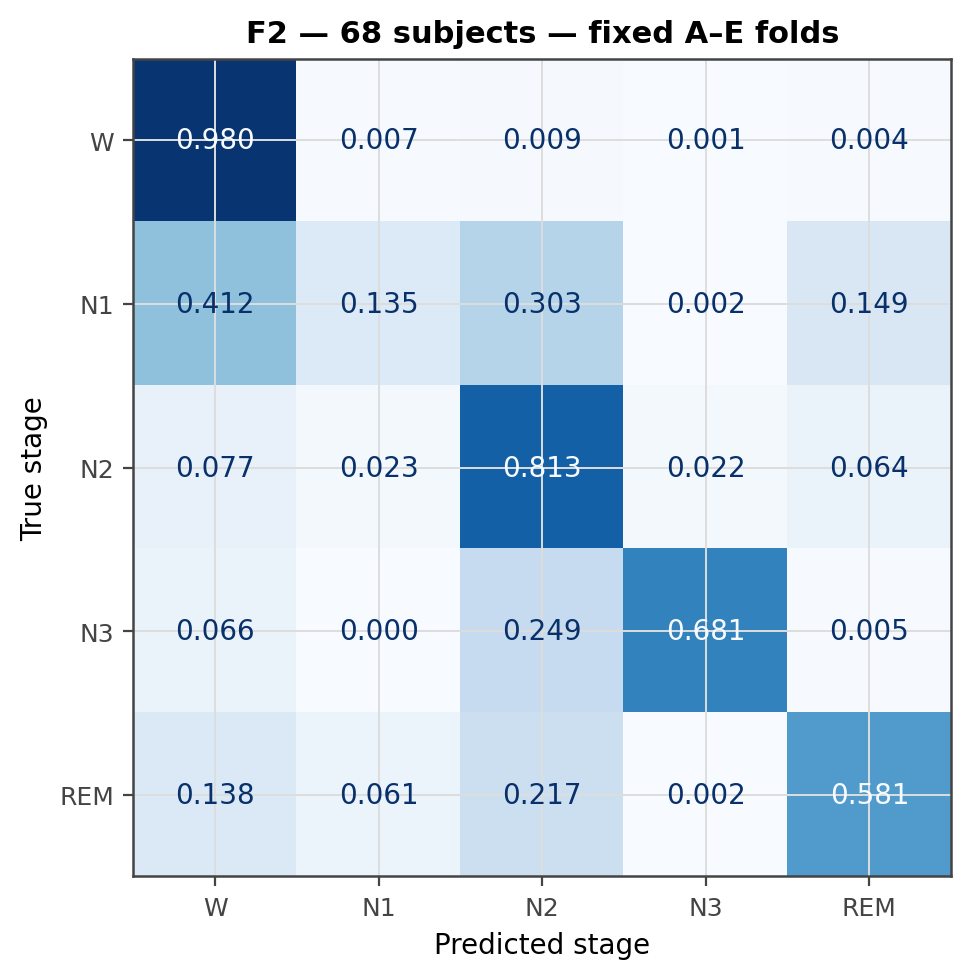

```text
Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/F2_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/F2_68_fixed_AE_confusion.png
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 64
F2_FEATURE_VERSION = 1

bandas_f2_68 = ["delta", "theta", "alpha", "sigma", "beta"]

indices_bandas_f2_68 = [
    nomes_features_b0.index(f"eeg_{banda}")
    for banda in bandas_f2_68
]

potencias = X_b0_68[:, indices_bandas_f2_68]

assert np.isfinite(potencias).all()
assert (potencias >= 0).all()

# Proporção de potência em cada uma das cinco bandas.
total = potencias.sum(axis=1, keepdims=True)

relativas = np.divide(
    potencias,
    total,
    out=np.zeros_like(potencias, dtype=float),
    where=total > 0,
)

# Manter as 11 características e acrescentar as cinco relativas.
X_f2_68 = np.column_stack([X_b0_68, relativas])

nomes_features_f2_68 = nomes_features_b0 + [
    f"eeg_{banda}_relative"
    for banda in bandas_f2_68
]

assert X_f2_68.shape == (len(y_b0_68), 16)
assert np.isfinite(X_f2_68).all()

print("Baseline:", X_b0_68.shape)
print("F2:", X_f2_68.shape)
print("F2 preparado para usar as mesmas labels e os mesmos folds A–E.")

# Célula original 65
from sklearn.base import clone

def avaliar_experiencia_68(
    nome, X, nomes_features, versao_features, detalhes=None
):
    assert X.shape == (len(y_b0_68), len(nomes_features))
    assert np.isfinite(X).all()

    modelo_base = clone(modelo_base_b0)

    meta = {
        **meta_b0_68,
        "experiment": nome,
        "feature_version": versao_features,
        "feature_names": list(nomes_features),
        "classifier_params": modelo_base.named_steps["clf"].get_params(),
        "scaler_params": modelo_base.named_steps["scale"].get_params(),
    }
    if detalhes is not None:
        meta["details"] = detalhes

    resultados = {}

    for fold in "ABCDE":
        treino, teste = SPLITS_68[fold]

        # Confirmar que estamos a comparar com o mesmo teste do B0.
        np.testing.assert_array_equal(
            teste,
            resultados_b0_68[fold]["test_indices"],
        )
        assert set(groups_b0_68[teste]) == set(FOLDS_68[fold])
        assert set(groups_b0_68[treino]).isdisjoint(
            set(groups_b0_68[teste])
        )

        destino = EXPERIMENTS_DIR / f"{nome}_fold_{fold}.json"

        if destino.exists():
            resultado = json.loads(
                destino.read_text(encoding="utf-8")
            )

            assert resultado["fold"] == fold
            for campo, valor in meta.items():
                assert resultado[campo] == valor, (
                    f"Fold {fold}: configuração diferente em {campo}."
                )

            np.testing.assert_array_equal(
                resultado["test_indices"], teste
            )
            np.testing.assert_array_equal(
                resultado["report"]["y_true"], y_b0_68[teste]
            )
            np.testing.assert_array_equal(
                resultado["report"]["y_group"], groups_b0_68[teste]
            )

            print(f"{nome} — fold {fold}: reutilizado.", flush=True)

        else:
            print(
                f"\n{nome} — fold {fold}: a treinar...",
                flush=True,
            )

            # Scaler e classificador novos em cada fold.
            modelo = clone(modelo_base)

            inicio = perf_counter()
            modelo.fit(X[treino], y_b0_68[treino])
            tempo_treino = perf_counter() - inicio

            inicio = perf_counter()
            previsoes = modelo.predict(X[teste])
            tempo_previsao = perf_counter() - inicio

            relatorio = track_b0_68._make_report(
                y_b0_68[teste],
                previsoes,
                groups=groups_b0_68[teste],
            )

            resultado = {
                **meta,
                "fold": fold,
                "training_subjects": sorted(set(groups_b0_68[treino])),
                "test_subjects": sorted(set(groups_b0_68[teste])),
                "test_indices": teste,
                "fit_seconds": tempo_treino,
                "predict_seconds": tempo_previsao,
                "report": relatorio,
            }

            temporario = destino.with_suffix(".tmp")
            temporario.write_text(
                json.dumps(
                    resultado,
                    default=converter_numpy,
                    indent=2,
                ),
                encoding="utf-8",
            )
            temporario.replace(destino)

            print(
                f"Fold {fold} concluído: "
                f"kappa = {relatorio['cohens_kappa']:.3f} | "
                f"treino = {tempo_treino / 60:.2f} min",
                flush=True,
            )

        resultados[fold] = resultado

    tabela = pd.DataFrame([
        {
            "Fold": fold,
            **{
                metrica: resultado["report"][metrica]
                for metrica in [
                    "cohens_kappa", "macro_f1",
                    "accuracy", "balanced_accuracy",
                ]
            },
            "Treino (min)": resultado["fit_seconds"] / 60,
        }
        for fold, resultado in resultados.items()
    ]).set_index("Fold")

    return resultados, tabela


# Avaliar F2.
resultados_f2_68, tabela_f2_68 = avaliar_experiencia_68(
    nome="F2_68_fixed_AE",
    X=X_f2_68,
    nomes_features=nomes_features_f2_68,
    versao_features=F2_FEATURE_VERSION,
    detalhes={
        "base_feature_version": B0_FEATURE_VERSION,
        "relative_bands": bandas_f2_68,
        "denominator": "sum of the five EEG band powers",
        "normalization_scope": "each epoch independently",
    },
)

print("\nF2 — CINCO FOLDS CONCLUÍDOS")
display(tabela_f2_68.round(3))

kappas_f2 = tabela_f2_68["cohens_kappa"]
print(
    f"Kappa médio ± SD entre os cinco folds: "
    f"{kappas_f2.mean():.3f} ± {kappas_f2.std(ddof=1):.3f}"
)

comparacao_b0_f2_68 = pd.DataFrame({
    "B0": tabela_b0_68["cohens_kappa"],
    "F2": tabela_f2_68["cohens_kappa"],
})
comparacao_b0_f2_68["Diferença"] = (
    comparacao_b0_f2_68["F2"] - comparacao_b0_f2_68["B0"]
)

print("\nCOMPARAÇÃO DO KAPPA NOS MESMOS FOLDS")
display(comparacao_b0_f2_68.round(3))

# Célula original 66
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)

# Função reutilizável para juntar as previsões dos cinco folds.
def juntar_previsoes_68(resultados):
    assert set(resultados) == set("ABCDE")

    previsoes = np.empty_like(y_b0_68)
    folds = np.empty(len(y_b0_68), dtype="<U1")
    cobertura = np.zeros(len(y_b0_68), dtype=np.uint8)

    for fold, resultado in resultados.items():
        indices = np.asarray(resultado["test_indices"], dtype=int)
        relatorio = resultado["report"]

        np.testing.assert_array_equal(
            indices, SPLITS_68[fold][1]
        )
        np.testing.assert_array_equal(
            relatorio["y_true"], y_b0_68[indices]
        )
        np.testing.assert_array_equal(
            relatorio["y_group"], groups_b0_68[indices]
        )

        assert len(relatorio["y_pred"]) == len(indices)
        assert np.all(cobertura[indices] == 0)

        previsoes[indices] = relatorio["y_pred"]
        folds[indices] = fold
        cobertura[indices] += 1

    assert np.all(cobertura == 1)

    relatorio = track_b0_68._make_report(
        y_b0_68,
        previsoes,
        groups=groups_b0_68,
        folds=folds,
    )

    return previsoes, relatorio


previsoes_f2_68, relatorio_f2_68 = juntar_previsoes_68(
    resultados_f2_68
)

estagios = ["W", "N1", "N2", "N3", "REM"]

print("F2 — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]:
    print(f"{metrica}: {relatorio_f2_68[metrica]:.3f}")

print("\nF2 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Comparação direta com o baseline.
classes_b0 = classification_report(
    y_b0_68, previsoes_b0_68,
    labels=estagios, output_dict=True, zero_division=0,
)
classes_f2 = classification_report(
    y_b0_68, previsoes_f2_68,
    labels=estagios, output_dict=True, zero_division=0,
)

comparacao_estagios_b0_f2_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall B0": classes_b0[estagio]["recall"],
        "Recall F2": classes_f2[estagio]["recall"],
        "F1 B0": classes_b0[estagio]["f1-score"],
        "F1 F2": classes_f2[estagio]["f1-score"],
        "Diferença F1": (
            classes_f2[estagio]["f1-score"]
            - classes_b0[estagio]["f1-score"]
        ),
    }
    for estagio in estagios
]).set_index("Estágio")

print("\nCOMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_b0_f2_68.round(3))

# Matriz de confusão com a mesma escala usada no baseline.
fig_f2_68, ax_f2_68 = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    im_kw={"vmin": 0, "vmax": 1},
    ax=ax_f2_68,
)

ax_f2_68.set_title("F2 — 68 subjects — fixed A–E folds")
ax_f2_68.set_xlabel("Predicted stage")
ax_f2_68.set_ylabel("True stage")
plt.tight_layout()
plt.show()

# Célula original 67
# Separar a informação comum da informação específica do fold A.
campos_do_fold = {
    "fold", "training_subjects", "test_subjects",
    "test_indices", "fit_seconds", "predict_seconds", "report",
}

meta_f2_68 = {
    campo: valor
    for campo, valor in resultados_f2_68["A"].items()
    if campo not in campos_do_fold
}

consolidado_f2_68 = {
    **meta_f2_68,
    "cv_method": "fixed_subject_5fold_AE",
    "preprocessing": "no additional filtering",
    "spectral_method": "welch",
    "training_crop": False,
    "evaluation_scope": "all original valid epochs, including Wake",
    "fold_metric_summary": {
        metrica: {
            "mean": tabela_f2_68[metrica].mean(),
            "std": tabela_f2_68[metrica].std(ddof=1),
            "n": 5,
            "ddof": 1,
        }
        for metrica in [
            "cohens_kappa", "macro_f1",
            "accuracy", "balanced_accuracy",
        ]
    },
    "fit_seconds_total": sum(
        r["fit_seconds"] for r in resultados_f2_68.values()
    ),
    "report": relatorio_f2_68,
}

destino_f2 = EXPERIMENTS_DIR / "F2_68_fixed_AE.json"
temporario_f2 = destino_f2.with_suffix(".tmp")

temporario_f2.write_text(
    json.dumps(
        consolidado_f2_68,
        default=converter_numpy,
        indent=2,
    ),
    encoding="utf-8",
)
temporario_f2.replace(destino_f2)

imagem_f2 = EXPERIMENTS_DIR / "F2_68_fixed_AE_confusion.png"
fig_f2_68.savefig(imagem_f2, dpi=200, bbox_inches="tight")

print("Relatório guardado:", destino_f2)
print("Imagem guardada:", imagem_f2)
```

</details>

### 3.3 — Inspeção de sinais e espectros

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Perfil</th>
      <th>Participante</th>
      <th>Kappa F2</th>
      <th>Gravação</th>
      <th>Épocas</th>
      <th>Épocas N1</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Kappa mais baixo</td>
      <td>SC461</td>
      <td>0.241</td>
      <td>SC4611E0</td>
      <td>2644</td>
      <td>123</td>
    </tr>
    <tr>
      <th>1</th>
      <td>Kappa intermédio</td>
      <td>SC453</td>
      <td>0.763</td>
      <td>SC4531E0</td>
      <td>2602</td>
      <td>124</td>
    </tr>
    <tr>
      <th>2</th>
      <td>Kappa mais alto</td>
      <td>SC414</td>
      <td>0.905</td>
      <td>SC4141E0</td>
      <td>2756</td>
      <td>29</td>
    </tr>
  </tbody>
</table>

```text
Gravação: SC4611E0 | Épocas: 2644
Épocas com NaN/Inf: 0
Épocas completamente constantes: 0
```


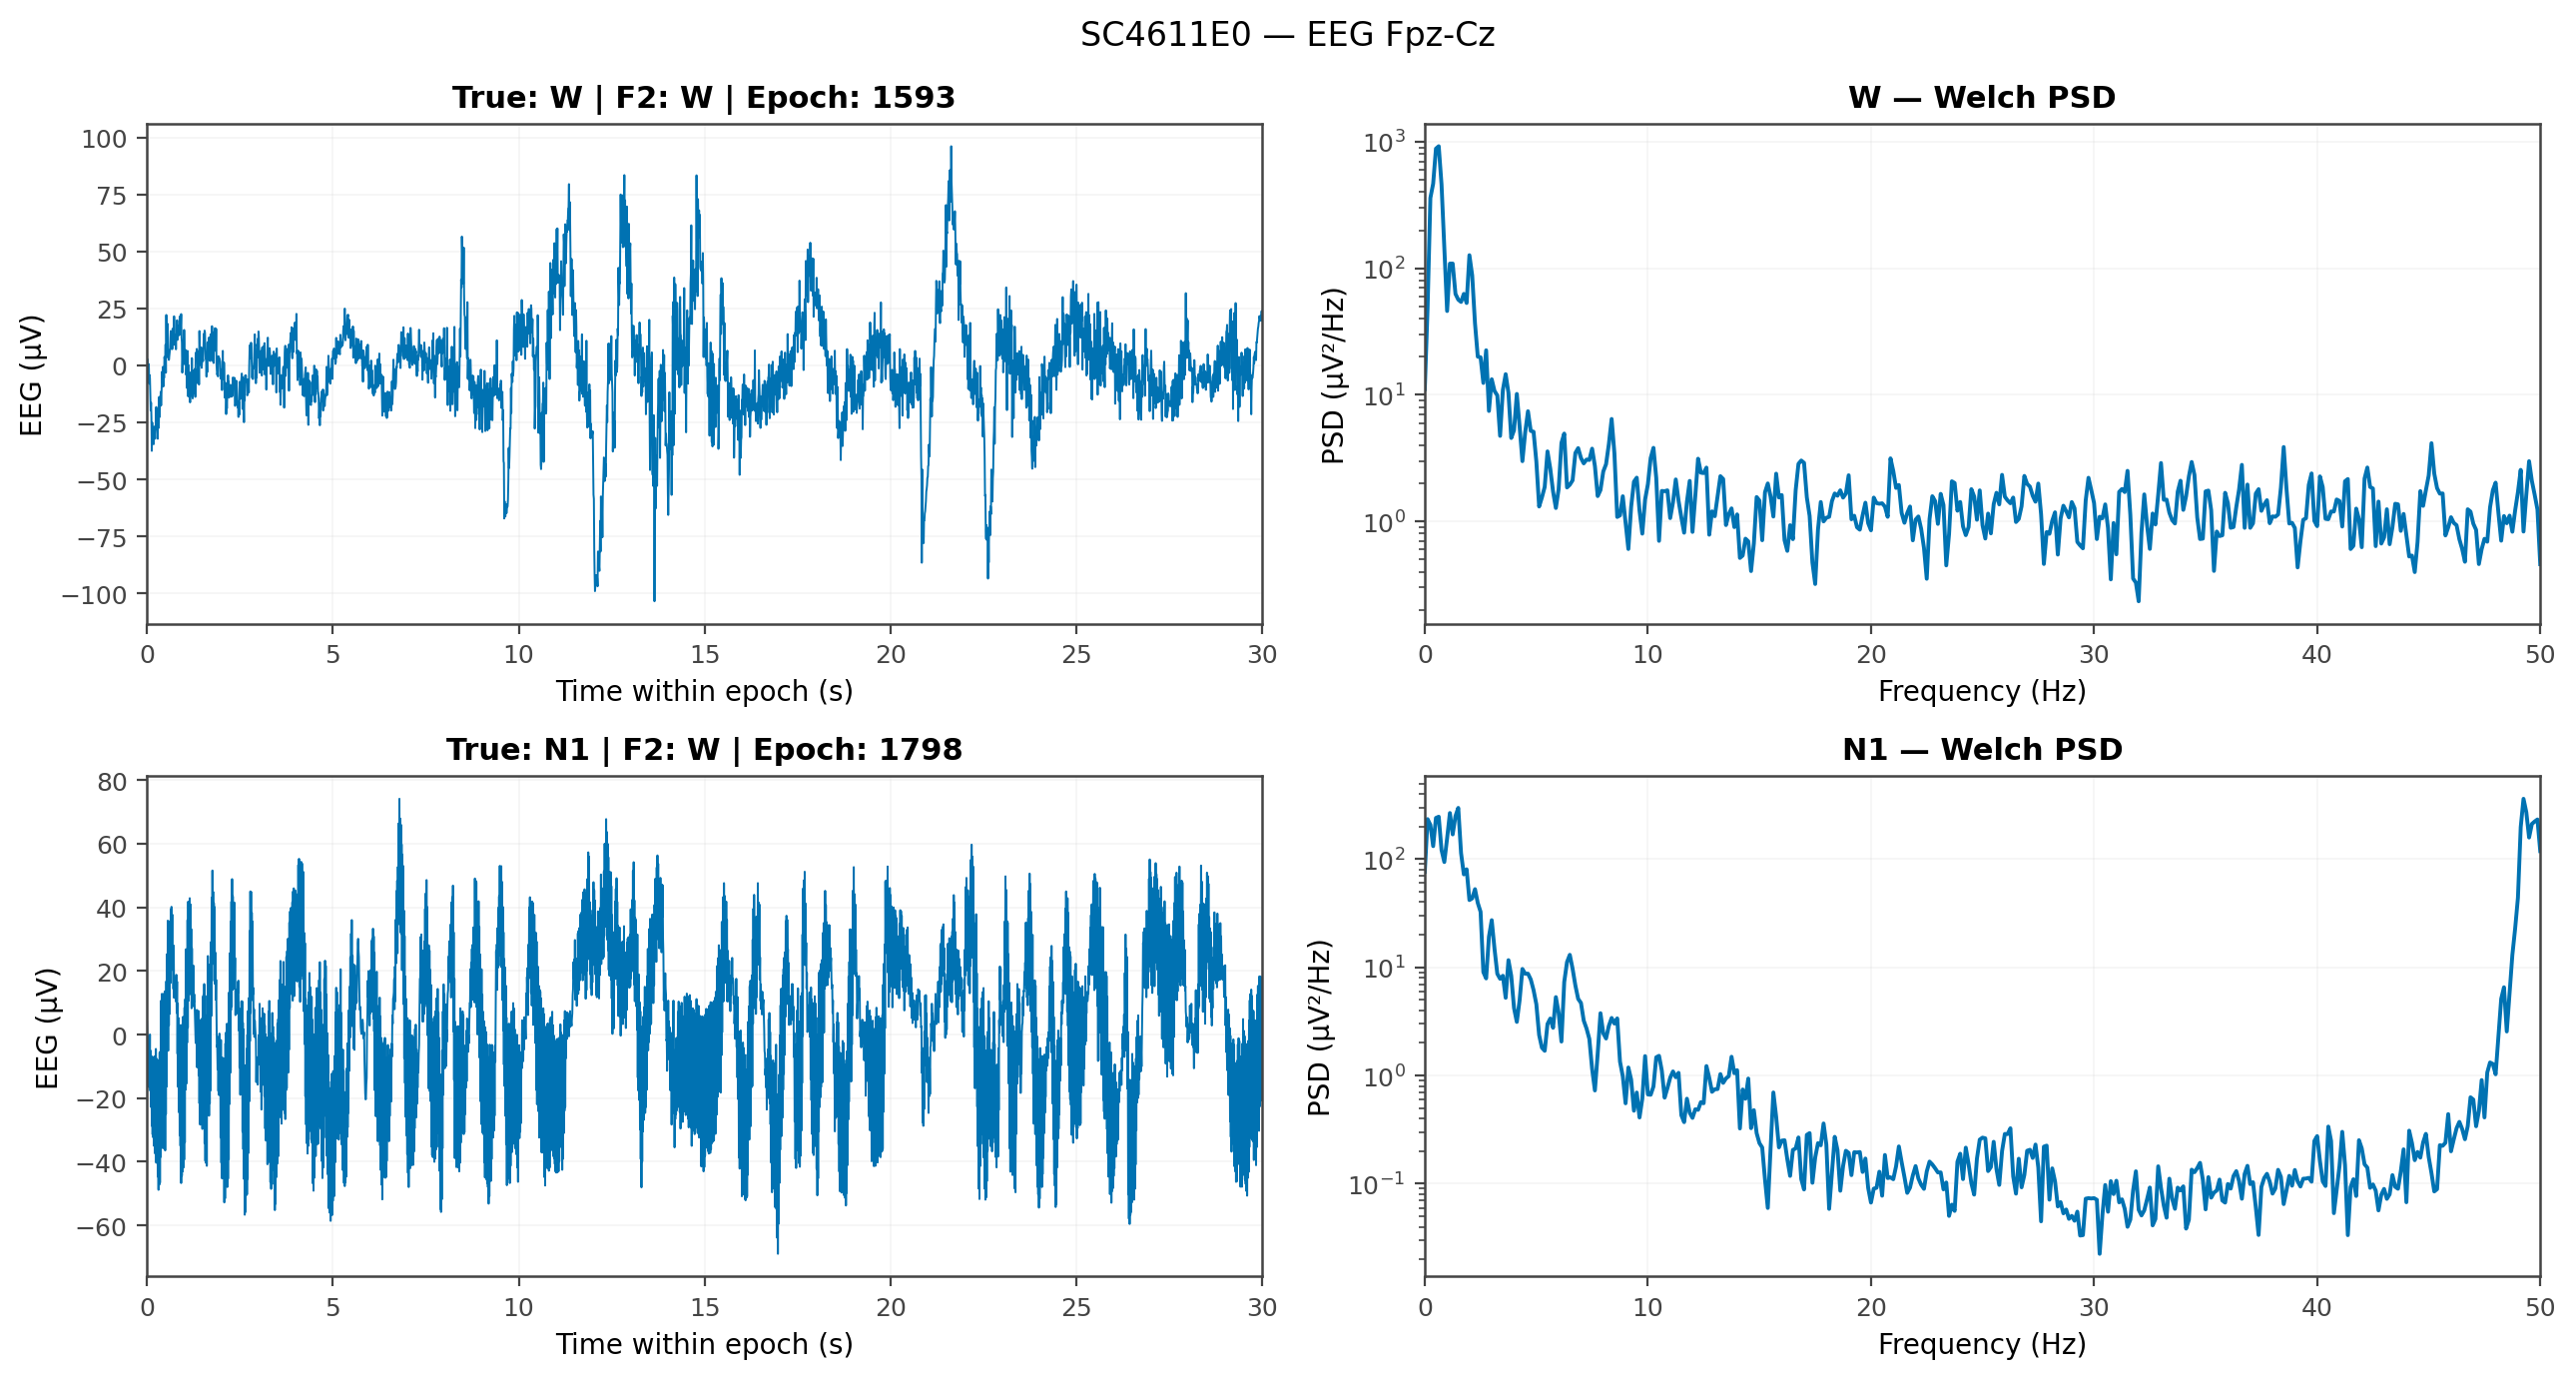

<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Estágio real</th>
      <th>Época retida</th>
      <th>Previsão F2</th>
      <th>Pico-a-pico (µV)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>W</td>
      <td>1593</td>
      <td>W</td>
      <td>199.789</td>
    </tr>
    <tr>
      <th>1</th>
      <td>N1</td>
      <td>1798</td>
      <td>W</td>
      <td>143.024</td>
    </tr>
  </tbody>
</table>

```text
Percentagem da potência de 0,5–50 Hz situada em 48–50 Hz:
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Épocas</th>
      <th>Mediana 48–50 Hz (%)</th>
      <th>P95 48–50 Hz (%)</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>1707</td>
      <td>1.06</td>
      <td>16.68</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>123</td>
      <td>48.47</td>
      <td>90.68</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>276</td>
      <td>44.61</td>
      <td>88.43</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>139</td>
      <td>29.54</td>
      <td>80.43</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>399</td>
      <td>49.45</td>
      <td>63.34</td>
    </tr>
  </tbody>
</table>

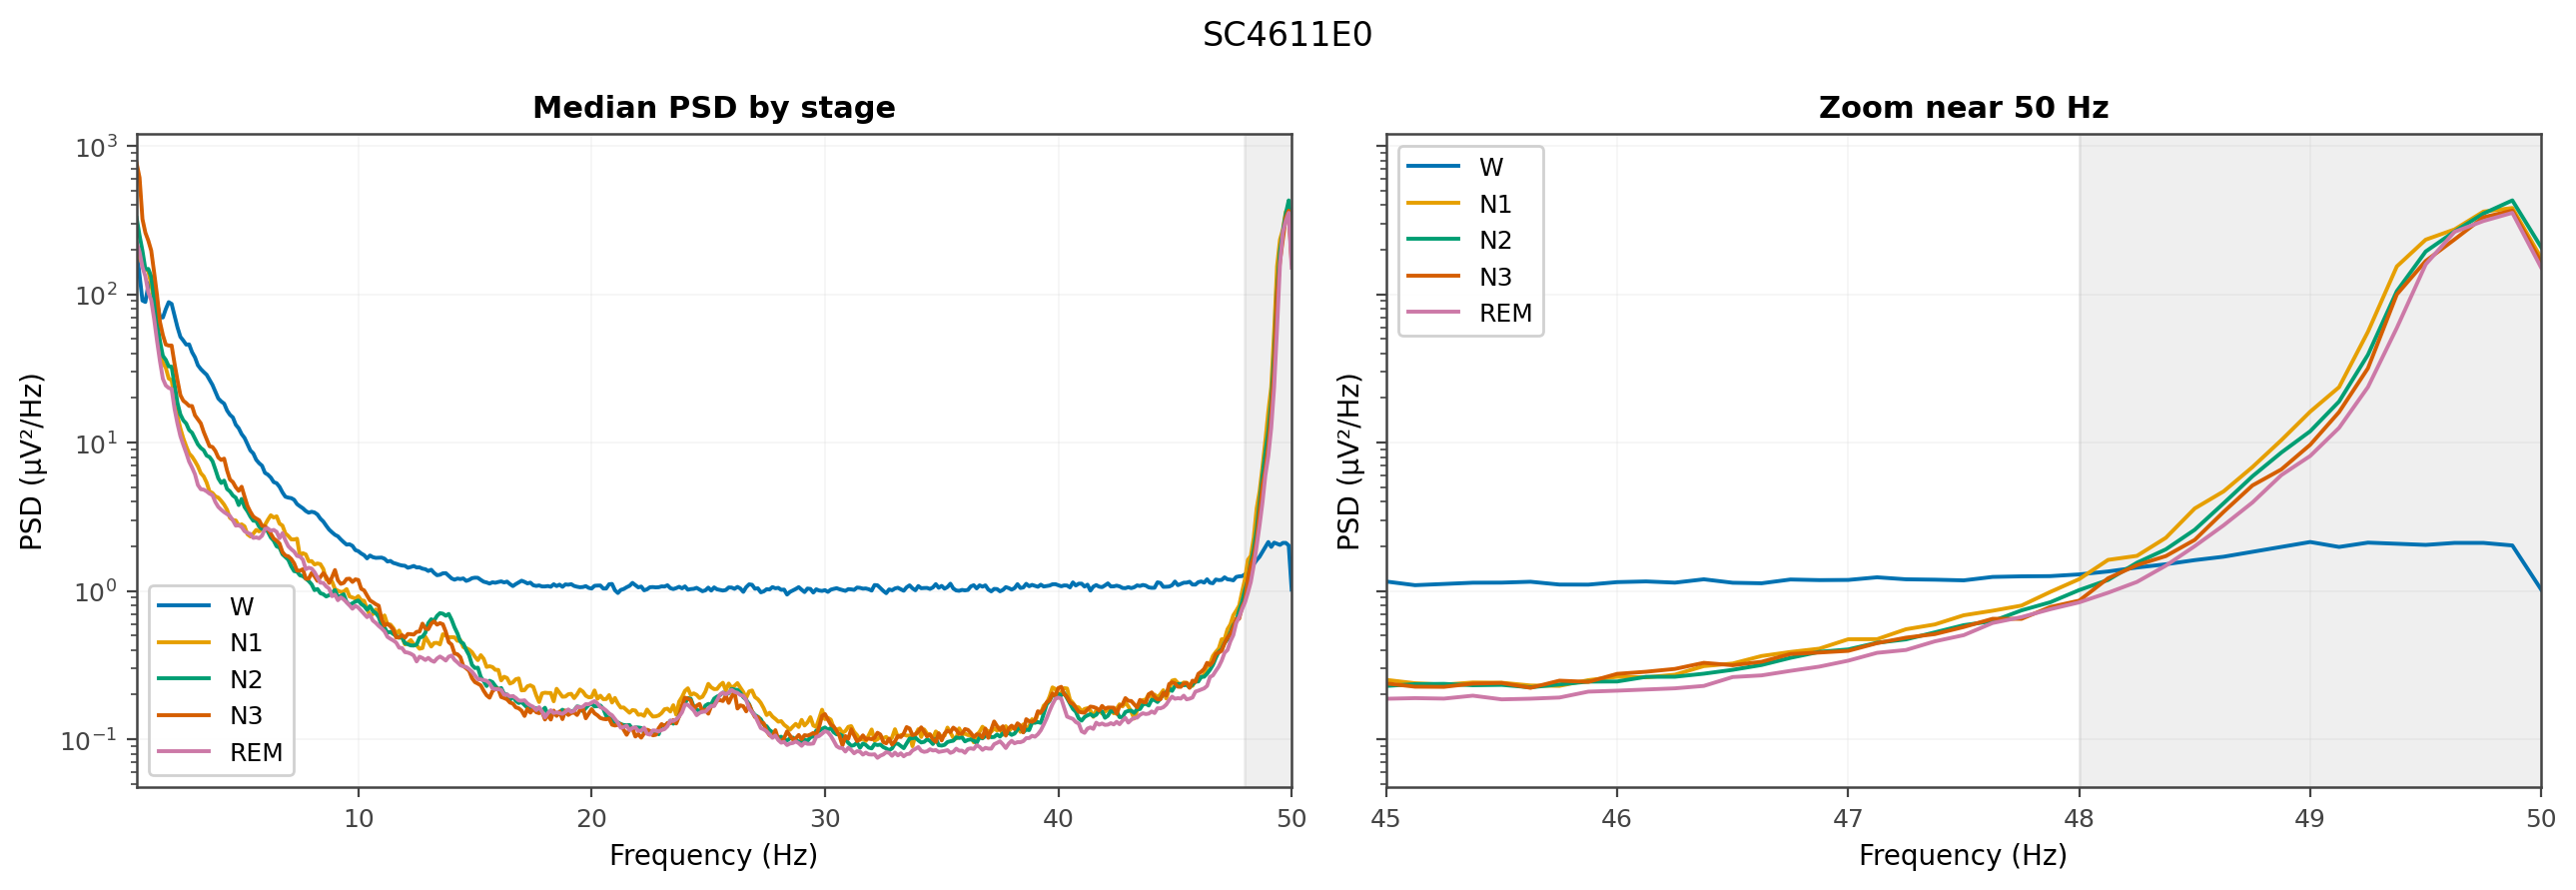

```text

Kappa intermédio | SC453 | Gravação: SC4531E0
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Épocas</th>
      <th>Mediana 48–50 Hz (%)</th>
      <th>P95 48–50 Hz (%)</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>1748</td>
      <td>1.69</td>
      <td>4.57</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>124</td>
      <td>2.57</td>
      <td>9.36</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>465</td>
      <td>1.05</td>
      <td>5.45</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>85</td>
      <td>1.56</td>
      <td>3.33</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>180</td>
      <td>1.59</td>
      <td>13.41</td>
    </tr>
  </tbody>
</table>

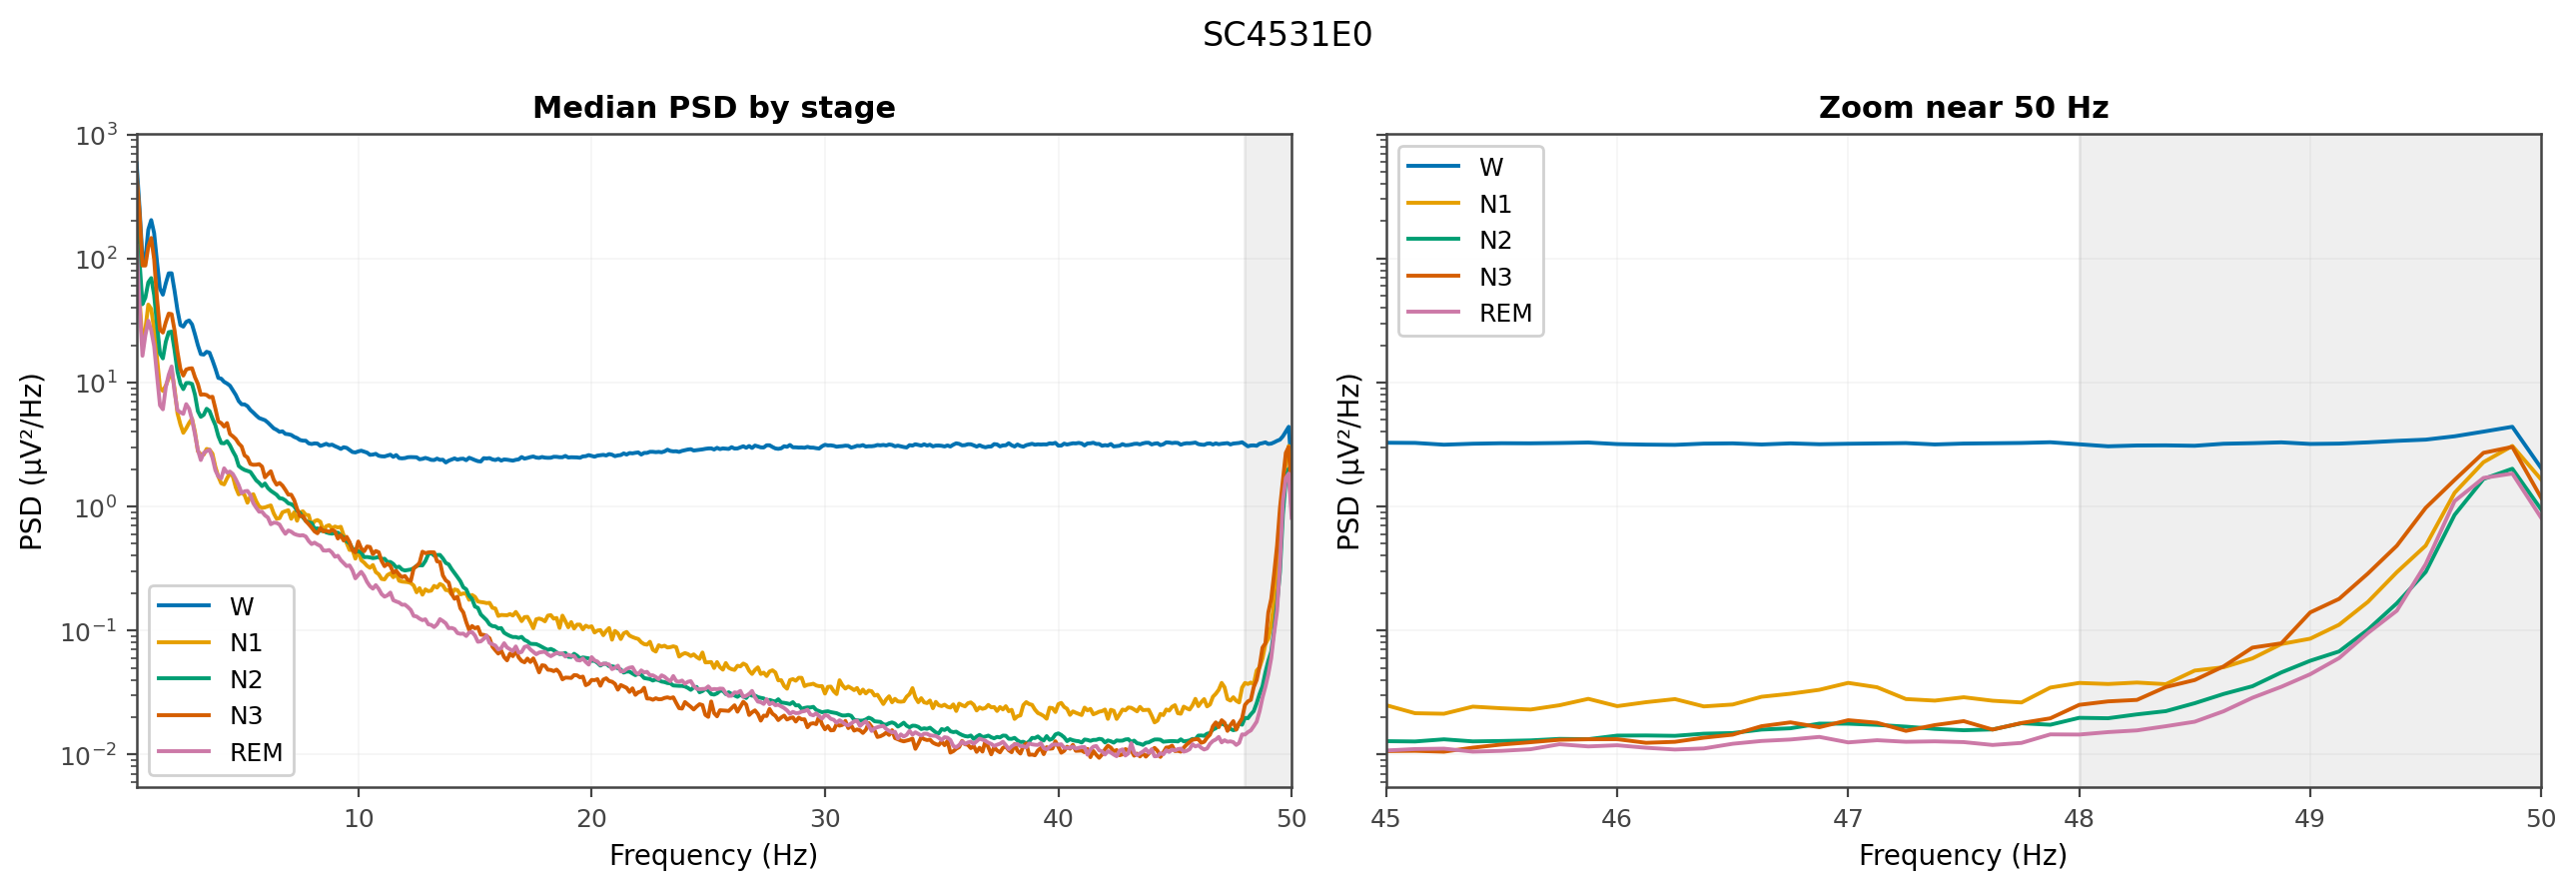

```text

Kappa mais alto | SC414 | Gravação: SC4141E0
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Épocas</th>
      <th>Mediana 48–50 Hz (%)</th>
      <th>P95 48–50 Hz (%)</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>1939</td>
      <td>0.87</td>
      <td>3.22</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>29</td>
      <td>0.50</td>
      <td>1.00</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>404</td>
      <td>0.11</td>
      <td>0.42</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>151</td>
      <td>0.04</td>
      <td>0.10</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>233</td>
      <td>0.27</td>
      <td>0.59</td>
    </tr>
  </tbody>
</table>

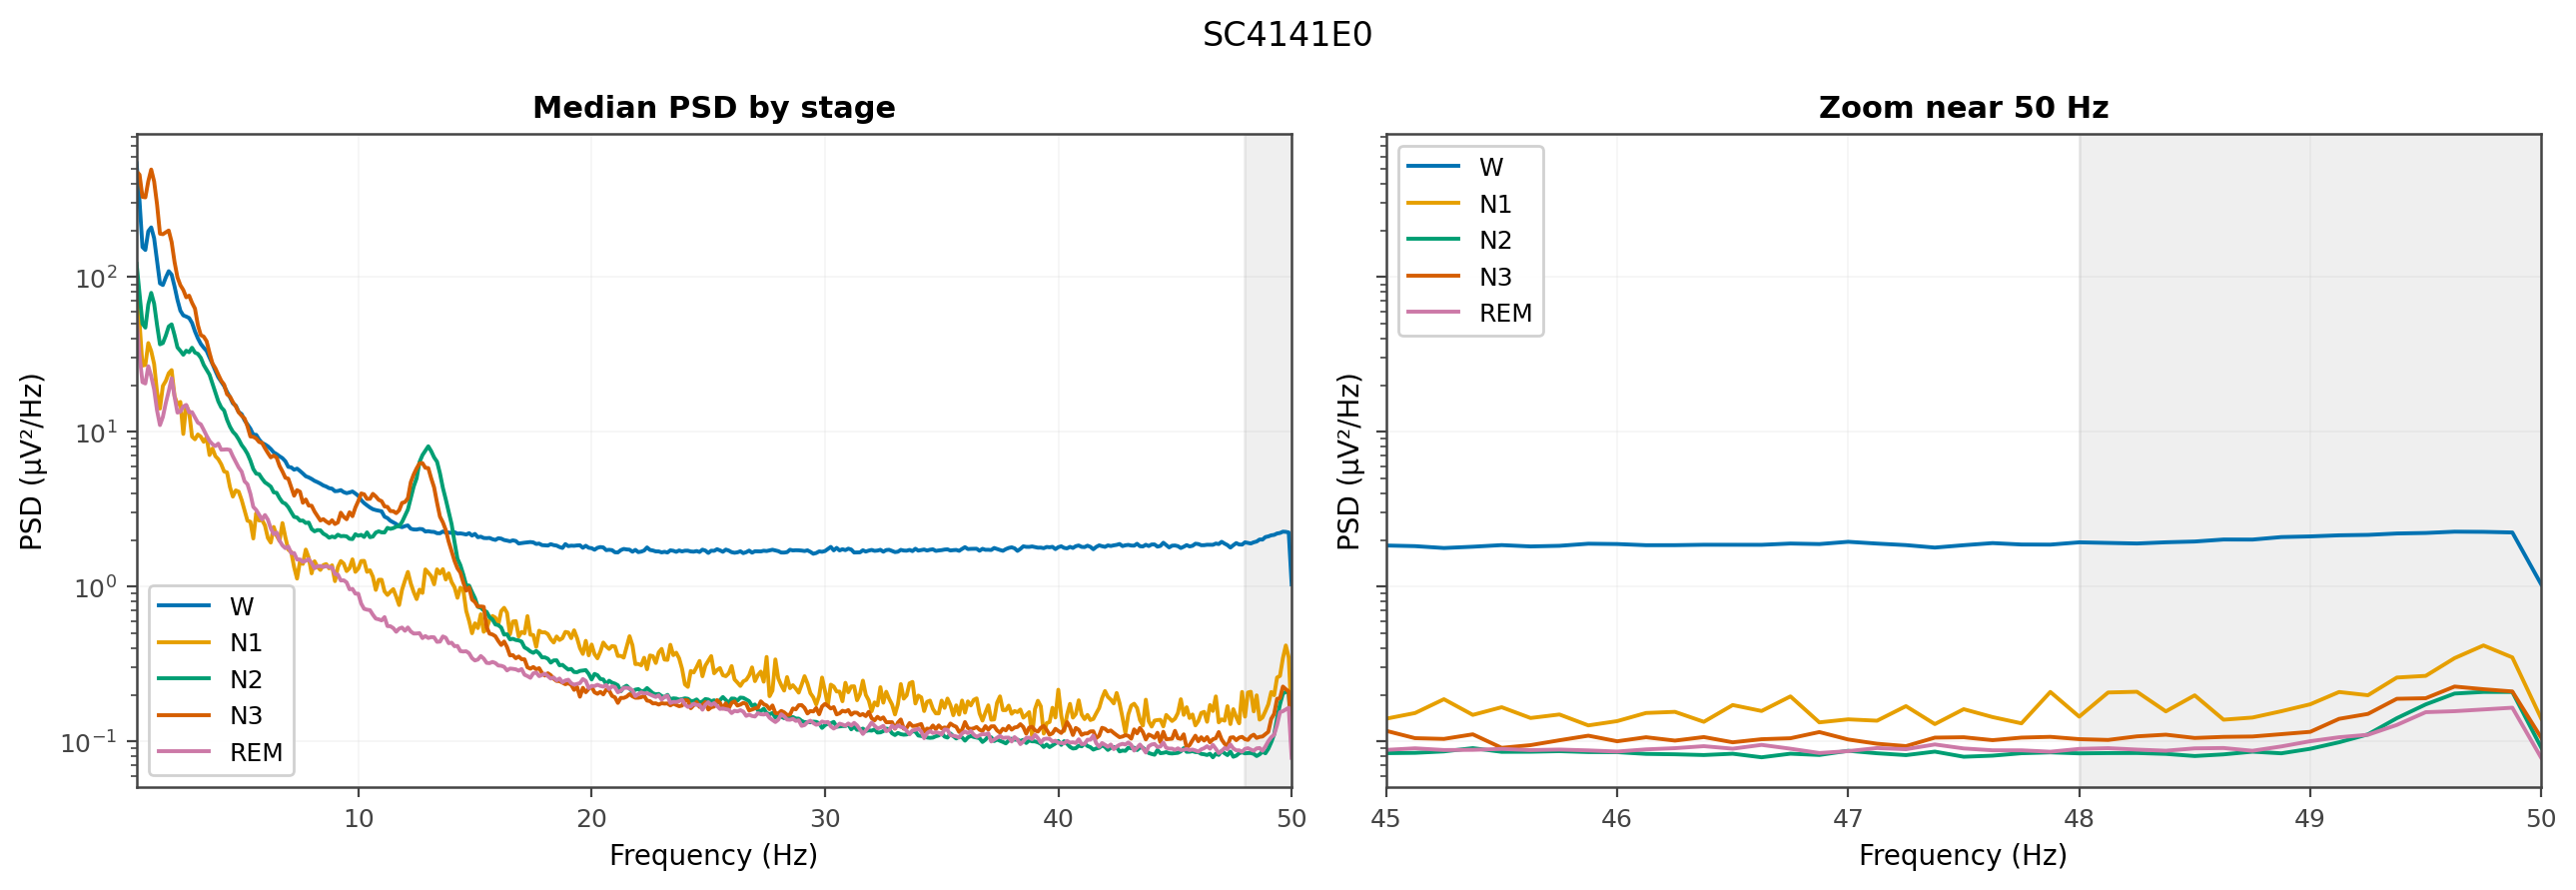

```text

COMPARAÇÃO DAS TRÊS GRAVAÇÕES
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Gravação</th>
      <th>Estágio</th>
      <th>Épocas</th>
      <th>Mediana 48–50 Hz (%)</th>
      <th>P95 48–50 Hz (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>SC4611E0</td>
      <td>W</td>
      <td>1707</td>
      <td>1.06</td>
      <td>16.68</td>
    </tr>
    <tr>
      <th>1</th>
      <td>SC4611E0</td>
      <td>N1</td>
      <td>123</td>
      <td>48.47</td>
      <td>90.68</td>
    </tr>
    <tr>
      <th>2</th>
      <td>SC4611E0</td>
      <td>N2</td>
      <td>276</td>
      <td>44.61</td>
      <td>88.43</td>
    </tr>
    <tr>
      <th>3</th>
      <td>SC4611E0</td>
      <td>N3</td>
      <td>139</td>
      <td>29.54</td>
      <td>80.43</td>
    </tr>
    <tr>
      <th>4</th>
      <td>SC4611E0</td>
      <td>REM</td>
      <td>399</td>
      <td>49.45</td>
      <td>63.34</td>
    </tr>
    <tr>
      <th>5</th>
      <td>SC4531E0</td>
      <td>W</td>
      <td>1748</td>
      <td>1.69</td>
      <td>4.57</td>
    </tr>
    <tr>
      <th>6</th>
      <td>SC4531E0</td>
      <td>N1</td>
      <td>124</td>
      <td>2.57</td>
      <td>9.36</td>
    </tr>
    <tr>
      <th>7</th>
      <td>SC4531E0</td>
      <td>N2</td>
      <td>465</td>
      <td>1.05</td>
      <td>5.45</td>
    </tr>
    <tr>
      <th>8</th>
      <td>SC4531E0</td>
      <td>N3</td>
      <td>85</td>
      <td>1.56</td>
      <td>3.33</td>
    </tr>
    <tr>
      <th>9</th>
      <td>SC4531E0</td>
      <td>REM</td>
      <td>180</td>
      <td>1.59</td>
      <td>13.41</td>
    </tr>
    <tr>
      <th>10</th>
      <td>SC4141E0</td>
      <td>W</td>
      <td>1939</td>
      <td>0.87</td>
      <td>3.22</td>
    </tr>
    <tr>
      <th>11</th>
      <td>SC4141E0</td>
      <td>N1</td>
      <td>29</td>
      <td>0.50</td>
      <td>1.00</td>
    </tr>
    <tr>
      <th>12</th>
      <td>SC4141E0</td>
      <td>N2</td>
      <td>404</td>
      <td>0.11</td>
      <td>0.42</td>
    </tr>
    <tr>
      <th>13</th>
      <td>SC4141E0</td>
      <td>N3</td>
      <td>151</td>
      <td>0.04</td>
      <td>0.10</td>
    </tr>
    <tr>
      <th>14</th>
      <td>SC4141E0</td>
      <td>REM</td>
      <td>233</td>
      <td>0.27</td>
      <td>0.59</td>
    </tr>
  </tbody>
</table>

</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 68
# Resultados individuais dos 68 participantes.
scores_inspecao = pd.DataFrame(
    relatorio_f2_68["per_group"]
)[["group", "cohens_kappa"]]

scores_inspecao = (
    scores_inspecao
    .dropna(subset=["cohens_kappa"])
    .sort_values(["cohens_kappa", "group"])
    .reset_index(drop=True)
)

assert len(scores_inspecao) >= 3

selecoes = [
    ("Kappa mais baixo", 0),
    ("Kappa intermédio", len(scores_inspecao) // 2),
    ("Kappa mais alto", len(scores_inspecao) - 1),
]

plano_inspecao_68 = []

for perfil, posicao in selecoes:
    linha = scores_inspecao.iloc[posicao]
    participante = str(linha["group"])

    # Escolher a primeira gravação disponível dessa pessoa.
    gravacoes = sorted(
        [
            dados for dados in b0_gravacoes_68
            if dados["record"][:5] == participante
        ],
        key=lambda dados: dados["record"],
    )

    assert gravacoes
    dados = gravacoes[0]

    plano_inspecao_68.append({
        "Perfil": perfil,
        "Participante": participante,
        "Kappa F2": float(linha["cohens_kappa"]),
        "Gravação": dados["record"],
        "Épocas": len(dados["y"]),
        "Épocas N1": int(np.count_nonzero(dados["y"] == "N1")),
    })

display(pd.DataFrame(plano_inspecao_68).round(3))

# Célula original 69
from pathlib import Path
from tempfile import TemporaryDirectory
from scipy.signal import welch

def carregar_gravacao_inspecao_68(record_id):
    assert record_id[:5] in DEVELOPMENT_GROUPS_68

    ficheiros = list(TRAIN_DIR.rglob(f"{record_id}-PSG.edf"))
    assert len(ficheiros) == 1
    psg = ficheiros[0]

    marcacoes = list(
        psg.parent.glob(f"{record_id[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1

    # Ler apenas este par de ficheiros, através de ligações locais.
    with TemporaryDirectory() as pasta:
        for origem in (psg, marcacoes[0]):
            (Path(pasta) / origem.name).symlink_to(origem.resolve())

        gravacoes = track_b0_68.load(
            pasta, fs_target=100.0, epoch_s=30.0
        )

    assert len(gravacoes) == 1
    return gravacoes[0]


record_id_inspecao = plano_inspecao_68[0]["Gravação"]

# Reutilizar a gravação na memória se repetirmos esta célula.
if (
    "rec_inspecao_68" not in globals()
    or rec_inspecao_68.meta["record"] != record_id_inspecao
):
    rec_inspecao_68 = carregar_gravacao_inspecao_68(
        record_id_inspecao
    )

rec = rec_inspecao_68
fs = float(rec.fs)
eeg_uv = np.asarray(rec.epochs["eeg"]) * 1e6

# Confirmar alinhamento com as previsões já feitas pelo F2.
indices_gravacao = np.flatnonzero(
    record_ids_b0_68 == record_id_inspecao
)
np.testing.assert_array_equal(
    rec.labels, y_b0_68[indices_gravacao]
)
previsoes_gravacao = previsoes_f2_68[indices_gravacao]

finitas = np.isfinite(eeg_uv).all(axis=1)
print(f"Gravação: {record_id_inspecao} | Épocas: {len(rec.labels)}")
print("Épocas com NaN/Inf:", int((~finitas).sum()))
assert finitas.all(), "Verificar valores inválidos antes dos gráficos."

amplitudes = np.ptp(eeg_uv, axis=1)
print("Épocas completamente constantes:", int((amplitudes == 0).sum()))

fig_inspecao_68, axes = plt.subplots(2, 2, figsize=(13, 7))
exemplos_inspecao_68 = []

for linha, estagio in enumerate(["W", "N1"]):
    candidatos = np.flatnonzero(rec.labels == estagio)
    assert len(candidatos) > 0

    # Época mais próxima da mediana pico-a-pico deste estágio.
    mediana = np.median(amplitudes[candidatos])
    i = candidatos[
        np.argmin(np.abs(amplitudes[candidatos] - mediana))
    ]

    sinal = eeg_uv[i]
    tempo = np.arange(len(sinal)) / fs

    axes[linha, 0].plot(tempo, sinal, linewidth=0.7)
    axes[linha, 0].set(
        title=f"True: {estagio} | F2: {previsoes_gravacao[i]} | Epoch: {i}",
        xlabel="Time within epoch (s)",
        ylabel="EEG (µV)",
        xlim=(0, len(sinal) / fs),
    )

    # Estas definições são apenas para o gráfico de inspeção.
    nperseg = min(int(8 * fs), len(sinal))
    frequencias, psd = welch(
        sinal, fs=fs, window="hann",
        nperseg=nperseg, noverlap=nperseg // 2,
        detrend="constant", scaling="density",
    )

    positivos = psd > 0
    axes[linha, 1].semilogy(
        frequencias[positivos], psd[positivos]
    )
    axes[linha, 1].set(
        title=f"{estagio} — Welch PSD",
        xlabel="Frequency (Hz)",
        ylabel="PSD (µV²/Hz)",
        xlim=(0, fs / 2),
    )

    for ax in axes[linha]:
        ax.grid(True, alpha=0.25)

    exemplos_inspecao_68.append({
        "Estágio real": estagio,
        "Época retida": int(i),
        "Previsão F2": str(previsoes_gravacao[i]),
        "Pico-a-pico (µV)": float(amplitudes[i]),
    })

fig_inspecao_68.suptitle(f"{record_id_inspecao} — EEG Fpz-Cz")
fig_inspecao_68.tight_layout()
plt.show()

display(pd.DataFrame(exemplos_inspecao_68).round(3))

# Célula original 70
def resumir_espectros_68(rec):
    fs = float(rec.fs)
    assert np.isclose(fs, 100.0)

    eeg = np.asarray(rec.epochs["eeg"]) * 1e6
    assert np.isfinite(eeg).all()

    nperseg = min(int(8 * fs), eeg.shape[1])

    # Um PSD por época, sem juntar épocas descontínuas.
    frequencias, psds = welch(
        eeg,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend="constant",
        scaling="density",
        axis=-1,
    )

    banda_total = (frequencias >= 0.5) & (frequencias <= 50)
    banda_alta = (frequencias >= 48) & (frequencias <= 50)

    potencia_total = np.trapezoid(
        psds[:, banda_total],
        frequencias[banda_total],
        axis=1,
    )
    potencia_alta = np.trapezoid(
        psds[:, banda_alta],
        frequencias[banda_alta],
        axis=1,
    )

    percentagem_alta = 100 * np.divide(
        potencia_alta,
        potencia_total,
        out=np.full_like(potencia_total, np.nan),
        where=potencia_total > 0,
    )

    linhas = []
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

    for estagio in ["W", "N1", "N2", "N3", "REM"]:
        mascara = rec.labels == estagio
        valores = percentagem_alta[mascara]
        valores = valores[np.isfinite(valores)]

        linhas.append({
            "Estágio": estagio,
            "Épocas": int(mascara.sum()),
            "Mediana 48–50 Hz (%)": (
                float(np.median(valores)) if len(valores) else np.nan
            ),
            "P95 48–50 Hz (%)": (
                float(np.percentile(valores, 95))
                if len(valores) else np.nan
            ),
        })

        if not mascara.any():
            continue

        # Mediana dos PSDs em cada frequência, para este estágio.
        mediana_psd = np.median(psds[mascara], axis=0)
        visiveis = banda_total & (mediana_psd > 0)

        for ax in axes:
            ax.semilogy(
                frequencias[visiveis],
                mediana_psd[visiveis],
                label=estagio,
            )

    axes[0].set(title="Median PSD by stage", xlim=(0.5, 50))
    axes[1].set(title="Zoom near 50 Hz", xlim=(45, 50))

    for ax in axes:
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD (µV²/Hz)")
        ax.axvspan(48, 50, color="grey", alpha=0.12)
        ax.grid(True, alpha=0.25)
        ax.legend()

    fig.suptitle(rec.meta["record"])
    fig.tight_layout()

    return pd.DataFrame(linhas).set_index("Estágio"), fig


tabela_espectral_68, fig_espectral_68 = resumir_espectros_68(
    rec_inspecao_68
)

print("Percentagem da potência de 0,5–50 Hz situada em 48–50 Hz:")
display(tabela_espectral_68.round(2))
plt.show()

# Célula original 71
# Preservar o diagnóstico de SC4611E0.
primeira_gravacao = plano_inspecao_68[0]["Gravação"]

tabelas_espectrais_68 = {
    primeira_gravacao: tabela_espectral_68.copy()
}

figuras_espectrais_68 = {
    primeira_gravacao: fig_espectral_68
}

# Inspecionar os participantes com kappa intermédio e alto.
for selecao in plano_inspecao_68[1:]:
    record_id = selecao["Gravação"]

    print(
        f"\n{selecao['Perfil']} | "
        f"{selecao['Participante']} | "
        f"Gravação: {record_id}",
        flush=True,
    )

    rec_diagnostico = carregar_gravacao_inspecao_68(record_id)

    # Confirmar as mesmas épocas usadas na avaliação.
    indices = np.flatnonzero(record_ids_b0_68 == record_id)
    np.testing.assert_array_equal(
        rec_diagnostico.labels,
        y_b0_68[indices],
    )

    tabela_atual, figura_atual = resumir_espectros_68(
        rec_diagnostico
    )

    tabelas_espectrais_68[record_id] = tabela_atual.copy()
    figuras_espectrais_68[record_id] = figura_atual

    display(tabela_atual.round(2))
    plt.show()

    del rec_diagnostico

# Comparação das três gravações.
comparacao_espectral_68 = pd.concat(
    tabelas_espectrais_68,
    names=["Gravação", "Estágio"],
).reset_index()

print("\nCOMPARAÇÃO DAS TRÊS GRAVAÇÕES")
display(comparacao_espectral_68.round(2))
```

</details>

### 3.4 — LP40: filtro de 40 Hz

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

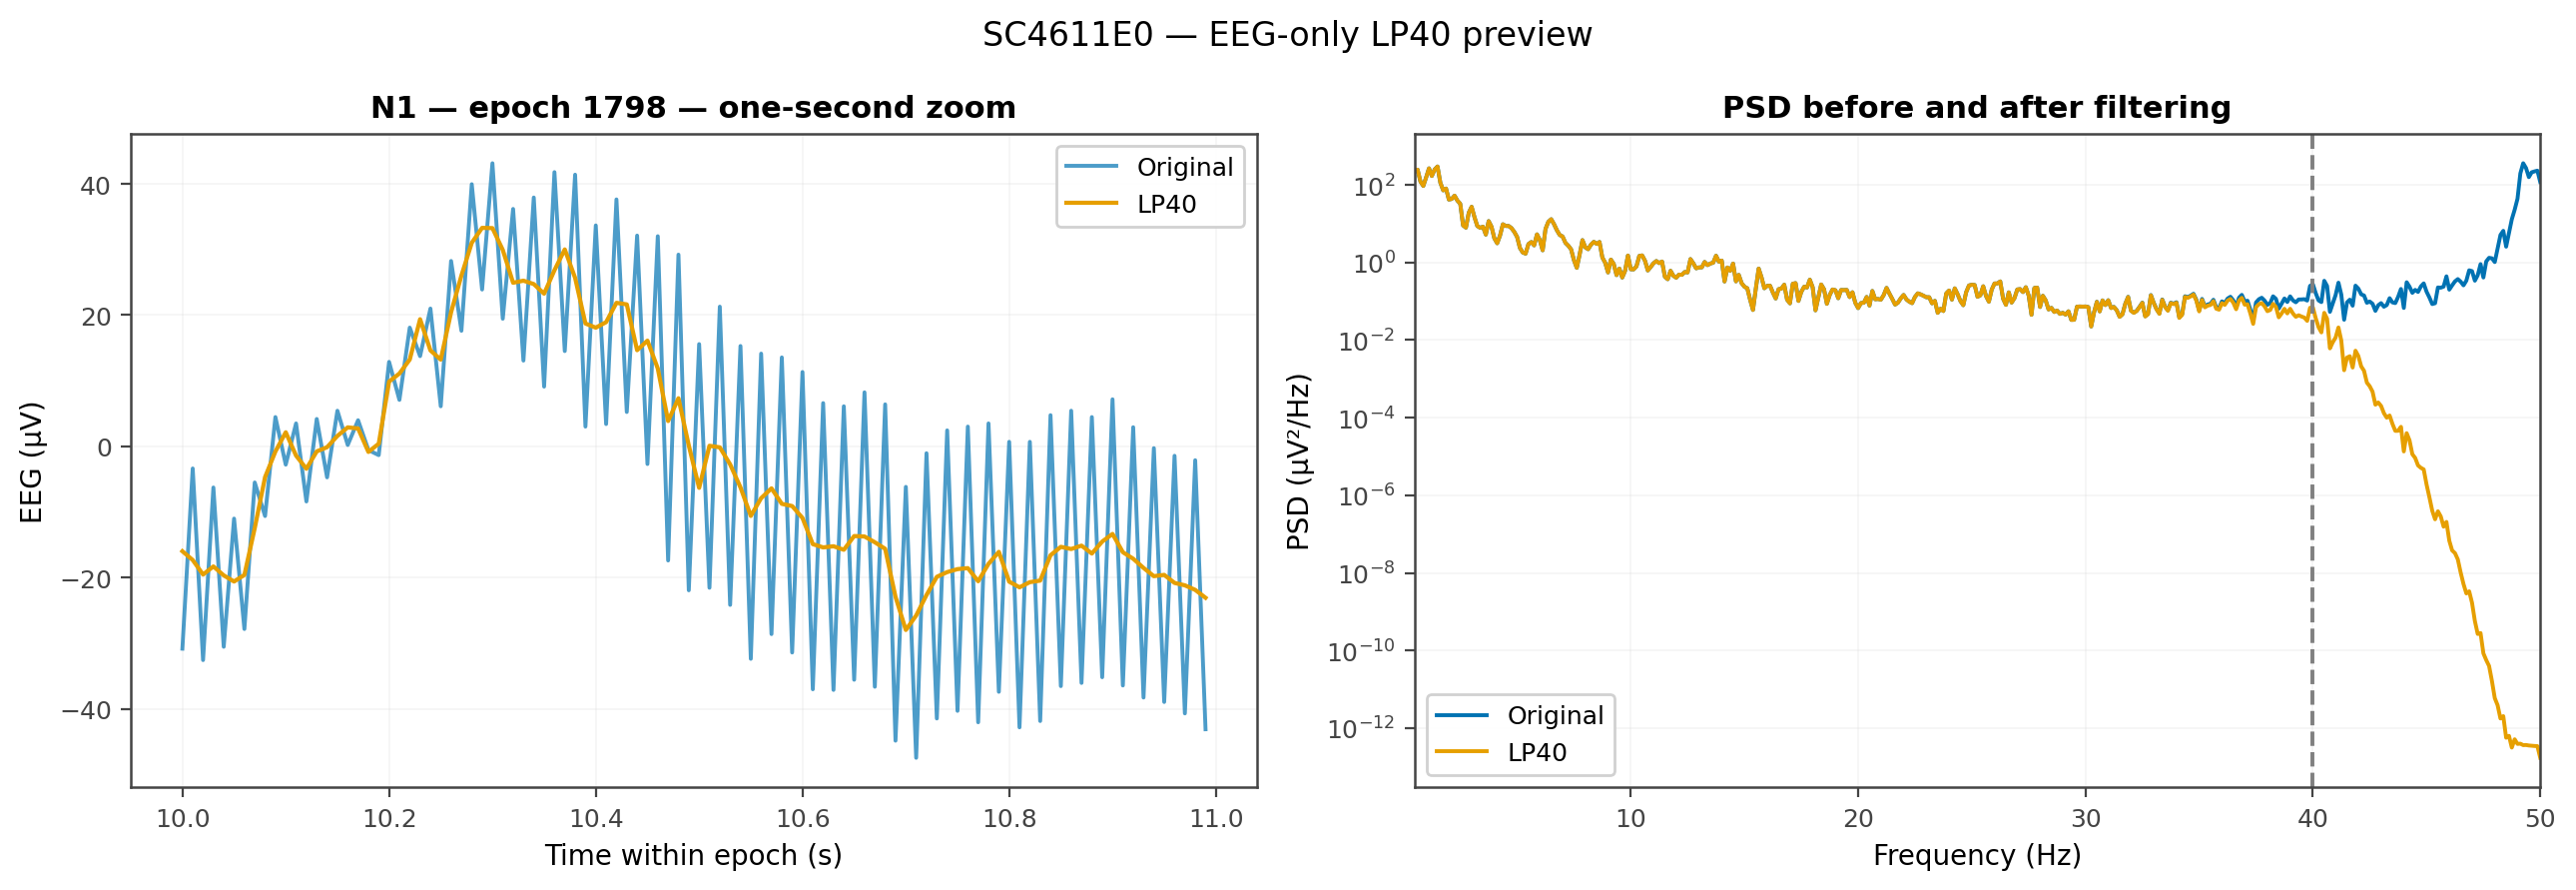

```text
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_8e4c87d8ba0e.pkl

Gravação: SC4611E0
Épocas: 2644
Características: 16
Labels, participantes e EOG/EMG confirmados.
Tempo de preparação: 51.1 segundos
```


```text
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b030fdacb58c.pkl
[001/133] SC4001E0 | 2650 épocas | 48.2 s | total: 0.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_9c9b545aef4e.pkl
[002/133] SC4002E0 | 2829 épocas | 51.6 s | total: 1.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_60dc679ba963.pkl
[003/133] SC4011E0 | 2802 épocas | 54.1 s | total: 2.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7e15ac284305.pkl
[004/133] SC4012E0 | 2848 épocas | 48.6 s | total: 3.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_5316b789b31a.pkl
[005/133] SC4021E0 | 2804 épocas | 56.0 s | total: 4.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_4d5592aefef2.pkl
[006/133] SC4022E0 | 2755 épocas | 48.0 s | total: 5.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7f22feb5b2d9.pkl
[007/133] SC4031E0 | 2820 épocas | 45.5 s | total: 5.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_683c0c993183.pkl
[008/133] SC4032E0 | 2732 épocas | 51.8 s | total: 6.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_167530e36088.pkl
[009/133] SC4041E0 | 2569 épocas | 39.9 s | total: 7.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_68303cfdc651.pkl
[010/133] SC4042E0 | 2788 épocas | 44.1 s | total: 8.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_06e7d38fc3c2.pkl
[011/133] SC4051E0 | 2722 épocas | 53.6 s | total: 9.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_dd86b22539cc.pkl
[012/133] SC4052E0 | 2804 épocas | 46.7 s | total: 9.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_bc201fc31fc3.pkl
[013/133] SC4061E0 | 2770 épocas | 45.5 s | total: 10.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_24b657561314.pkl
[014/133] SC4062E0 | 2830 épocas | 54.6 s | total: 11.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7ec6634cb7b3.pkl
[015/133] SC4071E0 | 2810 épocas | 53.6 s | total: 12.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_176388bb512b.pkl
[016/133] SC4072E0 | 2770 épocas | 53.1 s | total: 13.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_702aff11fe11.pkl
[017/133] SC4091E0 | 2721 épocas | 53.1 s | total: 14.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_8713427820ff.pkl
[018/133] SC4092E0 | 2044 épocas | 55.8 s | total: 15.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_ebddef574b4c.pkl
[019/133] SC4101E0 | 2719 épocas | 37.7 s | total: 15.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_38a423f895c2.pkl
[020/133] SC4102E0 | 2857 épocas | 63.6 s | total: 16.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_5bbcefadbd1d.pkl
[021/133] SC4111E0 | 2641 épocas | 52.9 s | total: 17.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3ce20b013faf.pkl
[022/133] SC4112E0 | 2780 épocas | 45.8 s | total: 18.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_0aa2bf7a10a0.pkl
[023/133] SC4121E0 | 2685 épocas | 45.5 s | total: 19.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e76d32ccb534.pkl
[024/133] SC4122E0 | 2606 épocas | 51.9 s | total: 20.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_07859be07fc3.pkl
[025/133] SC4131E0 | 2814 épocas | 47.1 s | total: 20.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_f92440336d71.pkl
[026/133] SC4141E0 | 2756 épocas | 50.5 s | total: 21.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_a2f56069f8bc.pkl
[027/133] SC4142E0 | 2774 épocas | 49.9 s | total: 22.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_4ff1b0747964.pkl
[028/133] SC4151E0 | 2616 épocas | 37.8 s | total: 23.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_963cbd22e618.pkl
[029/133] SC4152E0 | 2859 épocas | 46.8 s | total: 23.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_32bc416c5b8e.pkl
[030/133] SC4171E0 | 2741 épocas | 53.6 s | total: 24.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_a1ee80fbcab5.pkl
[031/133] SC4172E0 | 2720 épocas | 41.9 s | total: 25.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e32853cb010f.pkl
[032/133] SC4181E0 | 2756 épocas | 40.7 s | total: 26.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d0042238500a.pkl
[033/133] SC4182E0 | 2842 épocas | 47.5 s | total: 27.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b20b1ab6df66.pkl
[034/133] SC4191E0 | 2774 épocas | 50.9 s | total: 27.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_78a20b0b9ae7.pkl
[035/133] SC4192E0 | 2605 épocas | 44.1 s | total: 28.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7dc350d6b3ce.pkl
[036/133] SC4201E0 | 2803 épocas | 52.8 s | total: 29.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_2c8ab97b49ca.pkl
[037/133] SC4202E0 | 2670 épocas | 42.8 s | total: 30.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b171d3e864be.pkl
[038/133] SC4211E0 | 2805 épocas | 50.2 s | total: 31.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_600efbd9dbe8.pkl
[039/133] SC4212E0 | 2694 épocas | 53.0 s | total: 31.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_20fab70479de.pkl
[040/133] SC4221E0 | 2700 épocas | 41.8 s | total: 32.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_005c4c639f5c.pkl
[041/133] SC4222E0 | 2760 épocas | 47.8 s | total: 33.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_218d06880792.pkl
[042/133] SC4231E0 | 2743 épocas | 59.6 s | total: 34.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_c51839020ad9.pkl
[043/133] SC4232E0 | 2635 épocas | 37.1 s | total: 35.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3bcf74123583.pkl
[044/133] SC4251E0 | 2760 épocas | 42.0 s | total: 35.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3b57dee659ef.pkl
[045/133] SC4252E0 | 2665 épocas | 44.9 s | total: 36.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d54a2ed0f710.pkl
[046/133] SC4261F0 | 2800 épocas | 49.0 s | total: 37.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_cd0329969ff5.pkl
[047/133] SC4262F0 | 2720 épocas | 42.0 s | total: 37.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_636cd657baa6.pkl
[048/133] SC4271F0 | 2440 épocas | 34.8 s | total: 38.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_8a0504b294e1.pkl
[049/133] SC4272F0 | 2870 épocas | 49.9 s | total: 39.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b114c4ac16c1.pkl
[050/133] SC4281G0 | 2788 épocas | 45.0 s | total: 40.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_118f82ae4896.pkl
[051/133] SC4282G0 | 2814 épocas | 44.1 s | total: 40.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_40947f4cd7a2.pkl
[052/133] SC4291G0 | 2756 épocas | 54.0 s | total: 41.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e10367e5ad9e.pkl
[053/133] SC4292G0 | 2807 épocas | 55.7 s | total: 42.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b5da7a51fb34.pkl
[054/133] SC4301E0 | 2644 épocas | 38.5 s | total: 43.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6b4fbc136e19.pkl
[055/133] SC4302E0 | 2808 épocas | 45.0 s | total: 44.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_39b343a047dd.pkl
[056/133] SC4311E0 | 2670 épocas | 38.6 s | total: 44.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_ff6577ca4cfe.pkl
[057/133] SC4312E0 | 2700 épocas | 49.9 s | total: 45.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_0a49ef329150.pkl
[058/133] SC4331F0 | 2809 épocas | 48.7 s | total: 46.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d4be67cd33dc.pkl
[059/133] SC4332F0 | 2758 épocas | 45.4 s | total: 47.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_1a8e73c865aa.pkl
[060/133] SC4341F0 | 2750 épocas | 39.5 s | total: 47.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7dedcb20912e.pkl
[061/133] SC4342F0 | 2790 épocas | 43.3 s | total: 48.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_1b3426dd89c4.pkl
[062/133] SC4351F0 | 2710 épocas | 41.7 s | total: 49.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6b447a92cc6e.pkl
[063/133] SC4352F0 | 2530 épocas | 38.2 s | total: 49.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_902775824b7a.pkl
[064/133] SC4362F0 | 2266 épocas | 33.3 s | total: 50.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_91417780b9ff.pkl
[065/133] SC4371F0 | 2850 épocas | 46.6 s | total: 51.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d3fc718c781d.pkl
[066/133] SC4372F0 | 2840 épocas | 44.8 s | total: 51.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_214e025f06ab.pkl
[067/133] SC4381F0 | 2750 épocas | 51.2 s | total: 52.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_ba3772af3e51.pkl
[068/133] SC4382F0 | 2770 épocas | 49.6 s | total: 53.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_73429e0447c5.pkl
[069/133] SC4411E0 | 2728 épocas | 48.0 s | total: 54.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_a8d00b4ad4c5.pkl
[070/133] SC4412E0 | 2765 épocas | 67.4 s | total: 55.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_4605994855be.pkl
[071/133] SC4421E0 | 2764 épocas | 53.4 s | total: 56.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7978e710c129.pkl
[072/133] SC4422E0 | 2682 épocas | 47.2 s | total: 57.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3a81ad1a3211.pkl
[073/133] SC4431E0 | 2723 épocas | 46.6 s | total: 57.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e6cae5bef5c8.pkl
[074/133] SC4432E0 | 2780 épocas | 44.2 s | total: 58.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b51d229f24b4.pkl
[075/133] SC4441E0 | 2620 épocas | 38.9 s | total: 59.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6817b7bf54fd.pkl
[076/133] SC4442E0 | 2778 épocas | 51.9 s | total: 60.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3d5222e62b8d.pkl
[077/133] SC4451F0 | 2790 épocas | 51.9 s | total: 61.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_46fe936f9c32.pkl
[078/133] SC4452F0 | 2670 épocas | 49.6 s | total: 61.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d1fbc2bf5fc2.pkl
[079/133] SC4461F0 | 2695 épocas | 52.3 s | total: 62.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_ac6b754e8b63.pkl
[080/133] SC4462F0 | 2854 épocas | 50.6 s | total: 63.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_19ff879c5a3d.pkl
[081/133] SC4471F0 | 2739 épocas | 54.2 s | total: 64.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3a91c1d2881a.pkl
[082/133] SC4472F0 | 2789 épocas | 60.6 s | total: 65.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_9a0e268144b4.pkl
[083/133] SC4491G0 | 2800 épocas | 54.2 s | total: 66.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7f094fc1dbbd.pkl
[084/133] SC4492G0 | 2135 épocas | 38.8 s | total: 67.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_93df6f933611.pkl
[085/133] SC4501E0 | 2750 épocas | 50.6 s | total: 67.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7bf01051faac.pkl
[086/133] SC4502E0 | 2770 épocas | 55.7 s | total: 68.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3ac8efccc2fd.pkl
[087/133] SC4511E0 | 2712 épocas | 52.2 s | total: 69.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_f0ced7214af1.pkl
[088/133] SC4512E0 | 2750 épocas | 50.5 s | total: 70.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_5ee43bdc94d2.pkl
[089/133] SC4522E0 | 2774 épocas | 46.0 s | total: 71.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_76902d12e2b5.pkl
[090/133] SC4531E0 | 2602 épocas | 58.5 s | total: 72.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_3603a23865d3.pkl
[091/133] SC4532E0 | 2744 épocas | 55.0 s | total: 73.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_aad8647a807c.pkl
[092/133] SC4541F0 | 2739 épocas | 52.7 s | total: 74.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6299e1dcb768.pkl
[093/133] SC4542F0 | 2680 épocas | 52.0 s | total: 74.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6f61e53ed800.pkl
[094/133] SC4551F0 | 2772 épocas | 46.4 s | total: 75.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_a6baae088583.pkl
[095/133] SC4552F0 | 2810 épocas | 47.1 s | total: 76.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b097c5e45815.pkl
[096/133] SC4571F0 | 2836 épocas | 51.1 s | total: 77.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_5d749926dd1c.pkl
[097/133] SC4572F0 | 2873 épocas | 45.8 s | total: 78.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_ad834db76122.pkl
[098/133] SC4581G0 | 2738 épocas | 39.7 s | total: 78.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_34fb16a9c2f7.pkl
[099/133] SC4582G0 | 2634 épocas | 43.9 s | total: 79.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_bab7dd64cddc.pkl
[100/133] SC4591G0 | 2819 épocas | 48.7 s | total: 80.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_f277e6905f45.pkl
[101/133] SC4592G0 | 2040 épocas | 29.4 s | total: 80.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_1a77e0535c70.pkl
[102/133] SC4601E0 | 2730 épocas | 47.0 s | total: 81.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_bfa88b7fe3ae.pkl
[103/133] SC4602E0 | 2800 épocas | 53.4 s | total: 82.5 min
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_8e4c87d8ba0e.pkl
[104/133] SC4611E0 | 2644 épocas | 0.0 s | total: 82.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6325f103d470.pkl
[105/133] SC4612E0 | 2730 épocas | 50.1 s | total: 83.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e473096c4591.pkl
[106/133] SC4621E0 | 2612 épocas | 45.5 s | total: 84.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_60bb0813ffc6.pkl
[107/133] SC4622E0 | 2856 épocas | 49.3 s | total: 84.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_a63866283e44.pkl
[108/133] SC4631E0 | 2758 épocas | 47.5 s | total: 85.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_f5d28d30274f.pkl
[109/133] SC4632E0 | 2848 épocas | 48.7 s | total: 86.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_06c1c4482597.pkl
[110/133] SC4651E0 | 2860 épocas | 53.1 s | total: 87.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_c9d6c045d87d.pkl
[111/133] SC4652E0 | 2838 épocas | 60.4 s | total: 88.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e746ebf73c63.pkl
[112/133] SC4661E0 | 2664 épocas | 48.8 s | total: 89.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_0e28df266a2e.pkl
[113/133] SC4662E0 | 2820 épocas | 51.1 s | total: 90.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_e8c1f93fc6c8.pkl
[114/133] SC4671G0 | 2780 épocas | 52.3 s | total: 90.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_30bbe18ae68a.pkl
[115/133] SC4672G0 | 2580 épocas | 37.0 s | total: 91.5 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_1bac1351d6e9.pkl
[116/133] SC4701E0 | 2679 épocas | 42.7 s | total: 92.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_2dec7fc0be73.pkl
[117/133] SC4702E0 | 2624 épocas | 48.5 s | total: 93.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_14b65e242d35.pkl
[118/133] SC4711E0 | 2730 épocas | 46.6 s | total: 93.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_42d76010a28b.pkl
[119/133] SC4712E0 | 2820 épocas | 48.2 s | total: 94.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_029f8a834b2d.pkl
[120/133] SC4731E0 | 2780 épocas | 46.8 s | total: 95.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_bd921d9a5386.pkl
[121/133] SC4732E0 | 2519 épocas | 45.0 s | total: 96.2 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_fcaaae6b3254.pkl
[122/133] SC4741E0 | 2689 épocas | 44.9 s | total: 96.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_cecd8abc8a5a.pkl
[123/133] SC4742E0 | 2650 épocas | 43.6 s | total: 97.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_9a98cfc33566.pkl
[124/133] SC4751E0 | 2680 épocas | 42.1 s | total: 98.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_cc2d9b260994.pkl
[125/133] SC4752E0 | 2470 épocas | 36.1 s | total: 99.0 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_218f49231a91.pkl
[126/133] SC4761E0 | 2610 épocas | 45.6 s | total: 99.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d4e759dbb4c0.pkl
[127/133] SC4762E0 | 2662 épocas | 53.4 s | total: 100.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_6eb9b07fe362.pkl
[128/133] SC4771G0 | 2756 épocas | 46.6 s | total: 101.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_41e3a5200168.pkl
[129/133] SC4772G0 | 2242 épocas | 32.6 s | total: 101.9 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_9599603e17a3.pkl
[130/133] SC4811G0 | 2402 épocas | 46.3 s | total: 102.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_2005149db4f1.pkl
[131/133] SC4812G0 | 2414 épocas | 39.4 s | total: 103.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_d0f6f077b43f.pkl
[132/133] SC4821G0 | 2721 épocas | 62.7 s | total: 104.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_cb84996d6665.pkl
[133/133] SC4822G0 | 2810 épocas | 51.4 s | total: 105.2 min

LP40 — PREPARAÇÃO CONCLUÍDA
Participantes: 68
Gravações: 133
Dimensão: (360621, 16)
Labels, participantes e ordem das épocas confirmados.
```


```text

LP40_68_fixed_AE — fold A: a treinar...
Fold A concluído: kappa = 0.756 | treino = 9.11 min

LP40_68_fixed_AE — fold B: a treinar...
Fold B concluído: kappa = 0.719 | treino = 8.49 min

LP40_68_fixed_AE — fold C: a treinar...
Fold C concluído: kappa = 0.736 | treino = 9.20 min

LP40_68_fixed_AE — fold D: a treinar...
Fold D concluído: kappa = 0.716 | treino = 8.88 min

LP40_68_fixed_AE — fold E: a treinar...
Fold E concluído: kappa = 0.751 | treino = 8.89 min

LP40 — CINCO FOLDS CONCLUÍDOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>cohens_kappa</th>
      <th>macro_f1</th>
      <th>accuracy</th>
      <th>balanced_accuracy</th>
      <th>Treino (min)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.756</td>
      <td>0.680</td>
      <td>0.887</td>
      <td>0.675</td>
      <td>9.113</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.719</td>
      <td>0.650</td>
      <td>0.863</td>
      <td>0.639</td>
      <td>8.494</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.736</td>
      <td>0.650</td>
      <td>0.876</td>
      <td>0.623</td>
      <td>9.202</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.716</td>
      <td>0.636</td>
      <td>0.874</td>
      <td>0.600</td>
      <td>8.883</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.751</td>
      <td>0.678</td>
      <td>0.880</td>
      <td>0.662</td>
      <td>8.889</td>
    </tr>
  </tbody>
</table>

```text

Kappa médio ± SD entre os cinco folds: 0.736 ± 0.018
Tempo total de treino: 44.6 min

COMPARAÇÃO DO KAPPA NOS MESMOS FOLDS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>LP40</th>
      <th>Diferença</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.753</td>
      <td>0.756</td>
      <td>0.003</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.718</td>
      <td>0.719</td>
      <td>0.001</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.739</td>
      <td>0.736</td>
      <td>-0.003</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.717</td>
      <td>0.716</td>
      <td>-0.001</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.748</td>
      <td>0.751</td>
      <td>0.003</td>
    </tr>
  </tbody>
</table>

```text
LP40 — MÉTRICAS GLOBAIS
cohens_kappa: 0.736
macro_f1: 0.661
accuracy: 0.876
balanced_accuracy: 0.641

LP40 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.938     0.979     0.958    248341
          N1      0.338     0.129     0.187     17877
          N2      0.767     0.814     0.790     60494
          N3      0.840     0.690     0.758     11610
         REM      0.630     0.593     0.611     22299

    accuracy                          0.876    360621
   macro avg      0.703     0.641     0.661    360621
weighted avg      0.857     0.876     0.864    360621


COMPARAÇÃO POR ESTÁGIO
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Recall F2</th>
      <th>Recall LP40</th>
      <th>F1 F2</th>
      <th>F1 LP40</th>
      <th>Diferença F1</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>0.980</td>
      <td>0.979</td>
      <td>0.959</td>
      <td>0.958</td>
      <td>-0.001</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>0.135</td>
      <td>0.129</td>
      <td>0.195</td>
      <td>0.187</td>
      <td>-0.008</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>0.813</td>
      <td>0.814</td>
      <td>0.786</td>
      <td>0.790</td>
      <td>0.003</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>0.681</td>
      <td>0.690</td>
      <td>0.751</td>
      <td>0.758</td>
      <td>0.007</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>0.581</td>
      <td>0.593</td>
      <td>0.605</td>
      <td>0.611</td>
      <td>0.006</td>
    </tr>
  </tbody>
</table>

```text
OS TRÊS PARTICIPANTES QUE INSPECIONÁMOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>LP40</th>
      <th>Diferença</th>
    </tr>
    <tr>
      <th>Participante</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>SC461</th>
      <td>0.241</td>
      <td>0.271</td>
      <td>0.030</td>
    </tr>
    <tr>
      <th>SC453</th>
      <td>0.763</td>
      <td>0.768</td>
      <td>0.004</td>
    </tr>
    <tr>
      <th>SC414</th>
      <td>0.905</td>
      <td>0.906</td>
      <td>0.000</td>
    </tr>
  </tbody>
</table>

```text

NOS 68 PARTICIPANTES — antes de arredondar:
Kappa aumentou: 29
Kappa diminuiu: 39
Kappa igual: 0
```


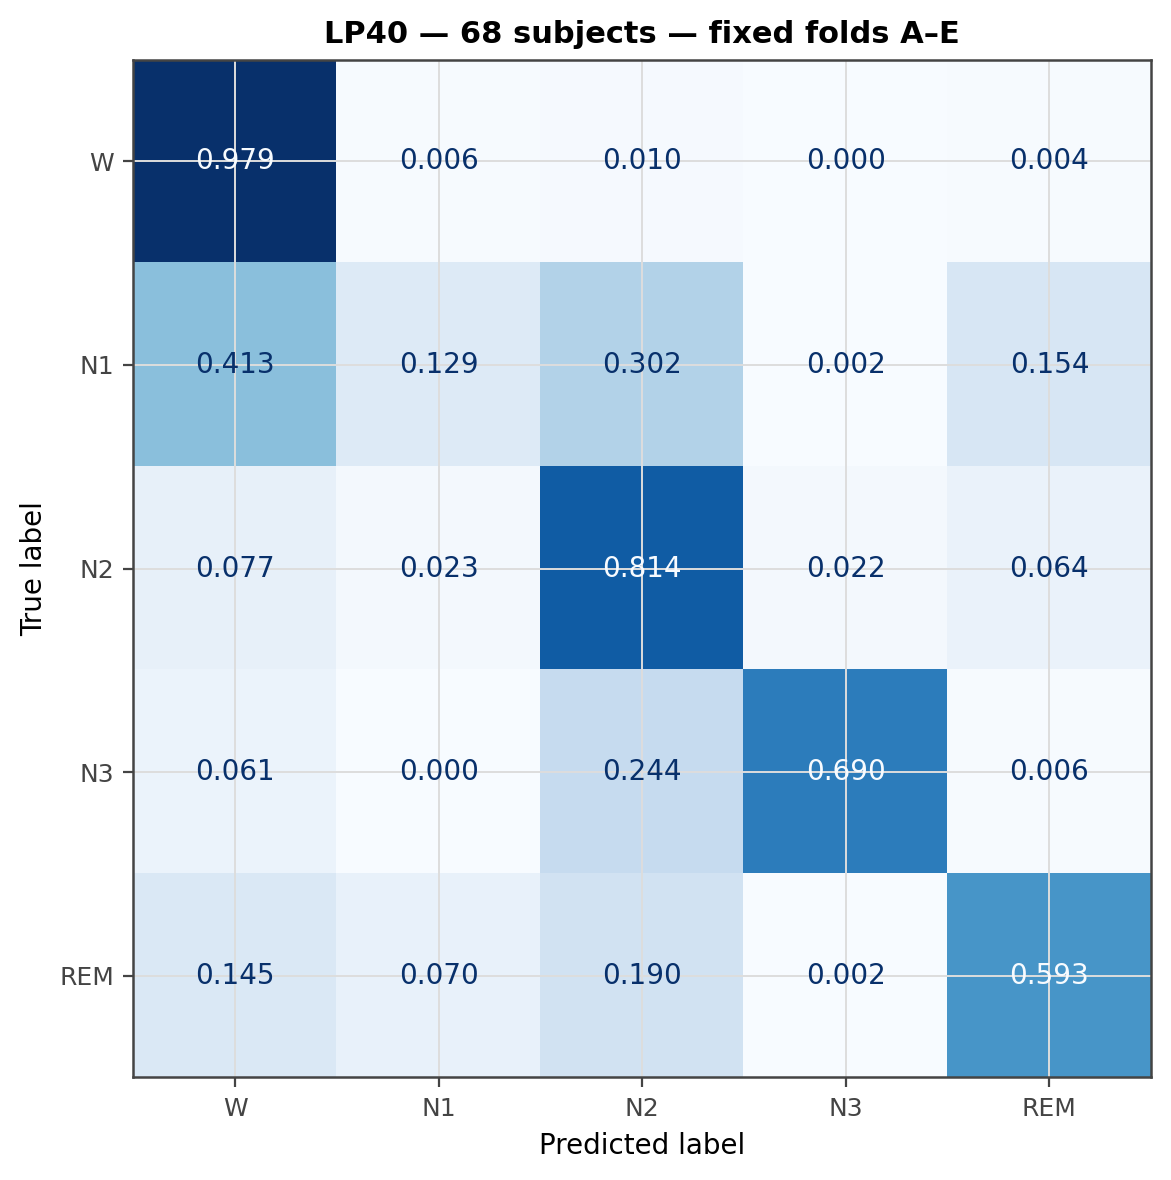

```text
Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/LP40_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/LP40_68_fixed_AE_confusion.png
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 72
from scipy.signal import butter, sosfiltfilt, welch

LP40_PREPROCESS_VERSION = 1
LP40_SETTINGS = {
    "cutoff_hz": 40.0,
    "order_per_pass": 4,
    "padtype": "odd",
}

def filtrar_eeg_lp40(eeg, fs):
    sos = butter(
        LP40_SETTINGS["order_per_pass"],
        LP40_SETTINGS["cutoff_hz"],
        btype="lowpass",
        fs=fs,
        output="sos",
    )
    return sosfiltfilt(
        sos,
        eeg,
        axis=-1,
        padtype=LP40_SETTINGS["padtype"],
    )


rec_preview = rec_inspecao_68
assert rec_preview.meta["record"] == "SC4611E0"

epoca_preview = 1798
assert rec_preview.labels[epoca_preview] == "N1"

fs = float(rec_preview.fs)

# Cópia em µV para os gráficos.
original = rec_preview.epochs["eeg"][epoca_preview] * 1e6
filtrado = filtrar_eeg_lp40(original, fs)

assert np.isfinite(filtrado).all()

tempo = np.arange(len(original)) / fs
zoom = (tempo >= 10) & (tempo < 11)

parametros_psd = {
    "fs": fs,
    "window": "hann",
    "nperseg": int(8 * fs),
    "noverlap": int(4 * fs),
    "detrend": "constant",
    "scaling": "density",
}

frequencias, psd_original = welch(original, **parametros_psd)
_, psd_filtrado = welch(filtrado, **parametros_psd)

fig_lp40_preview_68, axes = plt.subplots(
    1, 2, figsize=(13, 4.5)
)

axes[0].plot(
    tempo[zoom], original[zoom],
    label="Original", alpha=0.7,
)
axes[0].plot(
    tempo[zoom], filtrado[zoom],
    label="LP40", linewidth=1.5,
)
axes[0].set(
    title="N1 — epoch 1798 — one-second zoom",
    xlabel="Time within epoch (s)",
    ylabel="EEG (µV)",
)

# Os PSDs usam os 30 segundos completos.
axes[1].semilogy(
    frequencias, psd_original, label="Original"
)
axes[1].semilogy(
    frequencias, psd_filtrado, label="LP40"
)
axes[1].axvline(40, color="grey", linestyle="--")
axes[1].set(
    title="PSD before and after filtering",
    xlabel="Frequency (Hz)",
    ylabel="PSD (µV²/Hz)",
    xlim=(0.5, 50),
)

for ax in axes:
    ax.grid(True, alpha=0.25)
    ax.legend()

fig_lp40_preview_68.suptitle("SC4611E0 — EEG-only LP40 preview")
fig_lp40_preview_68.tight_layout()
plt.show()

# Célula original 73
from adapter import cached
from time import perf_counter

LP40_FEATURE_VERSION = 1

def preparar_lp40_gravacao_68(psg):
    psg = Path(psg).resolve()
    record_id = psg.name.removesuffix("-PSG.edf")

    assert record_id[:5] in DEVELOPMENT_GROUPS_68

    marcacoes = list(
        psg.parent.glob(f"{psg.name[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1

    referencia = next(
        dados for dados in b0_gravacoes_68
        if dados["record"] == record_id
    )

    chave = {
        "course_revision": COURSE_REVISION,
        "files": [
            (p.name, p.stat().st_size, p.stat().st_mtime_ns)
            for p in (psg, marcacoes[0])
        ],
        "load": {"fs_target": 100.0, "epoch_s": 30.0},
        "runtime": {
            nome: runtime_versions[nome]
            for nome in ("python", "numpy", "scipy", "mne")
        },
        "preprocessing": {
            "version": LP40_PREPROCESS_VERSION,
            "settings": dict(LP40_SETTINGS),
            "channels": ["eeg"],
            "application": "sosfiltfilt, per epoch, axis=-1",
        },
        "features": {
            "version": LP40_FEATURE_VERSION,
            "base_version": B0_FEATURE_VERSION,
            "relative_version": F2_FEATURE_VERSION,
            "spectral_method": "welch",
            "names": nomes_features_f2_68,
        },
    }

    def calcular():
        rec = carregar_gravacao_inspecao_68(record_id)

        # Filtrar o EEG em volts; EOG e EMG mantêm os valores carregados.
        rec_filtrado = type(rec)(
            group=rec.group,
            fs=rec.fs,
            epochs={
                **rec.epochs,
                "eeg": filtrar_eeg_lp40(rec.epochs["eeg"], rec.fs),
            },
            labels=rec.labels,
            meta=dict(rec.meta),
        )

        X11, labels, participante = track_b0_68.extract_features(
            rec_filtrado,
            cfg={"spectral_method": "welch"},
        )

        potencias = X11[:, indices_bandas_f2_68]
        assert np.isfinite(potencias).all()
        assert (potencias >= 0).all()

        total = potencias.sum(axis=1, keepdims=True)
        relativas = np.divide(
            potencias,
            total,
            out=np.zeros_like(potencias, dtype=float),
            where=total > 0,
        )

        return {
            "record": record_id,
            "X": np.column_stack([X11, relativas]),
            "y": labels,
            "groups": np.repeat(participante, len(labels)),
            "feature_names": list(nomes_features_f2_68),
        }

    dados = cached(
        "viggy_lp40_features",
        chave,
        calcular,
        CACHE_VIGGY,
    )

    # Confirmar a comparação nas mesmas épocas e participantes.
    assert dados["record"] == record_id
    assert dados["feature_names"] == nomes_features_f2_68
    assert dados["X"].shape == (len(referencia["y"]), 16)
    assert np.isfinite(dados["X"]).all()

    np.testing.assert_array_equal(dados["y"], referencia["y"])
    np.testing.assert_array_equal(dados["groups"], referencia["groups"])

    # Confirmar que as características de EOG/EMG não foram alteradas.
    indices_auxiliares = [
        nomes_features_b0.index(nome)
        for nome in ("eog_movement", "emg_rms")
    ]
    np.testing.assert_allclose(
        dados["X"][:, indices_auxiliares],
        referencia["X"][:, indices_auxiliares],
        rtol=1e-12,
        atol=0,
    )

    return dados


psg_lp40_teste = next(TRAIN_DIR.rglob("SC4611E0-PSG.edf"))

inicio = perf_counter()
lp40_teste = preparar_lp40_gravacao_68(psg_lp40_teste)

print("\nGravação:", lp40_teste["record"])
print("Épocas:", len(lp40_teste["y"]))
print("Características:", lp40_teste["X"].shape[1])
print("Labels, participantes e EOG/EMG confirmados.")
print(f"Tempo de preparação: {perf_counter() - inicio:.1f} segundos")

# Célula original 74
# LP40 — preparar as gravações dos mesmos 68 participantes.
assert len(ficheiros_b0_68) == 133
assert {
    p.name[:5] for p in ficheiros_b0_68
} == set(DEVELOPMENT_GROUPS_68)

lp40_gravacoes_68 = []
inicio_lp40_68 = perf_counter()

for numero, psg in enumerate(ficheiros_b0_68, start=1):
    inicio_gravacao = perf_counter()

    dados = preparar_lp40_gravacao_68(psg)
    lp40_gravacoes_68.append(dados)

    segundos = perf_counter() - inicio_gravacao
    minutos_total = (perf_counter() - inicio_lp40_68) / 60

    print(
        f"[{numero:03d}/133] {dados['record']} | "
        f"{len(dados['y'])} épocas | "
        f"{segundos:.1f} s | "
        f"total: {minutos_total:.1f} min",
        flush=True,
    )

# Juntar apenas as tabelas de características e identificadores.
X_lp40_68 = np.concatenate([
    dados["X"] for dados in lp40_gravacoes_68
])
y_lp40_68 = np.concatenate([
    dados["y"] for dados in lp40_gravacoes_68
])
groups_lp40_68 = np.concatenate([
    dados["groups"] for dados in lp40_gravacoes_68
])
record_ids_lp40_68 = np.concatenate([
    np.repeat(dados["record"], len(dados["y"]))
    for dados in lp40_gravacoes_68
])

# Confirmar exatamente as mesmas épocas e a mesma ordem de F2.
assert X_lp40_68.shape == X_f2_68.shape

np.testing.assert_array_equal(y_lp40_68, y_b0_68)
np.testing.assert_array_equal(groups_lp40_68, groups_b0_68)
np.testing.assert_array_equal(
    record_ids_lp40_68, record_ids_b0_68
)

print("\nLP40 — PREPARAÇÃO CONCLUÍDA")
print("Participantes:", len(set(groups_lp40_68)))
print("Gravações:", len(lp40_gravacoes_68))
print("Dimensão:", X_lp40_68.shape)
print("Labels, participantes e ordem das épocas confirmados.")

# Célula original 75
# LP40 — avaliar nos mesmos cinco folds do B0 e do F2.

resultados_lp40_68, tabela_lp40_68 = avaliar_experiencia_68(
    nome="LP40_68_fixed_AE",
    X=X_lp40_68,
    nomes_features=nomes_features_f2_68,
    versao_features=LP40_FEATURE_VERSION,
    detalhes={
        "base_feature_version": B0_FEATURE_VERSION,
        "relative_feature_version": F2_FEATURE_VERSION,
        "relative_bands": list(bandas_f2_68),
        "denominator": "sum of the five EEG band powers",
        "normalization_scope": "each epoch independently",
        "spectral_method": "welch",
        "preprocessing": {
            "version": LP40_PREPROCESS_VERSION,
            "method": "Butterworth low-pass",
            "settings": dict(LP40_SETTINGS),
            "channels": ["eeg"],
            "application": "sosfiltfilt, per epoch, axis=-1",
        },
        "training_crop": False,
    },
)

print("\nLP40 — CINCO FOLDS CONCLUÍDOS")
display(tabela_lp40_68.round(3))

kappas_lp40 = tabela_lp40_68["cohens_kappa"]

print(
    "\nKappa médio ± SD entre os cinco folds: "
    f"{kappas_lp40.mean():.3f} ± "
    f"{kappas_lp40.std(ddof=1):.3f}"
)

print(
    "Tempo total de treino: "
    f"{tabela_lp40_68['Treino (min)'].sum():.1f} min"
)

# Comparação direta: mesmas pessoas de treino e teste em cada fold.
comparacao_f2_lp40_68 = pd.DataFrame({
    "F2": tabela_f2_68["cohens_kappa"],
    "LP40": tabela_lp40_68["cohens_kappa"],
})

comparacao_f2_lp40_68["Diferença"] = (
    comparacao_f2_lp40_68["LP40"]
    - comparacao_f2_lp40_68["F2"]
)

print("\nCOMPARAÇÃO DO KAPPA NOS MESMOS FOLDS")
display(comparacao_f2_lp40_68.round(3))

# Célula original 76
from sklearn.metrics import classification_report

# Juntar as previsões de teste dos cinco folds.
previsoes_lp40_68, relatorio_lp40_68 = juntar_previsoes_68(
    resultados_lp40_68
)

print("LP40 — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa",
    "macro_f1",
    "accuracy",
    "balanced_accuracy",
]:
    print(f"{metrica}: {relatorio_lp40_68[metrica]:.3f}")

estagios = ["W", "N1", "N2", "N3", "REM"]

print("\nLP40 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_lp40_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Comparar F2 e LP40 nas mesmas épocas.
classes_f2 = classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)

classes_lp40 = classification_report(
    y_b0_68,
    previsoes_lp40_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)

comparacao_estagios_f2_lp40_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall F2": classes_f2[estagio]["recall"],
        "Recall LP40": classes_lp40[estagio]["recall"],
        "F1 F2": classes_f2[estagio]["f1-score"],
        "F1 LP40": classes_lp40[estagio]["f1-score"],
        "Diferença F1": (
            classes_lp40[estagio]["f1-score"]
            - classes_f2[estagio]["f1-score"]
        ),
    }
    for estagio in estagios
]).set_index("Estágio")

print("\nCOMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_f2_lp40_68.round(3))

# Célula original 77
from sklearn.metrics import cohen_kappa_score

linhas = []

for participante in sorted(set(groups_b0_68)):
    mascara = groups_b0_68 == participante

    kappa_f2 = cohen_kappa_score(
        y_b0_68[mascara],
        previsoes_f2_68[mascara],
    )

    kappa_lp40 = cohen_kappa_score(
        y_b0_68[mascara],
        previsoes_lp40_68[mascara],
    )

    linhas.append({
        "Participante": participante,
        "F2": kappa_f2,
        "LP40": kappa_lp40,
        "Diferença": kappa_lp40 - kappa_f2,
    })

comparacao_participantes_f2_lp40_68 = (
    pd.DataFrame(linhas).set_index("Participante")
)

print("OS TRÊS PARTICIPANTES QUE INSPECIONÁMOS")
display(
    comparacao_participantes_f2_lp40_68.loc[
        ["SC461", "SC453", "SC414"]
    ].round(3)
)

diferencas = comparacao_participantes_f2_lp40_68["Diferença"]

print("\nNOS 68 PARTICIPANTES — antes de arredondar:")
print("Kappa aumentou:", int((diferencas > 0).sum()))
print("Kappa diminuiu:", int((diferencas < 0).sum()))
print("Kappa igual:", int((diferencas == 0).sum()))

# Célula original 78
from sklearn.metrics import ConfusionMatrixDisplay

EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# Matriz de confusão: cada linha soma 100%.
fig_lp40_68, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_lp40_68,
    labels=["W", "N1", "N2", "N3", "REM"],
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("LP40 — 68 subjects — fixed folds A–E")
fig_lp40_68.tight_layout()

destino_imagem = (
    EXPERIMENTS_DIR / "LP40_68_fixed_AE_confusion.png"
)
fig_lp40_68.savefig(
    destino_imagem, dpi=200, bbox_inches="tight"
)
plt.show()

# Recuperar a configuração comum aos cinco folds.
campos_especificos_fold = {
    "fold", "training_subjects", "test_subjects",
    "test_indices", "fit_seconds", "predict_seconds", "report",
}

metadados_lp40 = {
    chave: valor
    for chave, valor in resultados_lp40_68["A"].items()
    if chave not in campos_especificos_fold
}

metricas = [
    "cohens_kappa", "macro_f1",
    "accuracy", "balanced_accuracy",
]

exportacao_lp40 = {
    **metadados_lp40,
    "split_unit": "subject",
    "cv_method": "five fixed folds A–E",
    "n_subjects": len(set(groups_b0_68)),
    "n_epochs": len(y_b0_68),
    "cv_mean_sd_across_folds": {
        metrica: {
            "mean": float(tabela_lp40_68[metrica].mean()),
            "sd": float(tabela_lp40_68[metrica].std(ddof=1)),
        }
        for metrica in metricas
    },
    "sd_ddof": 1,
    "total_fit_seconds": sum(
        resultado["fit_seconds"]
        for resultado in resultados_lp40_68.values()
    ),
    "fold_metrics": (
        tabela_lp40_68.reset_index().to_dict(orient="records")
    ),
    "report": relatorio_lp40_68,
    "kappa_comparison_vs_F2_by_subject": (
        comparacao_participantes_f2_lp40_68
        .reset_index()
        .to_dict(orient="records")
    ),
    "working_decision": (
        "Keep F2 as reference. LP40 produced mixed results, "
        "with a small overall gain and lower N1 performance."
    ),
}

destino_json = EXPERIMENTS_DIR / "LP40_68_fixed_AE.json"
temporario = destino_json.with_suffix(".tmp")

temporario.write_text(
    json.dumps(
        exportacao_lp40,
        default=converter_numpy,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
temporario.replace(destino_json)

print("Relatório guardado:", destino_json)
print("Imagem guardada:", destino_imagem)
```

</details>

### 3.5 — C1: recorte do treino

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

```text
Tempos verificados: 25/133
Tempos verificados: 50/133
Tempos verificados: 75/133
Tempos verificados: 100/133
Tempos verificados: 125/133
Tempos verificados: 133/133

C1_68 — QUANTIDADES DE ÉPOCAS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Treino antes</th>
      <th>Treino depois</th>
      <th>Wake retiradas</th>
      <th>Teste completo</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>286790</td>
      <td>138071</td>
      <td>148719</td>
      <td>73831</td>
    </tr>
    <tr>
      <th>B</th>
      <td>285309</td>
      <td>131053</td>
      <td>154256</td>
      <td>75312</td>
    </tr>
    <tr>
      <th>C</th>
      <td>290405</td>
      <td>135556</td>
      <td>154849</td>
      <td>70216</td>
    </tr>
    <tr>
      <th>D</th>
      <td>290337</td>
      <td>137710</td>
      <td>152627</td>
      <td>70284</td>
    </tr>
    <tr>
      <th>E</th>
      <td>289643</td>
      <td>132394</td>
      <td>157249</td>
      <td>70978</td>
    </tr>
  </tbody>
</table>

```text

DISTRIBUIÇÃO DOS ESTÁGIOS NO TREINO
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th></th>
      <th>Antes (%)</th>
      <th>Depois (%)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th>Estágio</th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th rowspan="5" valign="top">A</th>
      <th>W</th>
      <td>68.73</td>
      <td>35.04</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>5.08</td>
      <td>10.56</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>16.65</td>
      <td>34.58</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>3.21</td>
      <td>6.67</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>6.33</td>
      <td>13.14</td>
    </tr>
    <tr>
      <th rowspan="5" valign="top">B</th>
      <th>W</th>
      <td>68.85</td>
      <td>32.18</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>4.90</td>
      <td>10.66</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>17.08</td>
      <td>37.18</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>2.93</td>
      <td>6.38</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>6.25</td>
      <td>13.60</td>
    </tr>
    <tr>
      <th rowspan="5" valign="top">C</th>
      <th>W</th>
      <td>68.96</td>
      <td>33.51</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>4.98</td>
      <td>10.67</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>16.81</td>
      <td>36.00</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>3.17</td>
      <td>6.78</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>6.08</td>
      <td>13.03</td>
    </tr>
    <tr>
      <th rowspan="5" valign="top">D</th>
      <th>W</th>
      <td>68.59</td>
      <td>33.78</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>5.03</td>
      <td>10.61</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>16.89</td>
      <td>35.60</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>3.38</td>
      <td>7.12</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>6.11</td>
      <td>12.89</td>
    </tr>
    <tr>
      <th rowspan="5" valign="top">E</th>
      <th>W</th>
      <td>69.19</td>
      <td>32.60</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>4.80</td>
      <td>10.49</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>16.46</td>
      <td>36.01</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>3.41</td>
      <td>7.46</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>6.15</td>
      <td>13.44</td>
    </tr>
  </tbody>
</table>

```text

Apenas Wake foi retirada dos conjuntos de treino.
Os cinco conjuntos de teste continuam completos.
```


```text

C1 — fold A: a treinar com 138071 épocas...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_fold_A.json
Fold A concluído: kappa = 0.749 | treino = 4.28 min

C1 — fold B: a treinar com 131053 épocas...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_fold_B.json
Fold B concluído: kappa = 0.689 | treino = 3.73 min

C1 — fold C: a treinar com 135556 épocas...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_fold_C.json
Fold C concluído: kappa = 0.734 | treino = 4.27 min

C1 — fold D: a treinar com 137710 épocas...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_fold_D.json
Fold D concluído: kappa = 0.731 | treino = 3.96 min

C1 — fold E: a treinar com 132394 épocas...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_fold_E.json
Fold E concluído: kappa = 0.744 | treino = 3.76 min

C1 — CINCO FOLDS CONCLUÍDOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>cohens_kappa</th>
      <th>macro_f1</th>
      <th>accuracy</th>
      <th>balanced_accuracy</th>
      <th>Treino (min)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.749</td>
      <td>0.684</td>
      <td>0.880</td>
      <td>0.692</td>
      <td>4.280</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.689</td>
      <td>0.640</td>
      <td>0.842</td>
      <td>0.638</td>
      <td>3.731</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.734</td>
      <td>0.662</td>
      <td>0.871</td>
      <td>0.642</td>
      <td>4.269</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.731</td>
      <td>0.652</td>
      <td>0.878</td>
      <td>0.619</td>
      <td>3.962</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.744</td>
      <td>0.686</td>
      <td>0.872</td>
      <td>0.671</td>
      <td>3.759</td>
    </tr>
  </tbody>
</table>

```text

Kappa médio ± SD entre os cinco folds: 0.729 ± 0.024
Tempo total de treino: 20.0 min

COMPARAÇÃO NOS MESMOS FOLDS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>C1</th>
      <th>Diferença</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.753</td>
      <td>0.749</td>
      <td>-0.004</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.718</td>
      <td>0.689</td>
      <td>-0.029</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.739</td>
      <td>0.734</td>
      <td>-0.005</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.717</td>
      <td>0.731</td>
      <td>0.014</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.748</td>
      <td>0.744</td>
      <td>-0.004</td>
    </tr>
  </tbody>
</table>

```text
COMPARAÇÃO — MÉTRICAS GLOBAIS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>C1</th>
      <th>Diferença</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>cohens_kappa</th>
      <td>0.735</td>
      <td>0.729</td>
      <td>-0.006</td>
    </tr>
    <tr>
      <th>macro_f1</th>
      <td>0.659</td>
      <td>0.666</td>
      <td>0.007</td>
    </tr>
    <tr>
      <th>accuracy</th>
      <td>0.876</td>
      <td>0.868</td>
      <td>-0.008</td>
    </tr>
    <tr>
      <th>balanced_accuracy</th>
      <td>0.638</td>
      <td>0.653</td>
      <td>0.015</td>
    </tr>
  </tbody>
</table>

```text

C1 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.955     0.959     0.957    248341
          N1      0.314     0.195     0.241     17877
          N2      0.731     0.831     0.778     60494
          N3      0.821     0.690     0.750     11610
         REM      0.614     0.590     0.602     22299

    accuracy                          0.868    360621
   macro avg      0.687     0.653     0.666    360621
weighted avg      0.860     0.868     0.863    360621


COMPARAÇÃO POR ESTÁGIO
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Recall F2</th>
      <th>Recall C1</th>
      <th>F1 F2</th>
      <th>F1 C1</th>
      <th>Diferença F1</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>0.980</td>
      <td>0.959</td>
      <td>0.959</td>
      <td>0.957</td>
      <td>-0.002</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>0.135</td>
      <td>0.195</td>
      <td>0.195</td>
      <td>0.241</td>
      <td>0.046</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>0.813</td>
      <td>0.831</td>
      <td>0.786</td>
      <td>0.778</td>
      <td>-0.009</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>0.681</td>
      <td>0.690</td>
      <td>0.751</td>
      <td>0.750</td>
      <td>-0.001</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>0.581</td>
      <td>0.590</td>
      <td>0.605</td>
      <td>0.602</td>
      <td>-0.003</td>
    </tr>
  </tbody>
</table>

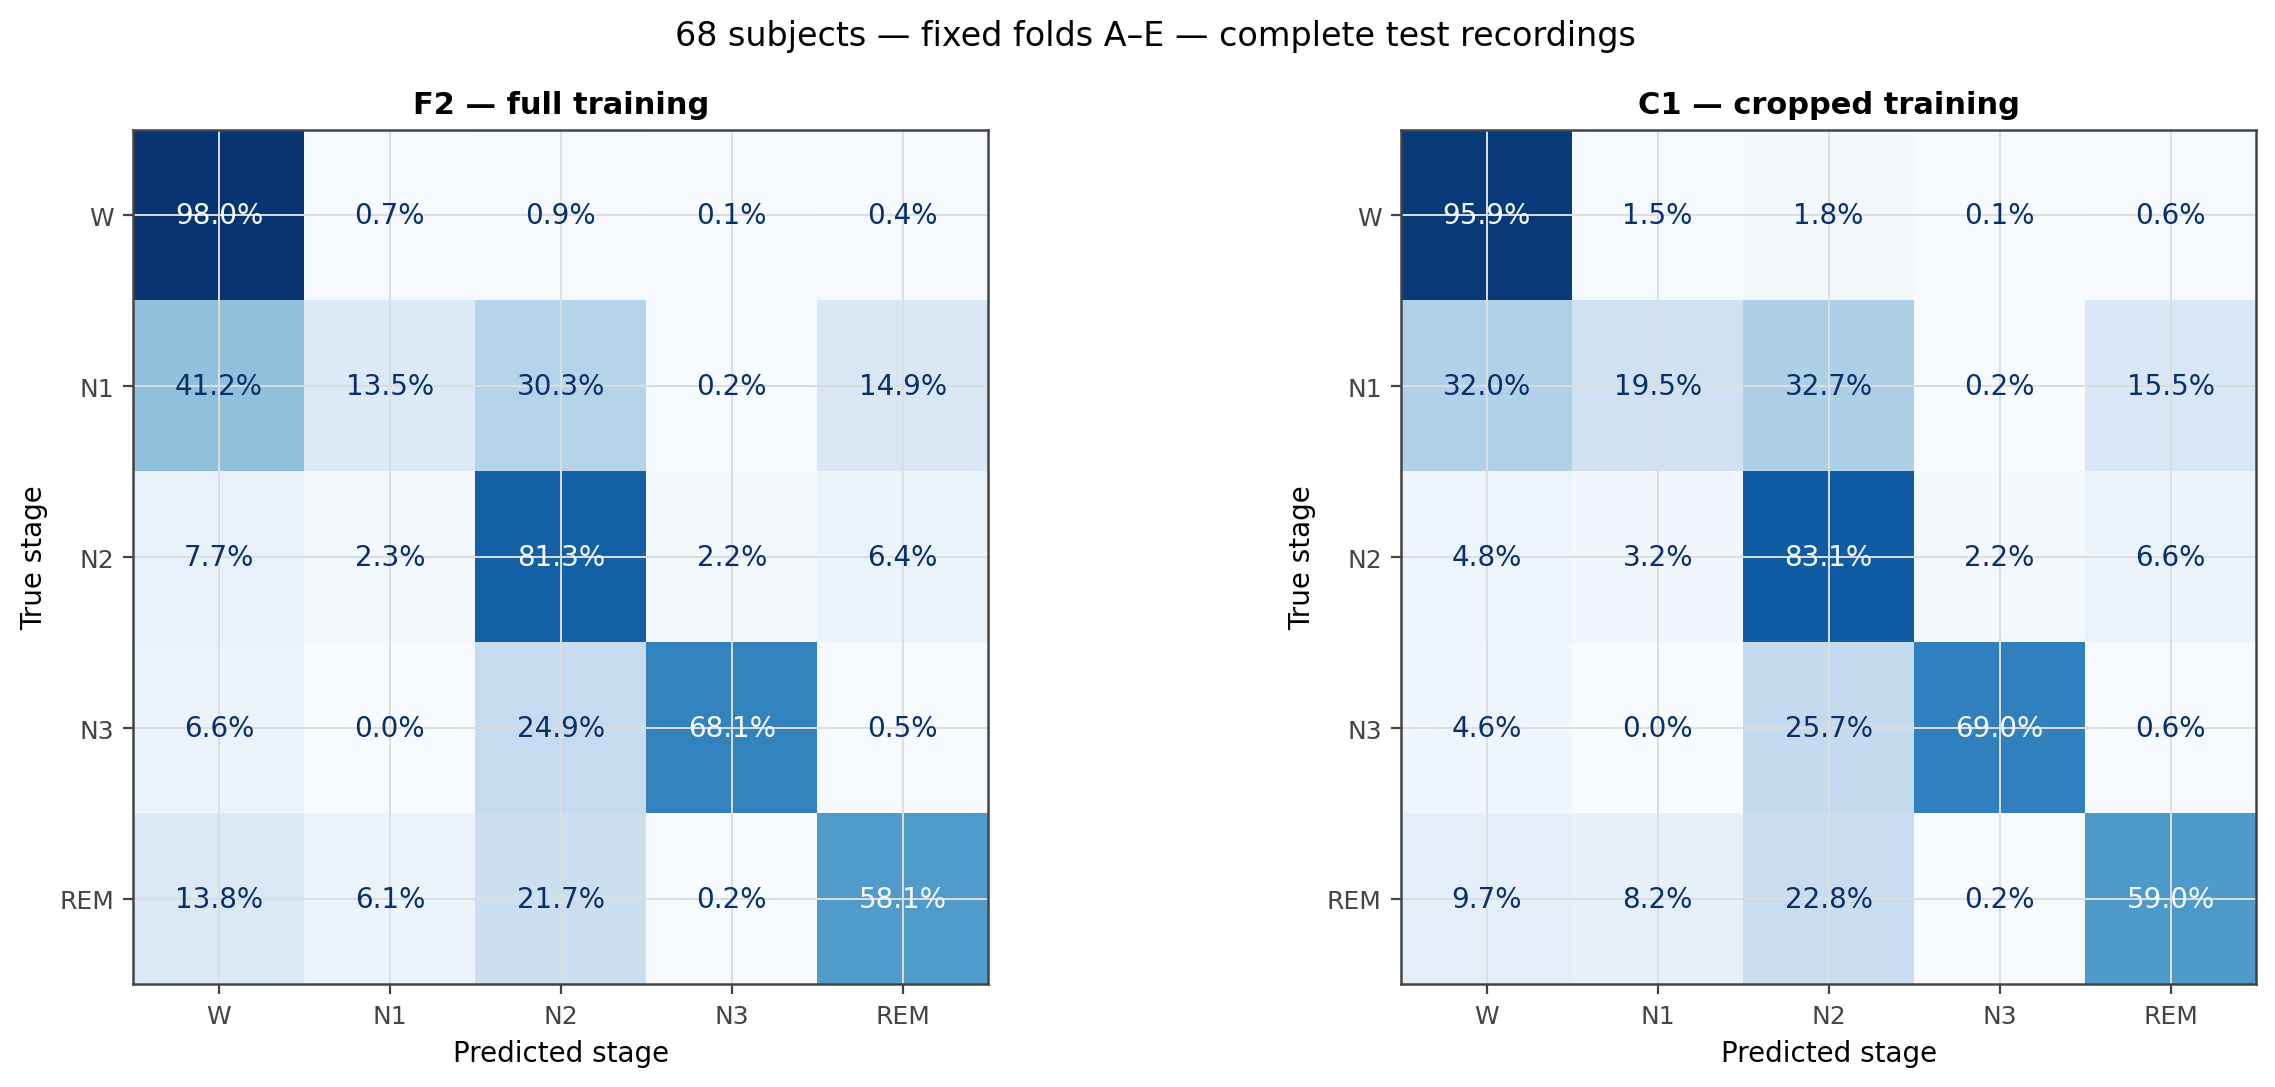

```text
NOS 68 PARTICIPANTES — antes de arredondar
Kappa aumentou: 36
Kappa diminuiu: 32
Kappa igual: 0

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/C1_68_crop30_fixed_AE_confusion.png
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 82
C1_CONFIG_68 = {
    "version": 1,
    "margin_minutes": 30.0,
    "epoch_seconds": 30.0,
    "time_basis": "original PSG event times in seconds",
    "selection": "complete epochs inside the sleep window plus margins",
    "scope": "training only",
    "no_sleep_policy": "keep all epochs",
}

# Os tempos são agora repostos uma única vez na secção 1.5.
# Localização de cada gravação na matriz completa de features.
limites = np.r_[
    0,
    np.cumsum([len(d["y"]) for d in b0_gravacoes_68])
]

SPLITS_C1_68 = {}
C1_JANELAS_68 = {}
linhas_resumo = []
linhas_distribuicao = []

estagios = ["W", "N1", "N2", "N3", "REM"]
margem = C1_CONFIG_68["margin_minutes"] * 60
epoca_s = C1_CONFIG_68["epoch_seconds"]


# 2 — Calcular o recorte apenas nas gravações de treino de cada fold.
for fold in "ABCDE":
    treino, teste = SPLITS_68[fold]
    sujeitos_treino = set(groups_b0_68[treino])

    partes_treino = []
    C1_JANELAS_68[fold] = {}

    for dados, inicio in zip(b0_gravacoes_68, limites[:-1]):
        record = dados["record"]

        if record[:5] not in sujeitos_treino:
            continue

        indices = np.arange(inicio, inicio + len(dados["y"]))
        labels = y_b0_68[indices]
        tempos, duracao = tempos_c1_68[record]

        sono = np.flatnonzero(
            np.isin(labels, ["N1", "N2", "N3", "REM"])
        )

        if len(sono):
            esquerda = max(0.0, tempos[sono[0]] - margem)
            direita = min(
                duracao, tempos[sono[-1]] + epoca_s + margem
            )
        else:
            esquerda, direita = 0.0, duracao

        manter = (
            (tempos >= esquerda - 1e-6)
            & (tempos + epoca_s <= direita + 1e-6)
        )

        # Nenhuma época de sono pode ser retirada.
        assert np.all(labels[~manter] == "W")

        partes_treino.append(indices[manter])
        C1_JANELAS_68[fold][record] = {
            "start_seconds": float(esquerda),
            "end_seconds": float(direita),
            "epochs_before": len(indices),
            "epochs_after": int(manter.sum()),
            "has_sleep": bool(len(sono)),
        }

    treino_c1 = np.concatenate(partes_treino)
    retiradas = np.setdiff1d(treino, treino_c1)

    assert np.all(np.isin(treino_c1, treino))
    assert np.intersect1d(treino_c1, teste).size == 0
    assert set(groups_b0_68[treino_c1]) == sujeitos_treino
    assert np.all(y_b0_68[retiradas] == "W")

    # Preservar os índices de teste originais.
    SPLITS_C1_68[fold] = (treino_c1, teste.copy())

    linhas_resumo.append({
        "Fold": fold,
        "Treino antes": len(treino),
        "Treino depois": len(treino_c1),
        "Wake retiradas": len(retiradas),
        "Teste completo": len(teste),
    })

    for estagio in estagios:
        linhas_distribuicao.append({
            "Fold": fold,
            "Estágio": estagio,
            "Antes (%)": 100 * np.mean(
                y_b0_68[treino] == estagio
            ),
            "Depois (%)": 100 * np.mean(
                y_b0_68[treino_c1] == estagio
            ),
        })


resumo_c1_68 = pd.DataFrame(linhas_resumo).set_index("Fold")
distribuicao_c1_68 = pd.DataFrame(
    linhas_distribuicao
).set_index(["Fold", "Estágio"])

print("\nC1_68 — QUANTIDADES DE ÉPOCAS")
display(resumo_c1_68)

print("\nDISTRIBUIÇÃO DOS ESTÁGIOS NO TREINO")
display(distribuicao_c1_68.round(2))

print("\nApenas Wake foi retirada dos conjuntos de treino.")
print("Os cinco conjuntos de teste continuam completos.")

# Célula original 83
import json
import platform
import scipy
import sklearn
from time import perf_counter
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

if "SleepEDFTrack" not in globals():
    from sleep_edf import SleepEDFTrack

# Confirmar as versões antes de começar os treinos.
runtime_c1_68 = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "mne": mne.__version__,
}

diferencas = {
    pacote: {
        "F2": config_f2_guardada_68["runtime"][pacote],
        "agora": runtime_c1_68[pacote],
    }
    for pacote in ["numpy", "scipy", "scikit-learn"]
    if runtime_c1_68[pacote] !=
       config_f2_guardada_68["runtime"][pacote]
}

if diferencas:
    raise RuntimeError(
        "Antes de treinar precisamos de alinhar as versões com o F2: "
        + str(diferencas)
    )

track_c1_68 = SleepEDFTrack(cfg={})

# Recriar o mesmo modelo usando os parâmetros guardados no F2.
modelo_base_c1_68 = Pipeline([
    ("scale", StandardScaler(
        **config_f2_guardada_68["scaler_params"]
    )),
    ("clf", RandomForestClassifier(
        **config_f2_guardada_68["classifier_params"]
    )),
])

NOME_C1_68 = "C1_68_crop30_fixed_AE"

campos_fold = {
    "fold", "training_subjects", "test_subjects",
    "test_indices", "fit_seconds", "predict_seconds", "report",
}

meta_c1_68 = {
    chave: valor
    for chave, valor in config_f2_guardada_68.items()
    if chave not in campos_fold
}

meta_c1_68.update({
    "experiment": NOME_C1_68,
    "runtime": runtime_c1_68,
    "reference_experiment": "F2_68_fixed_AE",
    "feature_cache_runtime": config_f2_guardada_68["runtime"],
    "training_selection": dict(C1_CONFIG_68),
})


def converter_json_c1_68(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    raise TypeError(f"Tipo não suportado: {type(obj).__name__}")


if "resultados_c1_68" not in globals():
    resultados_c1_68 = {}


def avaliar_fold_c1_68(fold):
    treino, teste = SPLITS_C1_68[fold]

    np.testing.assert_array_equal(
        teste, resultados_f2_68[fold]["test_indices"]
    )
    assert np.intersect1d(treino, teste).size == 0

    destino = EXPERIMENTS_DIR / f"{NOME_C1_68}_fold_{fold}.json"
    guardado_na_drive = destino.is_file()

    if guardado_na_drive:
        resultado = json.loads(
            destino.read_text(encoding="utf-8")
        )
        print(
            f"C1 — fold {fold}: resultado guardado encontrado.",
            flush=True,
        )

    elif fold in resultados_c1_68:
        resultado = resultados_c1_68[fold]
        print(
            f"C1 — fold {fold}: resultado recuperado da memória.",
            flush=True,
        )

    else:
        print(
            f"\nC1 — fold {fold}: a treinar com "
            f"{len(treino)} épocas...",
            flush=True,
        )

        modelo = clone(modelo_base_c1_68)

        inicio = perf_counter()
        modelo.fit(X_f2_68[treino], y_b0_68[treino])
        tempo_treino = perf_counter() - inicio

        inicio = perf_counter()
        previsoes = modelo.predict(X_f2_68[teste])
        tempo_previsao = perf_counter() - inicio

        relatorio = track_c1_68._make_report(
            y_b0_68[teste],
            previsoes,
            groups=groups_b0_68[teste],
        )

        resultado = {
            **meta_c1_68,
            "fold": fold,
            "training_subjects": sorted(set(groups_b0_68[treino])),
            "test_subjects": sorted(set(groups_b0_68[teste])),
            "train_indices": treino,
            "test_indices": teste,
            "training_windows": C1_JANELAS_68[fold],
            "fit_seconds": tempo_treino,
            "predict_seconds": tempo_previsao,
            "report": relatorio,
        }

    # Confirmar configuração e alinhamento antes de reutilizar/guardar.
    assert resultado["fold"] == fold

    for campo, valor in meta_c1_68.items():
        assert resultado[campo] == valor, (
            f"Configuração diferente no fold {fold}: {campo}"
        )

    np.testing.assert_array_equal(
        resultado["train_indices"], treino
    )
    np.testing.assert_array_equal(
        resultado["test_indices"], teste
    )
    np.testing.assert_array_equal(
        resultado["report"]["y_true"], y_b0_68[teste]
    )
    np.testing.assert_array_equal(
        resultado["report"]["y_group"], groups_b0_68[teste]
    )
    assert resultado["training_windows"] == C1_JANELAS_68[fold]

    # Preservar na memória antes de escrever na Drive.
    resultados_c1_68[fold] = resultado

    if not guardado_na_drive:
        temporario = destino.with_suffix(".tmp")
        temporario.write_text(
            json.dumps(
                resultado,
                default=converter_json_c1_68,
                indent=2,
            ),
            encoding="utf-8",
        )
        temporario.replace(destino)
        print("Guardado:", destino, flush=True)

    print(
        f"Fold {fold} concluído: "
        f"kappa = {resultado['report']['cohens_kappa']:.3f} | "
        f"treino = {resultado['fit_seconds'] / 60:.2f} min",
        flush=True,
    )

    return resultado


# Um novo modelo por fold, usando apenas o treino recortado.
for fold in "ABCDE":
    avaliar_fold_c1_68(fold)

metricas = [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]

tabela_c1_68 = pd.DataFrame([
    {
        "Fold": fold,
        **{
            m: resultados_c1_68[fold]["report"][m]
            for m in metricas
        },
        "Treino (min)": (
            resultados_c1_68[fold]["fit_seconds"] / 60
        ),
    }
    for fold in "ABCDE"
]).set_index("Fold")

print("\nC1 — CINCO FOLDS CONCLUÍDOS")
display(tabela_c1_68.round(3))

kappas_c1 = tabela_c1_68["cohens_kappa"]

print(
    "\nKappa médio ± SD entre os cinco folds: "
    f"{kappas_c1.mean():.3f} ± {kappas_c1.std(ddof=1):.3f}"
)
print(
    "Tempo total de treino: "
    f"{tabela_c1_68['Treino (min)'].sum():.1f} min"
)

comparacao_f2_c1_68 = pd.DataFrame({
    "F2": [
        resultados_f2_68[f]["report"]["cohens_kappa"]
        for f in "ABCDE"
    ],
    "C1": kappas_c1.to_numpy(),
}, index=pd.Index(list("ABCDE"), name="Fold"))

comparacao_f2_c1_68["Diferença"] = (
    comparacao_f2_c1_68["C1"] - comparacao_f2_c1_68["F2"]
)

print("\nCOMPARAÇÃO NOS MESMOS FOLDS")
display(comparacao_f2_c1_68.round(3))

# Célula original 84
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)


def reconstruir_oof_68(resultados):
    """Juntar as previsões de teste na ordem original das épocas."""
    assert set(resultados) == set("ABCDE")

    previsoes = np.empty_like(y_b0_68)
    folds = np.empty(len(y_b0_68), dtype="<U1")
    cobertura = np.zeros(len(y_b0_68), dtype=np.uint8)

    for fold in "ABCDE":
        resultado = resultados[fold]
        indices = np.asarray(resultado["test_indices"], dtype=int)
        report = resultado["report"]

        np.testing.assert_array_equal(
            indices, SPLITS_68[fold][1]
        )
        np.testing.assert_array_equal(
            report["y_true"], y_b0_68[indices]
        )
        np.testing.assert_array_equal(
            report["y_group"], groups_b0_68[indices]
        )

        assert len(report["y_pred"]) == len(indices)
        assert np.all(cobertura[indices] == 0)

        previsoes[indices] = report["y_pred"]
        folds[indices] = fold
        cobertura[indices] += 1

    assert np.all(cobertura == 1)

    relatorio = track_c1_68._make_report(
        y_b0_68,
        previsoes,
        groups=groups_b0_68,
        folds=folds,
    )

    return previsoes, relatorio


previsoes_f2_68, relatorio_f2_68 = reconstruir_oof_68(
    resultados_f2_68
)
previsoes_c1_68, relatorio_c1_68 = reconstruir_oof_68(
    resultados_c1_68
)

# 1 — Métricas globais das mesmas 360 621 épocas de teste.
metricas_globais = [
    "cohens_kappa",
    "macro_f1",
    "accuracy",
    "balanced_accuracy",
]

comparacao_global_f2_c1_68 = pd.DataFrame({
    "F2": {m: relatorio_f2_68[m] for m in metricas_globais},
    "C1": {m: relatorio_c1_68[m] for m in metricas_globais},
})
comparacao_global_f2_c1_68["Diferença"] = (
    comparacao_global_f2_c1_68["C1"]
    - comparacao_global_f2_c1_68["F2"]
)

print("COMPARAÇÃO — MÉTRICAS GLOBAIS")
display(comparacao_global_f2_c1_68.round(3))

# 2 — Resultados por estágio.
estagios = ["W", "N1", "N2", "N3", "REM"]

print("\nC1 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_c1_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

classes_f2 = classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)
classes_c1 = classification_report(
    y_b0_68,
    previsoes_c1_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)

comparacao_estagios_f2_c1_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall F2": classes_f2[estagio]["recall"],
        "Recall C1": classes_c1[estagio]["recall"],
        "F1 F2": classes_f2[estagio]["f1-score"],
        "F1 C1": classes_c1[estagio]["f1-score"],
        "Diferença F1": (
            classes_c1[estagio]["f1-score"]
            - classes_f2[estagio]["f1-score"]
        ),
    }
    for estagio in estagios
]).set_index("Estágio")

print("\nCOMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_f2_c1_68.round(3))

# 3 — Matrizes de confusão com a mesma escala.
fig_f2_c1_68, eixos = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, titulo, previsoes in zip(
    eixos,
    ["F2 — full training", "C1 — cropped training"],
    [previsoes_f2_68, previsoes_c1_68],
):
    matriz = ConfusionMatrixDisplay.from_predictions(
        y_b0_68,
        previsoes,
        labels=estagios,
        normalize="true",
        values_format=".1%",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    matriz.im_.set_clim(0, 1)
    ax.set_title(titulo)
    ax.set_xlabel("Predicted stage")
    ax.set_ylabel("True stage")

fig_f2_c1_68.suptitle(
    "68 subjects — fixed folds A–E — complete test recordings"
)
fig_f2_c1_68.tight_layout()
plt.show()

# Célula original 85
# Comparação de kappa por participante.
kappa_f2_pessoa = (
    pd.DataFrame(relatorio_f2_68["per_group"])
    .set_index("group")["cohens_kappa"]
)
kappa_c1_pessoa = (
    pd.DataFrame(relatorio_c1_68["per_group"])
    .set_index("group")["cohens_kappa"]
)

comparacao_participantes_f2_c1_68 = pd.DataFrame({
    "F2": kappa_f2_pessoa,
    "C1": kappa_c1_pessoa,
})
assert len(comparacao_participantes_f2_c1_68) == 68
assert not comparacao_participantes_f2_c1_68.isna().any().any()

comparacao_participantes_f2_c1_68["Diferença"] = (
    comparacao_participantes_f2_c1_68["C1"]
    - comparacao_participantes_f2_c1_68["F2"]
)
diferencas = comparacao_participantes_f2_c1_68["Diferença"]

print("NOS 68 PARTICIPANTES — antes de arredondar")
print("Kappa aumentou:", int((diferencas > 0).sum()))
print("Kappa diminuiu:", int((diferencas < 0).sum()))
print("Kappa igual:", int((diferencas == 0).sum()))

# Relatório consolidado.
exportacao_c1_68 = {
    **meta_c1_68,
    "split_unit": "subject",
    "cv_method": "five fixed subject folds A–E",
    "n_subjects": len(set(groups_b0_68)),
    "n_recordings": len(b0_gravacoes_68),
    "n_epochs": len(y_b0_68),
    "cv_mean_sd_across_folds": {
        metrica: {
            "mean": float(tabela_c1_68[metrica].mean()),
            "sd": float(tabela_c1_68[metrica].std(ddof=1)),
        }
        for metrica in metricas_globais
    },
    "sd_ddof": 1,
    "total_fit_seconds": sum(
        r["fit_seconds"] for r in resultados_c1_68.values()
    ),
    "fold_metrics": (
        tabela_c1_68.reset_index().to_dict(orient="records")
    ),
    "training_epoch_counts": (
        resumo_c1_68.reset_index().to_dict(orient="records")
    ),
    "training_class_distribution": (
        distribuicao_c1_68.reset_index().to_dict(orient="records")
    ),
    "training_windows": C1_JANELAS_68,
    "report": relatorio_c1_68,
    "classification_report": classes_c1,
    "comparison_vs_F2_global": (
        comparacao_global_f2_c1_68.rename_axis("metric")
        .reset_index().to_dict(orient="records")
    ),
    "comparison_vs_F2_stage": (
        comparacao_estagios_f2_c1_68.reset_index()
        .to_dict(orient="records")
    ),
    "comparison_vs_F2_subject_kappa": (
        comparacao_participantes_f2_c1_68.reset_index()
        .to_dict(orient="records")
    ),
    "working_decision": (
        "Retain F2_68 as reference. C1 improves N1, macro-F1 "
        "and balanced accuracy, but lowers primary kappa and "
        "increases fold variability. F1 declines for the other stages."
    ),
}

destino_json = EXPERIMENTS_DIR / f"{NOME_C1_68}.json"
temporario = destino_json.with_suffix(".tmp")
temporario.write_text(
    json.dumps(
        exportacao_c1_68,
        default=converter_json_c1_68,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
temporario.replace(destino_json)

# Matriz individual do C1, pronta para adicionar à folha da equipa.
fig_c1_68, ax = plt.subplots(figsize=(7, 6))

matriz_c1 = ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_c1_68,
    labels=["W", "N1", "N2", "N3", "REM"],
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
matriz_c1.im_.set_clim(0, 1)
ax.set_title("C1 — 68 subjects — fixed folds A–E")
fig_c1_68.tight_layout()

destino_imagem = (
    EXPERIMENTS_DIR / f"{NOME_C1_68}_confusion.png"
)
fig_c1_68.savefig(destino_imagem, dpi=200, bbox_inches="tight")
plt.close(fig_c1_68)

print("\nRelatório guardado:", destino_json)
print("Imagem guardada:", destino_imagem)
```

</details>

### 3.6 — LR1: outro classificador

<details>
<summary>Ver resultados guardados</summary>

Resultados anteriores. Não são recalculados ao executar a preparação diária.

```text
Experiência: LR1_68_fixed_AE
Dados: (360621, 16)
Folds: A, B, C, D, E
Única alteração: Random Forest → regressão logística
Preparado. Ainda não foi feito nenhum treino.
```


```text
LR1_68_fixed_AE — fold A: a treinar...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_fold_A.json
Fold A: kappa = 0.596 | treino = 0.73 min | iterações = 163
LR1_68_fixed_AE — fold B: a treinar...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_fold_B.json
Fold B: kappa = 0.550 | treino = 0.51 min | iterações = 165
LR1_68_fixed_AE — fold C: a treinar...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_fold_C.json
Fold C: kappa = 0.598 | treino = 0.53 min | iterações = 159
LR1_68_fixed_AE — fold D: a treinar...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_fold_D.json
Fold D: kappa = 0.608 | treino = 0.48 min | iterações = 147
LR1_68_fixed_AE — fold E: a treinar...
Guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_fold_E.json
Fold E: kappa = 0.606 | treino = 0.53 min | iterações = 169

LR1 — CINCO FOLDS CONCLUÍDOS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>cohens_kappa</th>
      <th>macro_f1</th>
      <th>accuracy</th>
      <th>balanced_accuracy</th>
      <th>Treino (min)</th>
    </tr>
    <tr>
      <th>Fold</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.596</td>
      <td>0.584</td>
      <td>0.776</td>
      <td>0.710</td>
      <td>0.734</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.550</td>
      <td>0.576</td>
      <td>0.735</td>
      <td>0.682</td>
      <td>0.513</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.598</td>
      <td>0.625</td>
      <td>0.766</td>
      <td>0.723</td>
      <td>0.532</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.608</td>
      <td>0.622</td>
      <td>0.795</td>
      <td>0.684</td>
      <td>0.483</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.606</td>
      <td>0.607</td>
      <td>0.772</td>
      <td>0.728</td>
      <td>0.528</td>
    </tr>
  </tbody>
</table>

```text
Kappa médio ± SD: 0.592 ± 0.024
Tempo total de treino: 2.8 min

COMPARAÇÃO DO KAPPA NOS MESMOS FOLDS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>LR1</th>
      <th>Diferença</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>A</th>
      <td>0.753</td>
      <td>0.596</td>
      <td>-0.157</td>
    </tr>
    <tr>
      <th>B</th>
      <td>0.718</td>
      <td>0.550</td>
      <td>-0.168</td>
    </tr>
    <tr>
      <th>C</th>
      <td>0.739</td>
      <td>0.598</td>
      <td>-0.141</td>
    </tr>
    <tr>
      <th>D</th>
      <td>0.717</td>
      <td>0.608</td>
      <td>-0.109</td>
    </tr>
    <tr>
      <th>E</th>
      <td>0.748</td>
      <td>0.606</td>
      <td>-0.142</td>
    </tr>
  </tbody>
</table>

```text
COMPARAÇÃO — MÉTRICAS GLOBAIS
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>F2</th>
      <th>LR1</th>
      <th>Diferença</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>cohens_kappa</th>
      <td>0.735</td>
      <td>0.591</td>
      <td>-0.144</td>
    </tr>
    <tr>
      <th>macro_f1</th>
      <td>0.659</td>
      <td>0.600</td>
      <td>-0.059</td>
    </tr>
    <tr>
      <th>accuracy</th>
      <td>0.876</td>
      <td>0.768</td>
      <td>-0.108</td>
    </tr>
    <tr>
      <th>balanced_accuracy</th>
      <td>0.638</td>
      <td>0.705</td>
      <td>0.067</td>
    </tr>
  </tbody>
</table>

```text

LR1 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.980     0.820     0.893    248341
          N1      0.181     0.456     0.259     17877
          N2      0.781     0.650     0.710     60494
          N3      0.418     0.901     0.571     11610
         REM      0.482     0.699     0.570     22299

    accuracy                          0.768    360621
   macro avg      0.568     0.705     0.600    360621
weighted avg      0.858     0.768     0.800    360621

COMPARAÇÃO POR ESTÁGIO
```


<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Recall F2</th>
      <th>Recall LR1</th>
      <th>F1 F2</th>
      <th>F1 LR1</th>
      <th>Diferença F1</th>
    </tr>
    <tr>
      <th>Estágio</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>W</th>
      <td>0.980</td>
      <td>0.820</td>
      <td>0.959</td>
      <td>0.893</td>
      <td>-0.066</td>
    </tr>
    <tr>
      <th>N1</th>
      <td>0.135</td>
      <td>0.456</td>
      <td>0.195</td>
      <td>0.259</td>
      <td>0.064</td>
    </tr>
    <tr>
      <th>N2</th>
      <td>0.813</td>
      <td>0.650</td>
      <td>0.786</td>
      <td>0.710</td>
      <td>-0.077</td>
    </tr>
    <tr>
      <th>N3</th>
      <td>0.681</td>
      <td>0.901</td>
      <td>0.751</td>
      <td>0.571</td>
      <td>-0.180</td>
    </tr>
    <tr>
      <th>REM</th>
      <td>0.581</td>
      <td>0.699</td>
      <td>0.605</td>
      <td>0.570</td>
      <td>-0.034</td>
    </tr>
  </tbody>
</table>

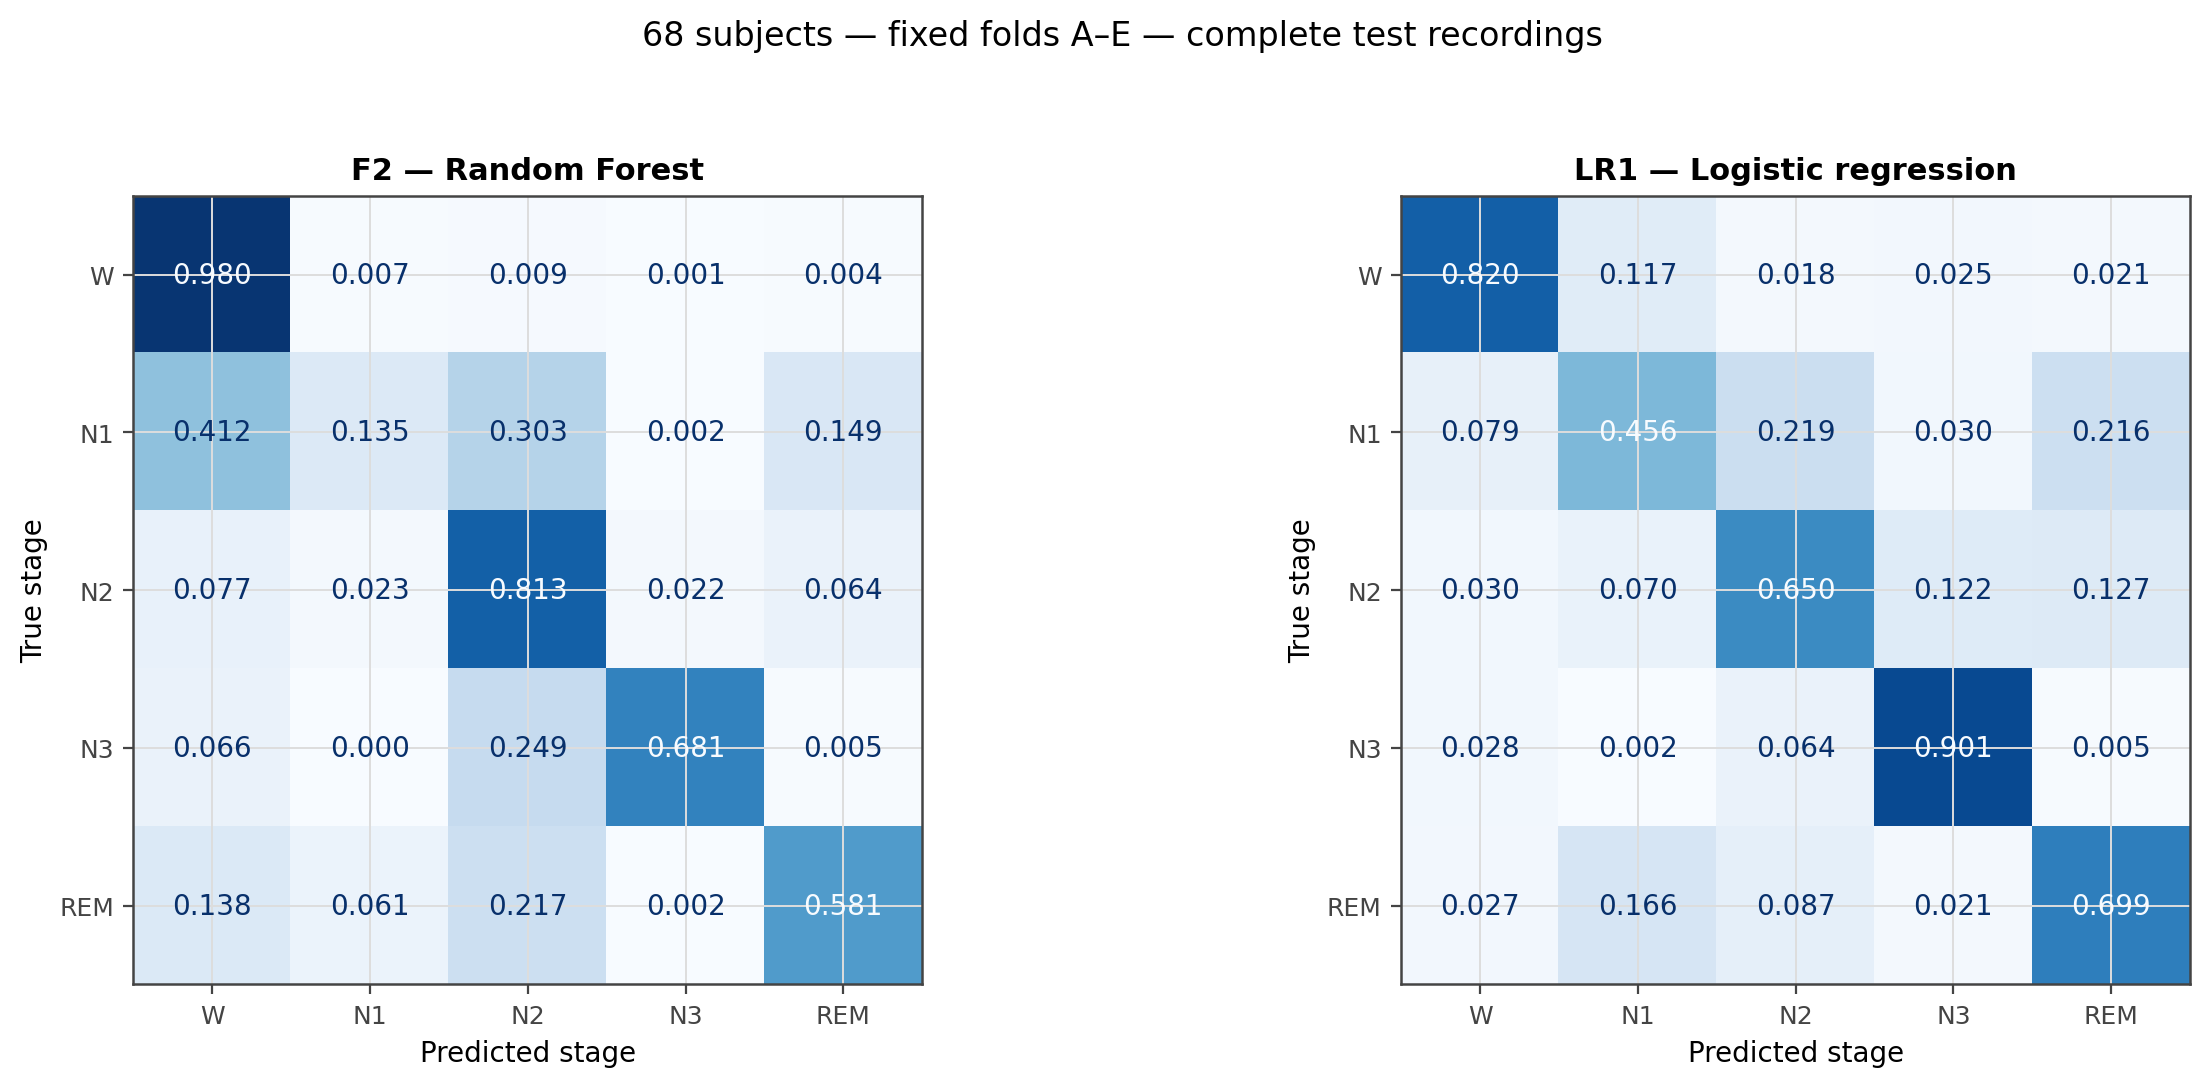

```text
NOS 68 PARTICIPANTES — antes de arredondar
Kappa aumentou: 5
Kappa diminuiu: 63
Kappa igual: 0

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/LR1_68_fixed_AE_confusion.png
```


</details>

<details>
<summary>Ver o código da experiência anterior</summary>

Este bloco é um arquivo de consulta em Markdown; não é executado por «Executar tudo».

```python
# Célula original 86
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

necessarias = [
    "X_f2_68",
    "y_b0_68",
    "groups_b0_68",
    "SPLITS_68",
    "config_f2_guardada_68",
]

em_falta = [nome for nome in necessarias if nome not in globals()]

if em_falta:
    raise RuntimeError(
        "É necessário repor estas variáveis: " + ", ".join(em_falta)
    )

assert X_f2_68.shape == (360621, 16)
assert len(y_b0_68) == len(groups_b0_68) == len(X_f2_68)
assert set(SPLITS_68) == set("ABCDE")

NOME_LR1_68 = "LR1_68_fixed_AE"

CONFIG_LR1_68 = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 2000,
    "tol": 1e-4,
}

modelo_base_lr1_68 = Pipeline([
    (
        "scale",
        StandardScaler(
            **config_f2_guardada_68["scaler_params"]
        ),
    ),
    ("clf", LogisticRegression(**CONFIG_LR1_68)),
])

print("Experiência:", NOME_LR1_68)
print("Dados:", X_f2_68.shape)
print("Folds: A, B, C, D, E")
print("Única alteração: Random Forest → regressão logística")
print("Preparado. Ainda não foi feito nenhum treino.")

# Célula original 87
import copy
import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
SleepEDFTrack = type(track_c1_68)

# F2 completo: sem filtro adicional e sem corte de Wake.
assert X_f2_68.shape == (360621, 16)
assert np.isfinite(X_f2_68).all()
assert set(SPLITS_68) == set(resultados_f2_68) == set("ABCDE")
assert (
    len(y_b0_68)
    == len(groups_b0_68)
    == len(record_ids_b0_68)
    == len(X_f2_68)
)
assert len(np.unique(groups_b0_68)) == 68
assert len(np.unique(record_ids_b0_68)) == 133


def converter_json_lr1_68(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    raise TypeError(type(obj).__name__)


def assinatura_lr1_68(*arrays):
    h = hashlib.sha256()

    for arr in arrays:
        a = np.asarray(arr)

        if a.dtype.kind in "OUS":
            a = a.astype(str)

        a = np.ascontiguousarray(a)
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(memoryview(a).cast("B"))

    return h.hexdigest()


runtime_lr1_68 = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}

for pacote in ("numpy", "scipy", "scikit-learn"):
    anterior = config_f2_guardada_68.get("runtime", {}).get(pacote)

    if anterior is not None and anterior != runtime_lr1_68[pacote]:
        raise RuntimeError(
            f"Versão diferente do F2: {pacote}. Envia o aviso."
        )

# Confirmar os mesmos conjuntos de teste do F2,
# sujeitos separados e treino completo.
cobertura_lr1_68 = np.zeros(len(y_b0_68), dtype=np.uint8)

for fold in "ABCDE":
    tr, te = (
        np.asarray(idx, dtype=int)
        for idx in SPLITS_68[fold]
    )

    assert np.all((tr >= 0) & (tr < len(y_b0_68)))
    assert np.all((te >= 0) & (te < len(y_b0_68)))
    assert len(tr) + len(te) == len(y_b0_68)

    assert (
        len(np.unique(np.concatenate([tr, te])))
        == len(y_b0_68)
    )

    assert set(groups_b0_68[tr]).isdisjoint(
        set(groups_b0_68[te])
    )

    ref = resultados_f2_68[fold]

    np.testing.assert_array_equal(te, ref["test_indices"])
    np.testing.assert_array_equal(
        y_b0_68[te], ref["report"]["y_true"]
    )
    np.testing.assert_array_equal(
        groups_b0_68[te], ref["report"]["y_group"]
    )

    cobertura_lr1_68[te] += 1

assert np.all(cobertura_lr1_68 == 1)

# Configuração e identificação dos dados para verificar
# se um resultado guardado pode ser reutilizado.
meta_lr1_68 = {
    "experiment": NOME_LR1_68,
    "reference": "F2_68_fixed_AE",
    "course_revision": "5949b723bbd34d172f072446dfcb802ef54b49f7",
    "split_unit": "subject",
    "cv_method": "five fixed subject folds A-E",
    "n_subjects": 68,
    "n_recordings": 133,
    "n_epochs": len(y_b0_68),
    "feature_names": list(nomes_features_f2_68),
    "feature_recipe": (
        "F2 version 1: original 11 plus five relative powers"
    ),
    "additional_filter": None,
    "training_selection": "all retained epochs",
    "data_sha256": assinatura_lr1_68(
        X_f2_68,
        y_b0_68,
        groups_b0_68,
        record_ids_b0_68,
    ),
    "runtime": runtime_lr1_68,
    "feature_cache_runtime": (
        config_f2_guardada_68.get("runtime", {})
    ),
    "classifier_params": (
        modelo_base_lr1_68.named_steps["clf"].get_params()
    ),
    "scaler_params": (
        modelo_base_lr1_68.named_steps["scale"].get_params()
    ),
}

meta_lr1_68 = json.loads(
    json.dumps(
        meta_lr1_68,
        default=converter_json_lr1_68,
    )
)

track_lr1_68 = SleepEDFTrack(cfg={})
resultados_lr1_68 = globals().get("resultados_lr1_68", {})

EXPERIMENTS_DIR = Path(EXPERIMENTS_DIR)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)


def avaliar_fold_lr1_68(fold):
    tr, te = (
        np.asarray(idx, dtype=int)
        for idx in SPLITS_68[fold]
    )

    destino = (
        EXPERIMENTS_DIR
        / f"{NOME_LR1_68}_fold_{fold}.json"
    )

    guardar = False

    if destino.exists():
        r = json.loads(
            destino.read_text(encoding="utf-8")
        )

    elif fold in resultados_lr1_68:
        r = resultados_lr1_68[fold]
        guardar = True

    else:
        print(
            f"{NOME_LR1_68} — fold {fold}: a treinar...",
            flush=True,
        )

        # Novo scaler e novo classificador em cada fold.
        modelo = clone(modelo_base_lr1_68)

        inicio = time.perf_counter()

        with warnings.catch_warnings():
            warnings.simplefilter(
                "error", ConvergenceWarning
            )
            modelo.fit(
                X_f2_68[tr],
                y_b0_68[tr],
            )

        fit_seconds = time.perf_counter() - inicio
        n_iter = modelo.named_steps["clf"].n_iter_

        if np.any(
            n_iter >= modelo.named_steps["clf"].max_iter
        ):
            raise RuntimeError(
                "O ajuste atingiu max_iter. Envia este aviso."
            )

        inicio = time.perf_counter()
        pred = modelo.predict(X_f2_68[te])
        predict_seconds = time.perf_counter() - inicio

        r = {
            "metadata": copy.deepcopy(meta_lr1_68),
            "fold": fold,
            "created_at_utc": (
                datetime.now(timezone.utc).isoformat()
            ),
            "train_indices": tr,
            "test_indices": te,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
            "n_iter": n_iter,
            "converged": True,
            "report": track_lr1_68._make_report(
                y_b0_68[te],
                pred,
                groups=groups_b0_68[te],
                folds=np.full(len(te), fold),
            ),
        }

        guardar = True

    # Verificar também os resultados carregados da Drive.
    assert r["metadata"] == meta_lr1_68, (
        "Configuração diferente: não reutilizar."
    )
    assert r["fold"] == fold and r["converged"]

    np.testing.assert_array_equal(
        r["train_indices"], tr
    )
    np.testing.assert_array_equal(
        r["test_indices"], te
    )
    np.testing.assert_array_equal(
        r["report"]["y_true"], y_b0_68[te]
    )
    np.testing.assert_array_equal(
        r["report"]["y_group"], groups_b0_68[te]
    )

    assert len(r["report"]["y_pred"]) == len(te)

    # Preservar em RAM antes de escrever na Drive.
    resultados_lr1_68[fold] = r

    if guardar:
        temporario = destino.with_suffix(".tmp")

        temporario.write_text(
            json.dumps(
                r,
                default=converter_json_lr1_68,
                indent=2,
            ),
            encoding="utf-8",
        )

        temporario.replace(destino)
        print("Guardado:", destino)

    else:
        print(
            f"Fold {fold}: resultado guardado reutilizado."
        )

    print(
        f"Fold {fold}: "
        f"kappa = {r['report']['cohens_kappa']:.3f}"
        f" | treino = {r['fit_seconds']/60:.2f} min"
        f" | iterações = {int(np.max(r['n_iter']))}",
        flush=True,
    )


# Executar os cinco folds.
for fold in "ABCDE":
    avaliar_fold_lr1_68(fold)


# Resumo das métricas por fold.
metricas_lr1_68 = [
    "cohens_kappa",
    "macro_f1",
    "accuracy",
    "balanced_accuracy",
]

tabela_lr1_68 = pd.DataFrame([
    {
        "Fold": fold,
        **{
            m: resultados_lr1_68[fold]["report"][m]
            for m in metricas_lr1_68
        },
        "Treino (min)": (
            resultados_lr1_68[fold]["fit_seconds"] / 60
        ),
    }
    for fold in "ABCDE"
]).set_index("Fold")

print("\nLR1 — CINCO FOLDS CONCLUÍDOS")
display(tabela_lr1_68.round(3))

print(
    f"Kappa médio ± SD: "
    f"{tabela_lr1_68['cohens_kappa'].mean():.3f}"
    f" ± {tabela_lr1_68['cohens_kappa'].std(ddof=1):.3f}"
)

print(
    f"Tempo total de treino: "
    f"{tabela_lr1_68['Treino (min)'].sum():.1f} min"
)

comparacao_f2_lr1_68 = pd.DataFrame({
    "F2": {
        f: resultados_f2_68[f]["report"]["cohens_kappa"]
        for f in "ABCDE"
    },
    "LR1": tabela_lr1_68["cohens_kappa"],
})

comparacao_f2_lr1_68["Diferença"] = (
    comparacao_f2_lr1_68["LR1"]
    - comparacao_f2_lr1_68["F2"]
)

print("\nCOMPARAÇÃO DO KAPPA NOS MESMOS FOLDS")
display(comparacao_f2_lr1_68.round(3))

# Célula original 88
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

ESTAGIOS_LR1_68 = ["W", "N1", "N2", "N3", "REM"]


def juntar_oof_lr1_68(resultados):
    assert set(resultados) == set("ABCDE")

    previsoes = np.empty_like(y_b0_68)
    folds = np.empty(len(y_b0_68), dtype="<U1")
    cobertura = np.zeros(len(y_b0_68), dtype=np.uint8)

    for fold in "ABCDE":
        r = resultados[fold]
        idx = np.asarray(r["test_indices"], dtype=int)
        rep = r["report"]
        pred = np.asarray(rep["y_pred"])

        np.testing.assert_array_equal(
            idx, SPLITS_68[fold][1]
        )
        np.testing.assert_array_equal(
            rep["y_true"], y_b0_68[idx]
        )
        np.testing.assert_array_equal(
            rep["y_group"], groups_b0_68[idx]
        )

        assert len(np.unique(idx)) == len(idx)
        assert pred.shape == (len(idx),)
        assert np.isin(pred, ESTAGIOS_LR1_68).all()
        assert np.all(cobertura[idx] == 0)

        previsoes[idx] = pred
        folds[idx] = fold
        cobertura[idx] += 1

    assert np.all(cobertura == 1)

    relatorio = track_lr1_68._make_report(
        y_b0_68,
        previsoes,
        groups=groups_b0_68,
        folds=folds,
    )

    return previsoes, relatorio


assert all(
    r["converged"] and r["metadata"] == meta_lr1_68
    for r in resultados_lr1_68.values()
)

previsoes_lr1_68, relatorio_lr1_68 = juntar_oof_lr1_68(
    resultados_lr1_68
)

previsoes_f2_68, relatorio_f2_68 = juntar_oof_lr1_68(
    resultados_f2_68
)

# Métricas calculadas juntando todas as previsões de teste.
metricas_lr1_68 = [
    "cohens_kappa",
    "macro_f1",
    "accuracy",
    "balanced_accuracy",
]

comparacao_global_f2_lr1_68 = pd.DataFrame({
    "F2": {
        m: relatorio_f2_68[m]
        for m in metricas_lr1_68
    },
    "LR1": {
        m: relatorio_lr1_68[m]
        for m in metricas_lr1_68
    },
})

comparacao_global_f2_lr1_68["Diferença"] = (
    comparacao_global_f2_lr1_68["LR1"]
    - comparacao_global_f2_lr1_68["F2"]
)

print("COMPARAÇÃO — MÉTRICAS GLOBAIS")
display(comparacao_global_f2_lr1_68.round(3))

print("\nLR1 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_lr1_68,
    labels=ESTAGIOS_LR1_68,
    digits=3,
    zero_division=0,
))

classes_f2_lr1_68 = classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=ESTAGIOS_LR1_68,
    output_dict=True,
    zero_division=0,
)

classes_lr1_68 = classification_report(
    y_b0_68,
    previsoes_lr1_68,
    labels=ESTAGIOS_LR1_68,
    output_dict=True,
    zero_division=0,
)

comparacao_estagios_f2_lr1_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall F2": classes_f2_lr1_68[estagio]["recall"],
        "Recall LR1": classes_lr1_68[estagio]["recall"],
        "F1 F2": classes_f2_lr1_68[estagio]["f1-score"],
        "F1 LR1": classes_lr1_68[estagio]["f1-score"],
        "Diferença F1": (
            classes_lr1_68[estagio]["f1-score"]
            - classes_f2_lr1_68[estagio]["f1-score"]
        ),
    }
    for estagio in ESTAGIOS_LR1_68
]).set_index("Estágio")

print("COMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_f2_lr1_68.round(3))

# Mesma ordem de estágios e escala de cores nas duas matrizes.
fig_f2_lr1_68, axes = plt.subplots(
    1, 2, figsize=(13, 5.5)
)

for ax, pred, titulo in [
    (axes[0], previsoes_f2_68, "F2 — Random Forest"),
    (axes[1], previsoes_lr1_68, "LR1 — Logistic regression"),
]:
    matriz = ConfusionMatrixDisplay.from_predictions(
        y_b0_68,
        pred,
        labels=ESTAGIOS_LR1_68,
        normalize="true",
        values_format=".3f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    matriz.im_.set_clim(0, 1)
    ax.set_title(titulo)
    ax.set_xlabel("Predicted stage")
    ax.set_ylabel("True stage")

fig_f2_lr1_68.suptitle(
    "68 subjects — fixed folds A–E — complete test recordings"
)
fig_f2_lr1_68.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

# Célula original 89
# Comparação por participante, antes de arredondar.
kappa_f2_lr1_68 = (
    pd.DataFrame(relatorio_f2_68["per_group"])
    .set_index("group")["cohens_kappa"]
)

kappa_lr1_68 = (
    pd.DataFrame(relatorio_lr1_68["per_group"])
    .set_index("group")["cohens_kappa"]
)

comparacao_participantes_f2_lr1_68 = pd.DataFrame({
    "F2": kappa_f2_lr1_68,
    "LR1": kappa_lr1_68,
}).sort_index()

assert len(comparacao_participantes_f2_lr1_68) == 68
assert comparacao_participantes_f2_lr1_68.index.is_unique
assert not comparacao_participantes_f2_lr1_68.isna().any().any()

comparacao_participantes_f2_lr1_68["Diferença"] = (
    comparacao_participantes_f2_lr1_68["LR1"]
    - comparacao_participantes_f2_lr1_68["F2"]
)

dif_lr1_68 = comparacao_participantes_f2_lr1_68["Diferença"]

print("NOS 68 PARTICIPANTES — antes de arredondar")
print("Kappa aumentou:", int((dif_lr1_68 > 0).sum()))
print("Kappa diminuiu:", int((dif_lr1_68 < 0).sum()))
print("Kappa igual:", int((dif_lr1_68 == 0).sum()))

# Relatório consolidado.
exportacao_lr1_68 = {
    **meta_lr1_68,

    "cv_mean_sd_across_folds": {
        m: {
            "mean": float(tabela_lr1_68[m].mean()),
            "sd": float(tabela_lr1_68[m].std(ddof=1)),
        }
        for m in metricas_lr1_68
    },
    "sd_ddof": 1,

    "fold_metrics": (
        tabela_lr1_68.reset_index()
        .to_dict(orient="records")
    ),

    "total_fit_seconds": sum(
        float(r["fit_seconds"])
        for r in resultados_lr1_68.values()
    ),

    "total_predict_seconds": sum(
        float(r["predict_seconds"])
        for r in resultados_lr1_68.values()
    ),

    "iterations_per_fold": {
        f: resultados_lr1_68[f]["n_iter"]
        for f in "ABCDE"
    },

    "all_folds_converged": all(
        r["converged"]
        for r in resultados_lr1_68.values()
    ),

    "report": relatorio_lr1_68,
    "classification_report": classes_lr1_68,

    "comparison_vs_F2_fold_kappa": (
        comparacao_f2_lr1_68.rename_axis("fold")
        .reset_index().to_dict(orient="records")
    ),

    "comparison_vs_F2_global": (
        comparacao_global_f2_lr1_68.rename_axis("metric")
        .reset_index().to_dict(orient="records")
    ),

    "comparison_vs_F2_stage": (
        comparacao_estagios_f2_lr1_68.reset_index()
        .to_dict(orient="records")
    ),

    "comparison_vs_F2_subject_kappa": (
        comparacao_participantes_f2_lr1_68.reset_index()
        .to_dict(orient="records")
    ),

    "working_decision": (
        "Retain F2_68 with Random Forest as the reference. "
        "LR1 is faster and improves balanced accuracy and N1 F1, "
        "but lowers kappa in all five folds, pooled kappa, "
        "macro-F1, accuracy and F1 for the other four stages."
    ),
}

destino_json_lr1_68 = (
    EXPERIMENTS_DIR / f"{NOME_LR1_68}.json"
)
temporario_lr1_68 = destino_json_lr1_68.with_suffix(".tmp")

temporario_lr1_68.write_text(
    json.dumps(
        exportacao_lr1_68,
        default=converter_json_lr1_68,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

temporario_lr1_68.replace(destino_json_lr1_68)
print("\nRelatório guardado:", destino_json_lr1_68)

# Imagem individual para o relatório e para o Excel.
fig_lr1_68, ax_lr1_68 = plt.subplots(figsize=(7, 6))

matriz_lr1_68 = ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_lr1_68,
    labels=ESTAGIOS_LR1_68,
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    ax=ax_lr1_68,
)

matriz_lr1_68.im_.set_clim(0, 1)
ax_lr1_68.set_title("LR1 — 68 subjects — fixed folds A–E")
ax_lr1_68.set_xlabel("Predicted stage")
ax_lr1_68.set_ylabel("True stage")
fig_lr1_68.tight_layout()

destino_imagem_lr1_68 = (
    EXPERIMENTS_DIR / f"{NOME_LR1_68}_confusion.png"
)

fig_lr1_68.savefig(
    destino_imagem_lr1_68,
    dpi=200,
    bbox_inches="tight",
)
plt.close(fig_lr1_68)

print("Imagem guardada:", destino_imagem_lr1_68)
```

</details>

## 4 — Próxima experiência: contexto temporal com Random Forest

### 4.1 — Preparar as features TC1

Este é um novo candidato, **ainda não avaliado**. Mantém o Random Forest do F2,
todos os dados de treino e os mesmos testes A–E. Não acrescenta LPF nem corte de Wake.

| Bloco | Número de features |
|---|---:|
| Features F2 da época atual | 16 |
| Features F2 da época imediatamente anterior | 16 |
| Indicador de anterior disponível | 1 |
| Total | 33 |

A anterior só é utilizada dentro da mesma gravação e quando está exatamente
30 segundos antes, com tolerância de 1 microsegundo. No início ou após um intervalo,
o bloco anterior repete as features atuais e o indicador fica a zero. Não é usada
nenhuma label anterior ou futura como entrada. As labels só entram no treino e
na avaliação, como nos outros modelos.

A preparação seguinte é uma transformação fixa de features já calculadas.
Não ajusta o scaler nem o Random Forest e não guarda outra cópia da matriz na Drive.
Se este método mudar, aumenta `TC1_FEATURE_VERSION` e regista a alteração.

In [17]:
# Preparação de contexto: operações fixas por gravação, sem ajuste.
assert SESSAO_PRONTA, "Executa primeiro a secção 1 completa."
TC1_FEATURE_VERSION = 1
NOME_TC1_68 = "TC1_68_fixed_AE"
TC1_CONFIG_68 = {
    "version": TC1_FEATURE_VERSION,
    "base_features": "F2 version 1, original 11 plus five relative EEG powers",
    "previous_epochs": 1,
    "direction": "past only",
    "epoch_seconds": EPOCH_SECONDS_68,
    "consecutive_tolerance_seconds": CONSECUTIVE_TOL_68,
    "require_same_recording": True,
    "missing_previous": "copy current features and set availability flag to zero",
    "availability_flag": True,
    "additional_filter": None,
    "training_selection": "all retained epochs",
    "label_inputs": False,
}

def preparar_contexto_anterior_68():
    validas = np.asarray(anterior_consecutiva_68, dtype=bool)
    assert validas.shape == (len(X_f2_68),) and not validas[0]
    indices = np.flatnonzero(validas)
    assert np.all(record_ids_b0_68[indices] == record_ids_b0_68[indices - 1])
    np.testing.assert_allclose(
        onsets_epocas_68[indices] - onsets_epocas_68[indices - 1],
        EPOCH_SECONDS_68, rtol=0, atol=CONSECUTIVE_TOL_68,
    )
    anteriores = X_f2_68.copy()
    anteriores[indices] = X_f2_68[indices - 1]
    X_contexto = np.column_stack([X_f2_68, anteriores, validas.astype(float)])
    nomes = (
        list(nomes_features_f2_68)
        + [f"previous_{n}" for n in nomes_features_f2_68]
        + ["previous_epoch_available"]
    )
    assert X_contexto.shape == (len(y_b0_68), 33)
    assert np.isfinite(X_contexto).all()
    np.testing.assert_array_equal(X_contexto[:, :16], X_f2_68)
    np.testing.assert_array_equal(X_contexto[indices, 16:32], X_f2_68[indices - 1])
    return X_contexto, nomes

X_tc1_68, nomes_features_tc1_68 = preparar_contexto_anterior_68()
print("TC1 preparado:", X_tc1_68.shape)
print("16 features atuais + 16 anteriores + 1 indicador de anterior disponível.")
print("Mesmas labels e mesmos folds A–E. Ainda sem treino.")


TC1 preparado: (360621, 33)
16 features atuais + 16 anteriores + 1 indicador de anterior disponível.
Mesmas labels e mesmos folds A–E. Ainda sem treino.


### 4.2 — Começar um novo treino apenas quando quiseres

Na rotina diária, deixa `RUN_TC1_68 = False` e usa «Executar tudo».

Para iniciar o TC1 depois de revermos a preparação: muda a opção para `True` na
célula 1.1 e volta a usar «Executar tudo». A preparação reutiliza os caches;
as experiências das secções 2 e 3 permanecem apenas em consulta. Volta a pôr a
opção a `False` na próxima preparação diária.

Cada fold é guardado; uma repetição com a mesma configuração reutiliza os folds
já concluídos. Configurações ou dados diferentes não substituem resultados antigos.
O painel inclui métricas por fold, média/SD, resultados globais, estágios,
participantes e matrizes de confusão.

Depois do TC1, escolhemos algumas combinações de estratégias com base nas
comparações individuais. O treino final com todos os 68 e a submissão dos dez
reservados ficam para depois da escolha do método e do commit de `EXPECTED_SCORE.md`.

TC1_68_fixed_AE — fold A: a treinar...
Fold A: kappa 0.774 | treino 7.10 min
TC1_68_fixed_AE — fold B: a treinar...
Fold B: kappa 0.732 | treino 6.95 min
TC1_68_fixed_AE — fold C: a treinar...
Fold C: kappa 0.749 | treino 7.44 min
TC1_68_fixed_AE — fold D: a treinar...
Fold D: kappa 0.731 | treino 7.27 min
TC1_68_fixed_AE — fold E: a treinar...
Fold E: kappa 0.770 | treino 7.12 min
MÉTRICAS POR FOLD


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.774,0.701,0.895,0.693,7.103
B,0.732,0.664,0.869,0.650,6.951
C,0.749,0.663,0.882,0.631,7.442
D,0.731,0.657,0.881,0.614,7.266
E,0.770,0.697,0.888,0.677,7.117


Kappa médio ± SD dos folds: 0.751 ± 0.020
Treino total: 35.9 min

MÉTRICAS GLOBAIS


,F2,TC1_68_fixed_AE,Diferença
cohens_kappa,0.735,0.751,0.016
macro_f1,0.659,0.677,0.018
accuracy,0.876,0.883,0.007
balanced_accuracy,0.638,0.654,0.016



RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.942     0.981     0.961    248341
          N1      0.406     0.153     0.223     17877
          N2      0.772     0.832     0.801     60494
          N3      0.849     0.689     0.761     11610
         REM      0.671     0.615     0.642     22299

    accuracy                          0.883    360621
   macro avg      0.728     0.654     0.677    360621
weighted avg      0.867     0.883     0.871    360621


Participantes — kappa antes de arredondar: 62 aumentaram | 6 diminuíram | 0 iguais


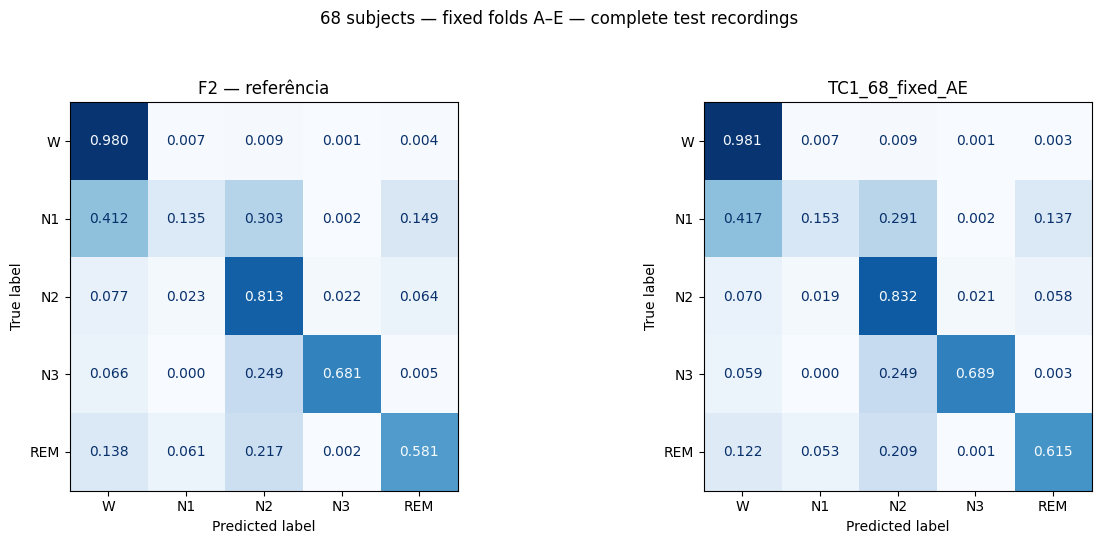

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/TC1_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/TC1_68_fixed_AE_confusion.png


In [18]:
# Este é o único ponto de execução de novos treinos neste notebook.
# Na preparação diária, RUN_TC1_68 permanece False.
assert SESSAO_PRONTA, "Preparação incompleta: executa a secção 1 por ordem."
if RUN_TC1_68:
    (
        resultados_tc1_68, tabela_tc1_68,
        previsoes_tc1_68, relatorio_tc1_68,
    ) = avaliar_nova_experiencia_68(
        nome=NOME_TC1_68,
        X=X_tc1_68,
        nomes_features=nomes_features_tc1_68,
        receita=TC1_CONFIG_68,
    )
    comparacao_global_tc1_68, comparacao_participantes_tc1_68 = (
        apresentar_experiencia_68(
            NOME_TC1_68, resultados_tc1_68, tabela_tc1_68,
            previsoes_tc1_68, relatorio_tc1_68, guardar=True,
        )
    )
else:
    print("PREPARAÇÃO CONCLUÍDA — treino TC1 desligado.")
    print("Para treinar: ativar RUN_TC1_68 na célula 1.1 e voltar a usar Executar tudo.")


In [19]:
assert SESSAO_PRONTA, "Executa primeiro a secção 1."
assert X_tc1_68.shape == (len(y_b0_68), 33)

NOME_TC1_C1_68 = "TC1_C1_68_crop30_fixed_AE"

CORTE_TC1_C1_68 = {
    "version": 1,
    "margin_minutes": 30.0,
    "epoch_seconds": 30.0,
    "time_basis": "original PSG event times in seconds",
    "selection": "complete epochs inside the sleep window plus margins",
    "scope": "training only",
    "no_sleep_policy": "keep all epochs",
}

TC1_C1_CONFIG_68 = {
    "version": 1,
    "features": dict(TC1_CONFIG_68),
    "training_selection": dict(CORTE_TC1_C1_68),
    "selection_source": "C1_68_crop30_fixed_AE",
    "context_order": "build TC1 before training selection",
}

SPLITS_TC1_C1_68 = {}
TC1_C1_JANELAS_68 = {}
_resumo_tc1_c1 = []

for fold in "ABCDE":
    r = _read_json(
        EXPERIMENTS_DIR / f"C1_68_crop30_fixed_AE_fold_{fold}.json"
    )
    treino_original, teste = SPLITS_68[fold]
    treino = np.asarray(r["train_indices"], dtype=int)

    # Confirmar a configuração e a ordem dos dados guardados.
    assert r["fold"] == fold
    assert r["course_revision"] == COURSE_REVISION
    assert r["fold_assignment"] == FOLDS_68
    assert r["recordings"] == config_f2_guardada_68["recordings"]
    assert r["training_selection"] == CORTE_TC1_C1_68

    np.testing.assert_array_equal(r["test_indices"], teste)
    np.testing.assert_array_equal(
        r["report"]["y_true"], y_b0_68[teste]
    )
    np.testing.assert_array_equal(
        r["report"]["y_group"], groups_b0_68[teste]
    )

    # Confirmar que só retiramos Wake do treino.
    assert treino.ndim == 1
    assert len(np.unique(treino)) == len(treino)
    assert np.isin(treino, treino_original).all()
    assert np.intersect1d(treino, teste).size == 0
    assert (
        set(groups_b0_68[treino])
        == set(groups_b0_68[treino_original])
    )

    retiradas = np.setdiff1d(treino_original, treino)
    assert np.all(y_b0_68[retiradas] == "W")

    SPLITS_TC1_C1_68[fold] = (treino.copy(), teste.copy())
    TC1_C1_JANELAS_68[fold] = r["training_windows"]

    _resumo_tc1_c1.append({
        "Fold": fold,
        "Treino antes": len(treino_original),
        "Treino depois": len(treino),
        "Wake retiradas": len(retiradas),
        "Teste completo": len(teste),
    })

resumo_tc1_c1_68 = (
    pd.DataFrame(_resumo_tc1_c1).set_index("Fold")
)

display(resumo_tc1_c1_68)
print("TC1 + corte de Wake preparado. Ainda sem treino.")

,Treino antes,Treino depois,Wake retiradas,Teste completo
Fold,,,,
A,286790,138071,148719,73831
B,285309,131053,154256,75312
C,290405,135556,154849,70216
D,290337,137710,152627,70284
E,289643,132394,157249,70978


TC1 + corte de Wake preparado. Ainda sem treino.


In [20]:
import copy
from datetime import datetime, timezone

RUN_TC1_C1_68 = False  # Voltar a False depois de concluir esta experiência.


def treinar_tc1_c1_68():
    assert SESSAO_PRONTA, "Executa primeiro a secção 1."
    verificar_runtime_referencia_68()

    refs = {
        f: _read_json(EXPERIMENTS_DIR / f"TC1_68_fixed_AE_fold_{f}.json")
        for f in "ABCDE"
    }

    meta_ref = refs["A"]["metadata"]
    base = clone(modelo_base_f2_68)

    modelo_atual = [
        {
            "step": n,
            "class": f"{type(e).__module__}.{type(e).__qualname__}",
            "params": e.get_params(deep=False),
        }
        for n, e in base.steps
    ]
    modelo_atual = json.loads(
        json.dumps(modelo_atual, default=converter_numpy)
    )

    # Confirmar que usamos as mesmas features e o mesmo modelo do TC1.
    assert meta_ref["experiment"] == "TC1_68_fixed_AE"
    assert meta_ref["runtime"] == runtime_versions
    assert meta_ref["course_revision"] == COURSE_REVISION
    assert meta_ref["fold_assignment"] == FOLDS_68
    assert meta_ref["feature_names"] == list(nomes_features_tc1_68)
    assert meta_ref["recipe"] == TC1_CONFIG_68
    assert meta_ref["model"] == modelo_atual
    assert np.isfinite(X_tc1_68).all()

    assert meta_ref["data_sha256"] == assinatura_arrays_68(
        X_tc1_68, y_b0_68, groups_b0_68, record_ids_b0_68
    )

    for f in "ABCDE":
        assert refs[f]["metadata"] == meta_ref
        np.testing.assert_array_equal(
            refs[f]["train_indices"], SPLITS_68[f][0]
        )

    juntar_previsoes_68(refs)

    meta = {
        **copy.deepcopy(meta_ref),
        "experiment": NOME_TC1_C1_68,
        "schema_version": 2,
        "reference_experiment": "TC1_68_fixed_AE",
        "recipe": copy.deepcopy(TC1_C1_CONFIG_68),
        "training_selection": copy.deepcopy(CORTE_TC1_C1_68),
        "selected_splits_sha256": {
            f: assinatura_arrays_68(*SPLITS_TC1_C1_68[f])
            for f in "ABCDE"
        },
    }

    resultados = {}

    for fold in "ABCDE":
        treino, teste = SPLITS_TC1_C1_68[fold]
        original, teste_original = SPLITS_68[fold]

        np.testing.assert_array_equal(teste, teste_original)
        assert np.isin(treino, original).all()
        assert np.all(
            y_b0_68[np.setdiff1d(original, treino)] == "W"
        )
        assert (
            set(groups_b0_68[treino])
            == set(groups_b0_68[original])
        )
        assert np.intersect1d(treino, teste).size == 0

        destino = (
            EXPERIMENTS_DIR
            / f"{NOME_TC1_C1_68}_fold_{fold}.json"
        )
        existe = _drive_is_file(destino)
        chave = (NOME_TC1_C1_68, fold)

        r = (
            _read_json(destino)
            if existe
            else _RESULTADOS_DA_SESSAO_68.get(chave)
        )

        if r is None:
            print(
                f"TC1 + corte — fold {fold}: "
                f"a treinar com {len(treino)} épocas...",
                flush=True,
            )

            # Um pipeline novo: scaler e classificador ajustados neste treino.
            modelo = clone(base)

            inicio = time.perf_counter()
            modelo.fit(X_tc1_68[treino], y_b0_68[treino])
            tempo_treino = time.perf_counter() - inicio

            inicio = time.perf_counter()
            pred = modelo.predict(X_tc1_68[teste])
            tempo_previsao = time.perf_counter() - inicio

            r = {
                "metadata": copy.deepcopy(meta),
                "fold": fold,
                "created_at_utc": datetime.now(timezone.utc).isoformat(),
                "train_indices": treino.copy(),
                "test_indices": teste.copy(),
                "training_windows": TC1_C1_JANELAS_68[fold],
                "fit_seconds": tempo_treino,
                "predict_seconds": tempo_previsao,
                "n_iter": None,
                "converged": True,
                "report": track_ref_68._make_report(
                    y_b0_68[teste],
                    pred,
                    groups=groups_b0_68[teste],
                    folds=np.full(len(teste), fold),
                ),
            }

        # Verificar também os resultados recuperados da Drive ou da memória.
        assert r["metadata"] == meta, (
            "Resultado de outra configuração; preservado."
        )
        assert r["fold"] == fold and r["converged"]
        assert r["training_windows"] == TC1_C1_JANELAS_68[fold]

        np.testing.assert_array_equal(r["train_indices"], treino)
        np.testing.assert_array_equal(r["test_indices"], teste)
        np.testing.assert_array_equal(
            r["report"]["y_true"], y_b0_68[teste]
        )
        np.testing.assert_array_equal(
            r["report"]["y_group"], groups_b0_68[teste]
        )
        assert np.isin(r["report"]["y_pred"], ESTAGIOS_68).all()

        # Conservar na memória antes de escrever na Drive.
        _RESULTADOS_DA_SESSAO_68[chave] = r

        if not existe:
            _atomic_json(destino, r)

        resultados[fold] = r

        print(
            f"Fold {fold}: kappa {r['report']['cohens_kappa']:.3f} | "
            f"treino {r['fit_seconds'] / 60:.2f} min"
            + (" | reutilizado" if existe else ""),
            flush=True,
        )

    tabela = pd.DataFrame([
        {
            "Fold": f,
            **{
                m: resultados[f]["report"][m]
                for m in METRICAS_68
            },
            "Treino (min)": resultados[f]["fit_seconds"] / 60,
        }
        for f in "ABCDE"
    ]).set_index("Fold")

    comparacao = pd.DataFrame({
        "TC1": [
            refs[f]["report"]["cohens_kappa"]
            for f in "ABCDE"
        ],
        "TC1 + corte": tabela["cohens_kappa"].to_numpy(),
    }, index=tabela.index)

    comparacao["Diferença"] = (
        comparacao["TC1 + corte"] - comparacao["TC1"]
    )

    display(tabela.round(3))

    print(
        f"Kappa médio ± SD: "
        f"{tabela['cohens_kappa'].mean():.3f} "
        f"± {tabela['cohens_kappa'].std(ddof=1):.3f}"
    )
    print(
        f"Treino total: {tabela['Treino (min)'].sum():.1f} min"
    )

    print("COMPARAÇÃO COM TC1 NOS MESMOS FOLDS")
    display(comparacao.round(3))

    return resultados, tabela, comparacao


if RUN_TC1_C1_68:
    (
        resultados_tc1_c1_68,
        tabela_tc1_c1_68,
        comparacao_tc1_c1_68,
    ) = treinar_tc1_c1_68()
else:
    print("Treino TC1 + corte desligado.")

TC1 + corte — fold A: a treinar com 138071 épocas...
Fold A: kappa 0.778 | treino 3.01 min
TC1 + corte — fold B: a treinar com 131053 épocas...
Fold B: kappa 0.711 | treino 2.79 min
TC1 + corte — fold C: a treinar com 135556 épocas...
Fold C: kappa 0.747 | treino 2.92 min
TC1 + corte — fold D: a treinar com 137710 épocas...
Fold D: kappa 0.747 | treino 3.01 min
TC1 + corte — fold E: a treinar com 132394 épocas...
Fold E: kappa 0.768 | treino 2.82 min


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.778,0.713,0.894,0.716,3.009
B,0.711,0.663,0.854,0.657,2.786
C,0.747,0.676,0.877,0.654,2.923
D,0.747,0.671,0.885,0.633,3.009
E,0.768,0.712,0.885,0.697,2.821


Kappa médio ± SD: 0.750 ± 0.026
Treino total: 14.5 min
COMPARAÇÃO COM TC1 NOS MESMOS FOLDS


,TC1,TC1 + corte,Diferença
Fold,,,
A,0.774,0.778,0.004
B,0.732,0.711,-0.021
C,0.749,0.747,-0.002
D,0.731,0.747,0.016
E,0.770,0.768,-0.002


COMPARAÇÃO — MÉTRICAS GLOBAIS


,TC1,TC1 + corte,Diferença
cohens_kappa,0.751,0.750,-0.001
macro_f1,0.677,0.688,0.011
accuracy,0.883,0.879,-0.004
balanced_accuracy,0.654,0.672,0.018


TC1 + CORTE — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.958     0.964     0.961    248341
          N1      0.377     0.226     0.282     17877
          N2      0.740     0.851     0.792     60494
          N3      0.844     0.703     0.767     11610
         REM      0.661     0.617     0.638     22299

    accuracy                          0.879    360621
   macro avg      0.716     0.672     0.688    360621
weighted avg      0.871     0.879     0.873    360621



,Recall TC1,Recall TC1 + corte,F1 TC1,F1 TC1 + corte,Diferença F1
Estágio,,,,,
W,0.981,0.964,0.961,0.961,0.000
N1,0.153,0.226,0.223,0.282,0.060
N2,0.832,0.851,0.801,0.792,-0.009
N3,0.689,0.703,0.761,0.767,0.006
REM,0.615,0.617,0.642,0.638,-0.003


Participantes — kappa antes de arredondar: 39 aumentaram | 29 diminuíram | 0 iguais


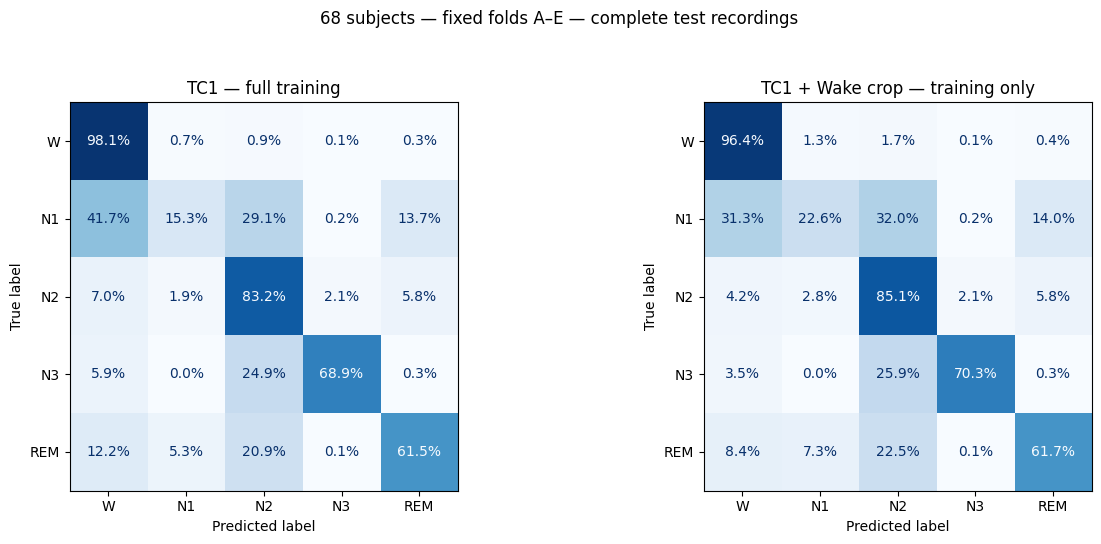

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/TC1_C1_68_crop30_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/TC1_C1_68_crop30_fixed_AE_confusion.png


In [21]:
import io
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

assert SESSAO_PRONTA, "Executa primeiro a secção 1."
NOME_TC1_C1_68 = "TC1_C1_68_crop30_fixed_AE"

resultados_tc1_68 = {
    f: _read_json(
        EXPERIMENTS_DIR / f"TC1_68_fixed_AE_fold_{f}.json"
    )
    for f in "ABCDE"
}

resultados_tc1_c1_68 = {
    f: _read_json(
        EXPERIMENTS_DIR / f"{NOME_TC1_C1_68}_fold_{f}.json"
    )
    for f in "ABCDE"
}

# Confirmar a identidade e a configuração dos cinco folds.
for nome, resultados in [
    ("TC1_68_fixed_AE", resultados_tc1_68),
    (NOME_TC1_C1_68, resultados_tc1_c1_68),
]:
    meta = resultados["A"]["metadata"]
    assert meta["experiment"] == nome
    assert meta["course_revision"] == COURSE_REVISION
    assert meta["fold_assignment"] == FOLDS_68

    for f in "ABCDE":
        assert resultados[f]["metadata"] == meta
        assert resultados[f]["fold"] == f

previsoes_tc1_68, relatorio_tc1_68 = juntar_previsoes_68(
    resultados_tc1_68
)
previsoes_tc1_c1_68, relatorio_tc1_c1_68 = juntar_previsoes_68(
    resultados_tc1_c1_68
)

# Métricas globais das previsões de teste reunidas.
comparacao_global_tc1_c1_68 = pd.DataFrame({
    "TC1": {
        m: relatorio_tc1_68[m]
        for m in METRICAS_68
    },
    "TC1 + corte": {
        m: relatorio_tc1_c1_68[m]
        for m in METRICAS_68
    },
})
comparacao_global_tc1_c1_68["Diferença"] = (
    comparacao_global_tc1_c1_68["TC1 + corte"]
    - comparacao_global_tc1_c1_68["TC1"]
)

print("COMPARAÇÃO — MÉTRICAS GLOBAIS")
display(comparacao_global_tc1_c1_68.round(3))

# Resultados por estágio.
classes_tc1_68 = classification_report(
    y_b0_68,
    previsoes_tc1_68,
    labels=ESTAGIOS_68,
    output_dict=True,
    zero_division=0,
)
classes_tc1_c1_68 = classification_report(
    y_b0_68,
    previsoes_tc1_c1_68,
    labels=ESTAGIOS_68,
    output_dict=True,
    zero_division=0,
)

print("TC1 + CORTE — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_tc1_c1_68,
    labels=ESTAGIOS_68,
    digits=3,
    zero_division=0,
))

comparacao_estagios_tc1_c1_68 = pd.DataFrame([
    {
        "Estágio": e,
        "Recall TC1": classes_tc1_68[e]["recall"],
        "Recall TC1 + corte": classes_tc1_c1_68[e]["recall"],
        "F1 TC1": classes_tc1_68[e]["f1-score"],
        "F1 TC1 + corte": classes_tc1_c1_68[e]["f1-score"],
    }
    for e in ESTAGIOS_68
]).set_index("Estágio")

comparacao_estagios_tc1_c1_68["Diferença F1"] = (
    comparacao_estagios_tc1_c1_68["F1 TC1 + corte"]
    - comparacao_estagios_tc1_c1_68["F1 TC1"]
)
display(comparacao_estagios_tc1_c1_68.round(3))

# Comparação por participante, antes de arredondar.
comparacao_participantes_tc1_c1_68 = pd.DataFrame({
    "TC1": (
        pd.DataFrame(relatorio_tc1_68["per_group"])
        .set_index("group")["cohens_kappa"]
    ),
    "TC1 + corte": (
        pd.DataFrame(relatorio_tc1_c1_68["per_group"])
        .set_index("group")["cohens_kappa"]
    ),
})
assert len(comparacao_participantes_tc1_c1_68) == 68
assert not comparacao_participantes_tc1_c1_68.isna().any().any()

comparacao_participantes_tc1_c1_68["Diferença"] = (
    comparacao_participantes_tc1_c1_68["TC1 + corte"]
    - comparacao_participantes_tc1_c1_68["TC1"]
)
dif = comparacao_participantes_tc1_c1_68["Diferença"]

print(
    "Participantes — kappa antes de arredondar:",
    int((dif > 0).sum()), "aumentaram |",
    int((dif < 0).sum()), "diminuíram |",
    int((dif == 0).sum()), "iguais",
)

# Matrizes lado a lado, com a mesma escala.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, pred, titulo in [
    (axes[0], previsoes_tc1_68, "TC1 — full training"),
    (
        axes[1],
        previsoes_tc1_c1_68,
        "TC1 + Wake crop — training only",
    ),
]:
    disp = ConfusionMatrixDisplay.from_predictions(
        y_b0_68,
        pred,
        labels=ESTAGIOS_68,
        normalize="true",
        values_format=".1%",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    disp.im_.set_clim(0, 1)
    ax.set_title(titulo)

fig.suptitle(
    "68 subjects — fixed folds A–E — complete test recordings"
)
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()
plt.close(fig)

# Consolidar as métricas dos folds.
tabela_tc1_c1_68 = pd.DataFrame([
    {
        "Fold": f,
        **{
            m: resultados_tc1_c1_68[f]["report"][m]
            for m in METRICAS_68
        },
        "Treino (min)": (
            resultados_tc1_c1_68[f]["fit_seconds"] / 60
        ),
    }
    for f in "ABCDE"
]).set_index("Fold")

exportacao_tc1_c1_68 = {
    **resultados_tc1_c1_68["A"]["metadata"],
    "cv_mean_sd_across_folds": {
        m: {
            "mean": float(tabela_tc1_c1_68[m].mean()),
            "sd": float(tabela_tc1_c1_68[m].std(ddof=1)),
        }
        for m in METRICAS_68
    },
    "sd_ddof": 1,
    "fold_metrics": (
        tabela_tc1_c1_68.reset_index().to_dict(orient="records")
    ),
    "total_fit_seconds": sum(
        r["fit_seconds"]
        for r in resultados_tc1_c1_68.values()
    ),
    "total_predict_seconds": sum(
        r["predict_seconds"]
        for r in resultados_tc1_c1_68.values()
    ),
    "report": relatorio_tc1_c1_68,
    "classification_report": classes_tc1_c1_68,
    "reference_classification_report": classes_tc1_68,
    "confusion_matrix_labels": ESTAGIOS_68,
    "confusion_matrix_counts": confusion_matrix(
        y_b0_68,
        previsoes_tc1_c1_68,
        labels=ESTAGIOS_68,
    ),
    "confusion_matrix_normalized_true": confusion_matrix(
        y_b0_68,
        previsoes_tc1_c1_68,
        labels=ESTAGIOS_68,
        normalize="true",
    ),
    "comparison_vs_TC1_global": (
        comparacao_global_tc1_c1_68.rename_axis("metric")
        .reset_index().to_dict(orient="records")
    ),
    "comparison_vs_TC1_per_stage": (
        comparacao_estagios_tc1_c1_68.reset_index()
        .to_dict(orient="records")
    ),
    "comparison_vs_TC1_subject_kappa": (
        comparacao_participantes_tc1_c1_68.reset_index()
        .to_dict(orient="records")
    ),
    "working_decision": (
        "Pending review of per-stage results; "
        "no automatic model selection."
    ),
}

destino = EXPERIMENTS_DIR / f"{NOME_TC1_C1_68}.json"
_atomic_json(destino, exportacao_tc1_c1_68)

# Guardar a matriz individual para a tabela de experiências.
fig_ind, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_tc1_c1_68,
    labels=ESTAGIOS_68,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
disp.im_.set_clim(0, 1)
ax.set_title("TC1 + Wake crop — 68 subjects — fixed folds A–E")
fig_ind.tight_layout()

buffer = io.BytesIO()
fig_ind.savefig(
    buffer, format="png", dpi=200, bbox_inches="tight"
)
plt.close(fig_ind)

imagem = (
    EXPERIMENTS_DIR / f"{NOME_TC1_C1_68}_confusion.png"
)
_atomic_bytes(imagem, buffer.getvalue())

print("Relatório guardado:", destino)
print("Imagem guardada:", imagem)

SC4611E0 — medianas por estágio


,Épocas,48–50 antes (%),48–50 depois (%),0.5–30 mantida (%)
Estágio,,,,
W,1707,1.055,0.0,99.998
N1,123,48.469,0.0,100.000
N2,276,44.608,0.0,100.000
N3,139,29.539,0.0,100.000
REM,399,49.452,0.0,100.000


Exemplo N1: época retida 1255, início 627.5 min após o início da gravação.


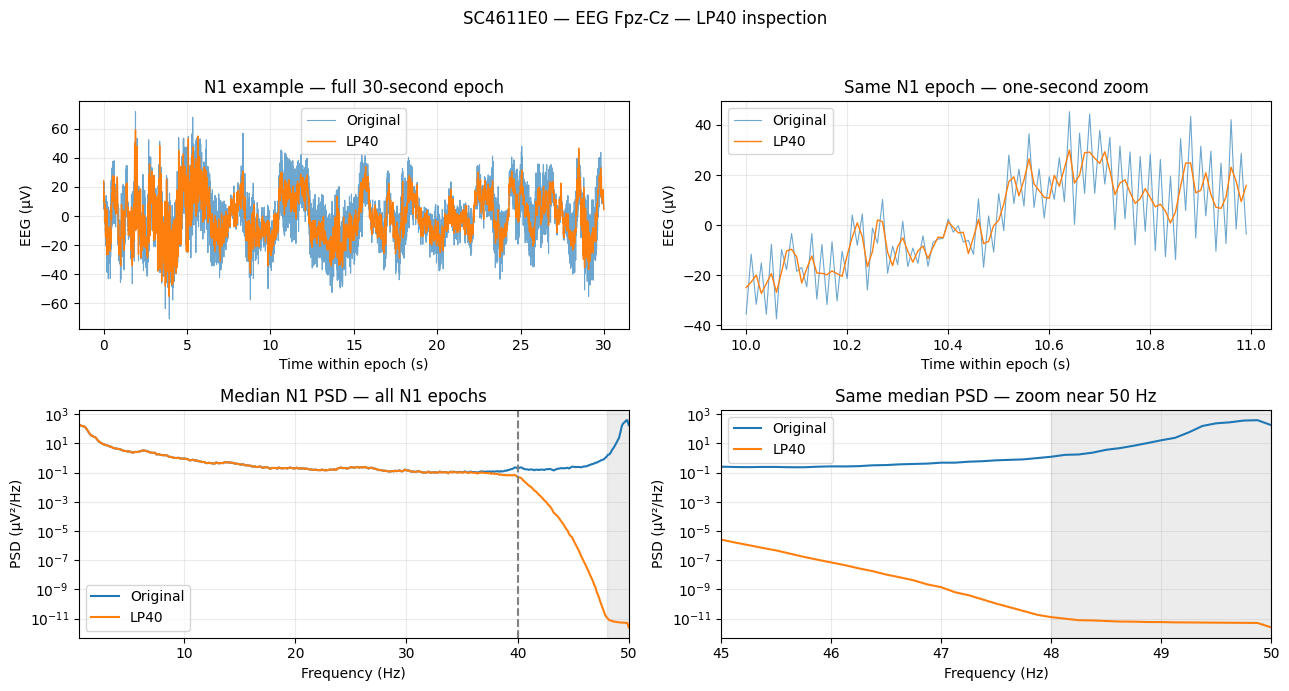

In [22]:
from scipy.signal import butter, sosfiltfilt, welch


def inspecionar_lp40_68(record):
    assert SESSAO_PRONTA, "Executa primeiro a secção 1."
    assert record[:5] in DEVELOPMENT_GROUPS_68

    caminhos = [
        Path(p) for p in ficheiros_b0_68
        if Path(p).name == f"{record}-PSG.edf"
    ]
    assert len(caminhos) == 1
    local = _local_copy(caminhos[0], "inspection_psg")

    indices = np.flatnonzero(record_ids_b0_68 == record)
    labels = y_b0_68[indices]
    tempos, duracao = tempos_epocas_68[record]
    tempos = np.asarray(tempos)

    np.testing.assert_array_equal(
        tempos, onsets_epocas_68[indices]
    )

    raw = mne.io.read_raw_edf(
        local, preload=False, verbose="ERROR"
    )
    try:
        fs = float(raw.info["sfreq"])
        assert np.isclose(fs, 100.0) and raw.first_samp == 0
        assert np.isclose(raw.n_times / fs, duracao)

        n = int(30 * fs)
        inicios = np.rint(tempos * fs).astype(int)

        assert len(inicios) == len(labels) and len(labels) > 0
        assert np.all(inicios >= 0)
        assert np.all(inicios + n <= raw.n_times)

        sinal = raw.get_data(picks="EEG Fpz-Cz")[0]
    finally:
        raw.close()

    original = np.stack([sinal[i:i + n] for i in inicios])
    del sinal

    assert original.shape == (len(labels), n)
    assert np.isfinite(original).all()

    # Mesmo LP40 da experiência: ordem 4 por passagem, por época.
    sos = butter(
        4, 40.0, btype="lowpass", fs=fs, output="sos"
    )
    filtrado = sosfiltfilt(
        sos, original, axis=-1, padtype="odd"
    )

    # Welch de 8 segundos apenas para inspeção.
    # Não altera o código das features.
    psd_cfg = dict(
        fs=fs,
        window="hann",
        nperseg=int(8 * fs),
        noverlap=int(4 * fs),
        detrend="constant",
        scaling="density",
        axis=-1,
    )
    f, p0 = welch(original, **psd_cfg)
    _, p1 = welch(filtrado, **psd_cfg)

    p0 *= 1e12  # V²/Hz -> µV²/Hz
    p1 *= 1e12

    def potencia(psd, inferior, superior):
        banda = (f >= inferior) & (f <= superior)
        return np.trapezoid(
            psd[:, banda], f[banda], axis=1
        )

    total0 = potencia(p0, 0.5, 50)
    total1 = potencia(p1, 0.5, 50)
    baixa0 = potencia(p0, 0.5, 30)
    baixa1 = potencia(p1, 0.5, 30)

    assert np.all(total0 > 0) and np.all(total1 > 0)
    assert np.all(baixa0 > 0)

    alta0 = 100 * potencia(p0, 48, 50) / total0
    alta1 = 100 * potencia(p1, 48, 50) / total1
    retida = 100 * baixa1 / baixa0

    tabela = pd.DataFrame([
        {
            "Estágio": e,
            "Épocas": int(np.sum(labels == e)),
            "48–50 antes (%)": float(
                np.median(alta0[labels == e])
            ),
            "48–50 depois (%)": float(
                np.median(alta1[labels == e])
            ),
            "0.5–30 mantida (%)": float(
                np.median(retida[labels == e])
            ),
        }
        for e in ESTAGIOS_68 if np.any(labels == e)
    ]).set_index("Estágio")

    print(record, "— medianas por estágio")
    display(tabela.round(3))

    # Escolher uma época N1 próxima da mediana
    # da fração de potência em 48–50 Hz.
    candidatos = np.flatnonzero(labels == "N1")
    assert len(candidatos) > 0

    i = candidatos[np.argmin(np.abs(
        alta0[candidatos] - np.median(alta0[candidatos])
    ))]

    print(
        f"Exemplo N1: época retida {i}, "
        f"início {tempos[i] / 60:.1f} min "
        "após o início da gravação."
    )

    t = np.arange(n) / fs
    zoom = (t >= 10) & (t < 11)

    # Mediana dos PSDs de todas as épocas N1.
    med0 = np.median(p0[candidatos], axis=0)
    med1 = np.median(p1[candidatos], axis=0)

    fig, axes = plt.subplots(2, 2, figsize=(13, 7))

    for ax, mascara, titulo in [
        (
            axes[0, 0],
            np.ones(n, dtype=bool),
            "N1 example — full 30-second epoch",
        ),
        (
            axes[0, 1],
            zoom,
            "Same N1 epoch — one-second zoom",
        ),
    ]:
        ax.plot(
            t[mascara], original[i, mascara] * 1e6,
            label="Original", alpha=0.65, linewidth=0.8,
        )
        ax.plot(
            t[mascara], filtrado[i, mascara] * 1e6,
            label="LP40", linewidth=1,
        )
        ax.set(
            title=titulo,
            xlabel="Time within epoch (s)",
            ylabel="EEG (µV)",
        )

    for ax, limites, titulo in [
        (
            axes[1, 0],
            (0.5, 50),
            "Median N1 PSD — all N1 epochs",
        ),
        (
            axes[1, 1],
            (45, 50),
            "Same median PSD — zoom near 50 Hz",
        ),
    ]:
        visivel = f >= 0.5
        ax.semilogy(
            f[visivel],
            np.maximum(med0[visivel], 1e-20),
            label="Original",
        )
        ax.semilogy(
            f[visivel],
            np.maximum(med1[visivel], 1e-20),
            label="LP40",
        )
        ax.axvspan(48, 50, color="grey", alpha=0.15)
        ax.set(
            title=titulo,
            xlabel="Frequency (Hz)",
            ylabel="PSD (µV²/Hz)",
            xlim=limites,
        )

    axes[1, 0].axvline(
        40, color="grey", linestyle="--"
    )

    for ax in axes.flat:
        ax.legend()
        ax.grid(True, alpha=0.25)

    fig.suptitle(
        f"{record} — EEG Fpz-Cz — LP40 inspection"
    )
    fig.tight_layout(rect=(0, 0, 1, .95))
    plt.show()
    plt.close(fig)

    return tabela


tabela_qc_lp40_sc461_68 = inspecionar_lp40_68("SC4611E0")

SC4531E0 — medianas por estágio


,Épocas,48–50 antes (%),48–50 depois (%),0.5–30 mantida (%)
Estágio,,,,
W,1748,1.692,0.0,99.995
N1,124,2.565,0.0,99.999
N2,465,1.054,0.0,100.000
N3,85,1.557,0.0,100.000
REM,180,1.591,0.0,100.000


Exemplo N1: época retida 882, início 441.0 min após o início da gravação.


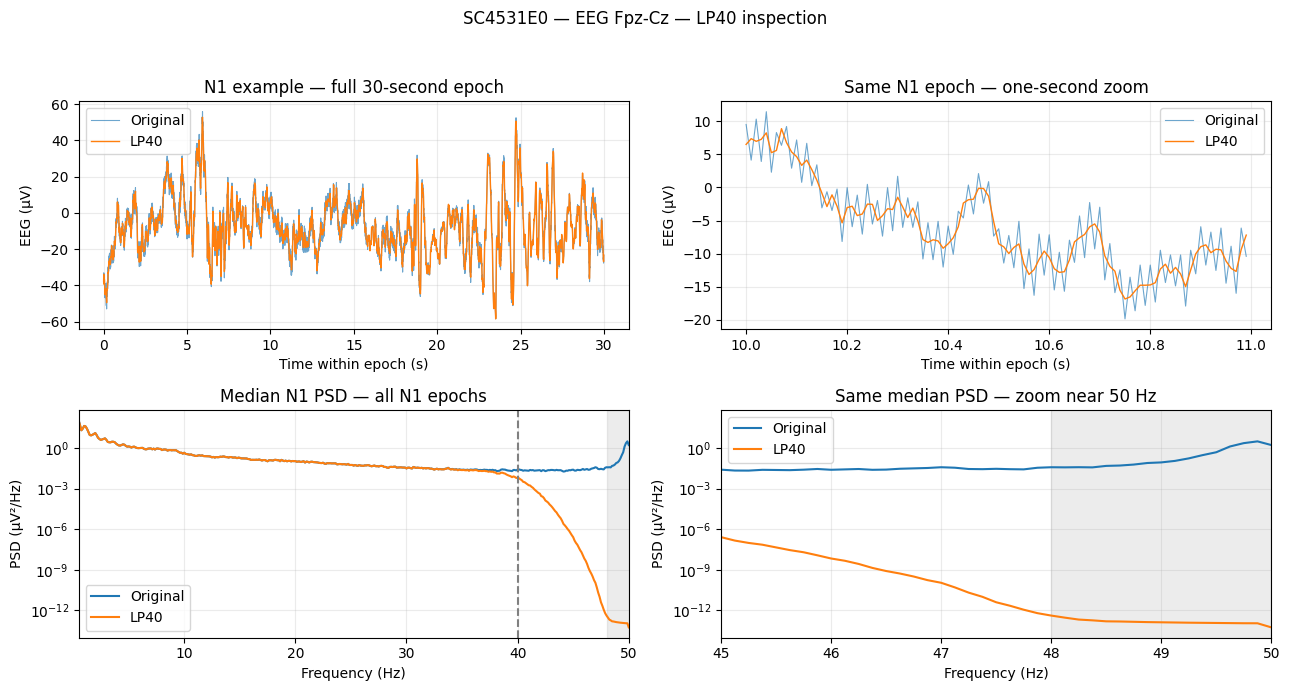

SC4141E0 — medianas por estágio


,Épocas,48–50 antes (%),48–50 depois (%),0.5–30 mantida (%)
Estágio,,,,
W,1939,0.873,0.0,99.997
N1,29,0.504,0.0,99.999
N2,404,0.111,0.0,100.000
N3,151,0.044,0.0,100.000
REM,233,0.266,0.0,99.999


Exemplo N1: época retida 1250, início 625.0 min após o início da gravação.


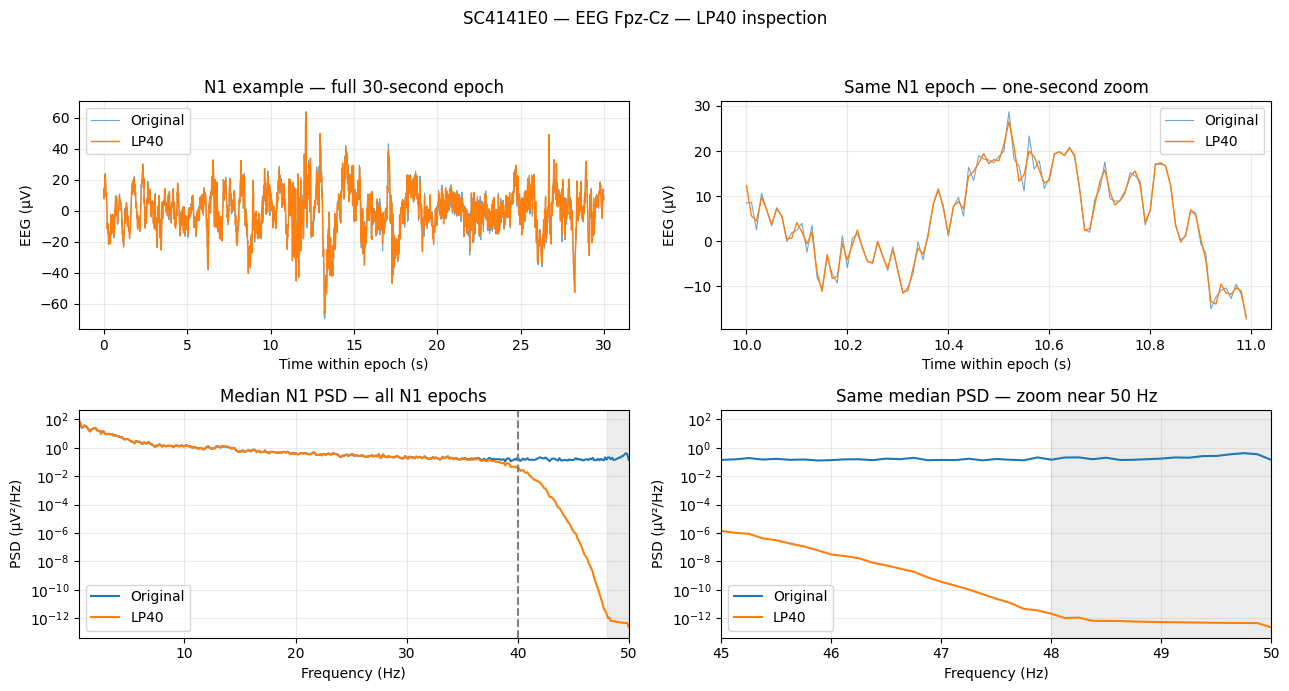

,Gravação,Estágio,Épocas,48–50 antes (%),48–50 depois (%),0.5–30 mantida (%)
0,SC4611E0,W,1707,1.055,0.0,99.998
1,SC4611E0,N1,123,48.469,0.0,100.000
2,SC4611E0,N2,276,44.608,0.0,100.000
3,SC4611E0,N3,139,29.539,0.0,100.000
4,SC4611E0,REM,399,49.452,0.0,100.000
5,SC4531E0,W,1748,1.692,0.0,99.995
6,SC4531E0,N1,124,2.565,0.0,99.999
7,SC4531E0,N2,465,1.054,0.0,100.000
8,SC4531E0,N3,85,1.557,0.0,100.000
9,SC4531E0,REM,180,1.591,0.0,100.000


In [23]:
tabela_qc_lp40_sc453_68 = inspecionar_lp40_68("SC4531E0")
tabela_qc_lp40_sc414_68 = inspecionar_lp40_68("SC4141E0")

comparacao_qc_lp40_68 = pd.concat(
    {
        "SC4611E0": tabela_qc_lp40_sc461_68,
        "SC4531E0": tabela_qc_lp40_sc453_68,
        "SC4141E0": tabela_qc_lp40_sc414_68,
    },
    names=["Gravação", "Estágio"],
).reset_index()

display(comparacao_qc_lp40_68.round(3))

In [24]:
from adapter import cached
from scipy.signal import welch

QC_HIGHFREQ_VERSION_68 = 1
QC_HIGHFREQ_SETTINGS_68 = {
    "fs_hz": 100.0,
    "epoch_seconds": 30.0,
    "window": "hann",
    "nperseg": 800,
    "noverlap": 400,
    "detrend": "constant",
    "scaling": "density",
    "total_band": [0.5, 50.0],
    "high_band": [48.0, 50.0],
}

SELECTIVE_LP40_CONFIG_68 = {
    "version": 1,
    "ratio_version": QC_HIGHFREQ_VERSION_68,
    "ratio_settings": dict(QC_HIGHFREQ_SETTINGS_68),
    "threshold_percent": 10.0,
    "threshold_operator": ">=",
    "filter": {
        "cutoff_hz": 40.0,
        "order_per_pass": 4,
        "application": "sosfiltfilt per epoch",
        "padtype": "odd",
    },
    "selection": "signal only; same rule for training and test epochs",
}


def carregar_racios_alta_68(record):
    assert SESSAO_PRONTA, "Executa primeiro a secção 1."
    assert record[:5] in DEVELOPMENT_GROUPS_68

    caminhos = [
        Path(p) for p in ficheiros_b0_68
        if Path(p).name == f"{record}-PSG.edf"
    ]
    assert len(caminhos) == 1
    psg = caminhos[0]

    indices = np.flatnonzero(record_ids_b0_68 == record)
    tempos, duracao = tempos_epocas_68[record]
    tempos = np.asarray(tempos)
    np.testing.assert_array_equal(
        tempos, onsets_epocas_68[indices]
    )

    chave = {
        "version": QC_HIGHFREQ_VERSION_68,
        "course_revision": COURSE_REVISION,
        "record": record,
        "file": _file_signature(psg),
        "onsets_sha256": assinatura_arrays_68(tempos),
        "settings": QC_HIGHFREQ_SETTINGS_68,
        "runtime": {
            k: runtime_versions[k]
            for k in ["numpy", "scipy", "mne"]
        },
    }

    def calcular():
        local = _local_copy(psg, "inspection_psg")
        raw = mne.io.read_raw_edf(
            local, preload=False, verbose="ERROR"
        )
        try:
            fs = float(raw.info["sfreq"])
            assert np.isclose(
                fs, QC_HIGHFREQ_SETTINGS_68["fs_hz"]
            )
            assert raw.first_samp == 0
            assert np.isclose(raw.n_times / fs, duracao)

            n = int(
                QC_HIGHFREQ_SETTINGS_68["epoch_seconds"] * fs
            )
            inicios = np.rint(tempos * fs).astype(int)
            assert np.all(inicios >= 0)
            assert np.all(inicios + n <= raw.n_times)

            sinal = raw.get_data(picks="EEG Fpz-Cz")[0]
        finally:
            raw.close()

        eeg = np.stack([sinal[i:i + n] for i in inicios])
        del sinal
        assert np.isfinite(eeg).all()

        cfg = QC_HIGHFREQ_SETTINGS_68
        f, p = welch(
            eeg,
            fs=fs,
            window=cfg["window"],
            nperseg=cfg["nperseg"],
            noverlap=cfg["noverlap"],
            detrend=cfg["detrend"],
            scaling=cfg["scaling"],
            axis=-1,
        )

        def potencia(banda):
            mascara = (f >= banda[0]) & (f <= banda[1])
            return np.trapezoid(
                p[:, mascara], f[mascara], axis=1
            )

        total = potencia(cfg["total_band"])
        assert np.all(total > 0), (
            f"Época sem potência: verificar {record}."
        )
        percentagem = (
            100 * potencia(cfg["high_band"]) / total
        )

        return {
            "record": record,
            "onsets_seconds": tempos.copy(),
            "percent_48_50": percentagem,
        }

    dados = cached(
        "viggy_highfreq_ratio", chave, calcular, CACHE_VIGGY
    )

    assert dados["record"] == record
    np.testing.assert_array_equal(
        dados["onsets_seconds"], tempos
    )

    percentagem = np.asarray(
        dados["percent_48_50"], dtype=float
    )
    assert percentagem.shape == (len(indices),)
    assert np.isfinite(percentagem).all()
    assert np.all(
        (percentagem >= 0) & (percentagem <= 100 + 1e-9)
    )
    return percentagem


QC_RACIOS_ALTA_68 = globals().get("QC_RACIOS_ALTA_68", {})
_linhas_selecao_68 = []
limiar = SELECTIVE_LP40_CONFIG_68["threshold_percent"]

for record in ["SC4611E0", "SC4531E0", "SC4141E0"]:
    percentagem = carregar_racios_alta_68(record)
    QC_RACIOS_ALTA_68[record] = percentagem

    # A seleção não depende das labels.
    selecionadas = percentagem >= limiar

    # As labels são usadas apenas para resumir o diagnóstico.
    labels = y_b0_68[record_ids_b0_68 == record]

    print(
        f"{record}: {selecionadas.sum()}/{len(labels)} épocas "
        f"selecionadas ({100 * selecionadas.mean():.1f}%)."
    )

    for e in ESTAGIOS_68:
        mascara = labels == e
        if mascara.any():
            _linhas_selecao_68.append({
                "Gravação": record,
                "Estágio": e,
                "Épocas": int(mascara.sum()),
                "Selecionadas": int(
                    selecionadas[mascara].sum()
                ),
                "Selecionadas (%)": float(
                    100 * selecionadas[mascara].mean()
                ),
                "Mediana 48–50 (%)": float(
                    np.median(percentagem[mascara])
                ),
            })

tabela_selecao_lp40_68 = pd.DataFrame(
    _linhas_selecao_68
).set_index(["Gravação", "Estágio"])

display(tabela_selecao_lp40_68.round(3))
print(
    "Diagnóstico concluído. "
    "Ainda sem filtragem seletiva nem novos treinos."
)

[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_0d30e6d26688.pkl
SC4611E0: 1037/2644 épocas selecionadas (39.2%).
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_4beb7cc607a8.pkl
SC4531E0: 56/2602 épocas selecionadas (2.2%).
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_6c49c1e01b2a.pkl
SC4141E0: 36/2756 épocas selecionadas (1.3%).


Épocas  Selecionadas  Selecionadas (%)  Mediana 48–50 (%)
Gravação Estágio                                                           
SC4611E0 W          1707           103             6.034              1.055
         N1          123           121            98.374             48.469
         N2          276           276           100.000             44.608
         N3          139           139           100.000             29.539
         REM         399           398            99.749             49.452
SC4531E0 W          1748            28             1.602              1.692
         N1          124             6             4.839              2.565
         N2          465             3             0.645              1.054
         N3           85             0             0.000              1.557
         REM         180            19            10.556              1.591
SC4141E0 W          1939            36             1.857              0.873
         N1           29             0             0.000              0.504
         N2          404             0             0.000              0.111
         N3          151             0             0.000              0.044
         REM         233             0             0.000              0.266

Diagnóstico concluído. Ainda sem filtragem seletiva nem novos treinos.


In [25]:
assert SESSAO_PRONTA, "Executa primeiro a secção 1."
assert SELECTIVE_LP40_CONFIG_68["threshold_percent"] == 10.0

NOME_SEL40_68 = "SEL40_68_fixed_AE"

FRACAO_ALTA_68 = np.full(len(y_b0_68), np.nan)
_cobertura_sel40_68 = np.zeros(
    len(y_b0_68), dtype=np.uint8
)
_linhas_sel40_gravacoes = []
_inicio_sel40_qc = time.perf_counter()

assert len(b0_gravacoes_68) == 133
assert len({
    str(d["record"]) for d in b0_gravacoes_68
}) == 133

for numero, dados in enumerate(b0_gravacoes_68, 1):
    record = str(dados["record"])
    indices = np.flatnonzero(
        record_ids_b0_68 == record
    )
    percentagem = carregar_racios_alta_68(record)

    assert len(indices) == len(dados["y"]) == len(percentagem)
    np.testing.assert_array_equal(
        y_b0_68[indices], dados["y"]
    )
    assert np.all(_cobertura_sel40_68[indices] == 0)

    FRACAO_ALTA_68[indices] = percentagem
    _cobertura_sel40_68[indices] += 1
    QC_RACIOS_ALTA_68[record] = percentagem

    selecionadas = percentagem >= 10.0

    _linhas_sel40_gravacoes.append({
        "Gravação": record,
        "Participante": record[:5],
        "Épocas": len(indices),
        "Com LP40": int(selecionadas.sum()),
        "Com LP40 (%)": float(
            100 * selecionadas.mean()
        ),
        "Mediana 48–50 (%)": float(
            np.median(percentagem)
        ),
        "P95 48–50 (%)": float(
            np.percentile(percentagem, 95)
        ),
    })

    if numero % 10 == 0 or numero == len(b0_gravacoes_68):
        print(
            f"Rácios preparados: {numero}/133 | "
            f"tempo: "
            f"{(time.perf_counter() - _inicio_sel40_qc) / 60:.1f} min",
            flush=True,
        )

# Confirmar que cada época recebeu exatamente um rácio.
assert np.all(_cobertura_sel40_68 == 1)
assert np.isfinite(FRACAO_ALTA_68).all()
assert np.all(
    (FRACAO_ALTA_68 >= 0)
    & (FRACAO_ALTA_68 <= 100 + 1e-9)
)

SEL40_MASK_68 = FRACAO_ALTA_68 >= 10.0

resumo_sel40_gravacoes_68 = pd.DataFrame(
    _linhas_sel40_gravacoes
).set_index("Gravação")

resumo_sel40_estagios_68 = pd.DataFrame([
    {
        "Estágio": e,
        "Épocas": int(np.sum(y_b0_68 == e)),
        "Com LP40": int(
            SEL40_MASK_68[y_b0_68 == e].sum()
        ),
        "Com LP40 (%)": float(
            100 * SEL40_MASK_68[y_b0_68 == e].mean()
        ),
    }
    for e in ESTAGIOS_68
    if np.any(y_b0_68 == e)
]).set_index("Estágio")

assert len(resumo_sel40_gravacoes_68) == 133
assert (
    resumo_sel40_gravacoes_68["Participante"].nunique()
    == 68
)
assert (
    resumo_sel40_gravacoes_68["Épocas"].sum()
    == len(y_b0_68)
)
assert (
    resumo_sel40_estagios_68["Épocas"].sum()
    == len(y_b0_68)
)

print(f"Épocas totais: {len(y_b0_68)}")
print(
    f"Receberiam LP40: {SEL40_MASK_68.sum()} "
    f"({100 * SEL40_MASK_68.mean():.2f}%)"
)
print(
    f"Ficariam com o sinal original: "
    f"{(~SEL40_MASK_68).sum()}"
)

print("\nDISTRIBUIÇÃO POR ESTÁGIO")
display(resumo_sel40_estagios_68.round(3))

print("\nDEZ GRAVAÇÕES COM MAIOR PERCENTAGEM SELECIONADA")
display(
    resumo_sel40_gravacoes_68
    .sort_values(
        ["Com LP40 (%)", "Gravação"],
        ascending=[False, True],
    )
    .head(10)
    .round(3)
)

# Guardar um resumo pequeno; os rácios já estão em cache.
destino_sel40_qc_68 = (
    EXPERIMENTS_DIR / "SEL40_68_quality_summary_v1.json"
)

_atomic_json(destino_sel40_qc_68, {
    "experiment": NOME_SEL40_68,
    "stage": "signal-only quality measurement; no classifier fitted",
    "course_revision": COURSE_REVISION,
    "runtime": runtime_versions,
    "config": SELECTIVE_LP40_CONFIG_68,
    "n_subjects": 68,
    "n_recordings": 133,
    "n_epochs": len(y_b0_68),
    "n_selected": int(SEL40_MASK_68.sum()),
    "percent_selected": float(
        100 * SEL40_MASK_68.mean()
    ),
    "data_sha256": assinatura_arrays_68(
        FRACAO_ALTA_68,
        groups_b0_68,
        record_ids_b0_68,
    ),
    "per_record": (
        resumo_sel40_gravacoes_68.reset_index()
        .to_dict(orient="records")
    ),
    "per_stage": (
        resumo_sel40_estagios_68.reset_index()
        .to_dict(orient="records")
    ),
})

print("Resumo guardado:", destino_sel40_qc_68)
print("Máscara preparada e alinhada. Ainda sem novos treinos.")

[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_52fffe3a96a6.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_d7c843b8dacc.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_42e712da0d22.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_58fd4a6ef30c.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_f17d8b4d8cbc.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_377101c9a0a1.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_161fbed34999.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_28288c1b0826.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_802a3fc99410.pkl
[cache] viggy_highfreq_ratio: computed and saved _cache_viggy_highfreq_ratio_48a9a028a8de.pkl
Rácios preparados: 10/133 | tempo: 0.5 min
[cache] viggy_hig

,Épocas,Com LP40,Com LP40 (%)
Estágio,,,
W,248341,14640,5.895
N1,17877,2213,12.379
N2,60494,4746,7.845
N3,11610,410,3.531
REM,22299,3437,15.413



DEZ GRAVAÇÕES COM MAIOR PERCENTAGEM SELECIONADA


,Participante,Épocas,Com LP40,Com LP40 (%),Mediana 48–50 (%),P95 48–50 (%)
Gravação,,,,,,
SC4232E0,SC423,2635,2135,81.025,47.523,91.095
SC4202E0,SC420,2670,1929,72.247,26.061,83.196
SC4272F0,SC427,2870,1706,59.443,15.511,73.522
SC4762E0,SC476,2662,1231,46.243,4.916,99.096
SC4111E0,SC411,2641,1155,43.733,2.499,97.632
SC4512E0,SC451,2750,1194,43.418,5.070,72.296
SC4382F0,SC438,2770,1160,41.877,6.002,96.753
SC4591G0,SC459,2819,1129,40.050,2.382,97.682
SC4611E0,SC461,2644,1037,39.221,3.944,62.600


Resumo guardado: /content/drive/MyDrive/CM2013_data/experiments/SEL40_68_quality_summary_v1.json
Máscara preparada e alinhada. Ainda sem novos treinos.


In [29]:
import copy
from adapter import cached

assert SESSAO_PRONTA, "Executa primeiro a secção 1."
assert SELECTIVE_LP40_CONFIG_68["threshold_percent"] == 10.0
assert SEL40_MASK_68.shape == y_b0_68.shape
np.testing.assert_array_equal(
    SEL40_MASK_68, FRACAO_ALTA_68 >= 10.0
)

_ref_lp40_sel = _read_json(
    EXPERIMENTS_DIR / "LP40_68_fixed_AE_fold_A.json"
)
_meta_lp40_sel = _ref_lp40_sel.get(
    "metadata", _ref_lp40_sel
)

# Confirmar a configuração da experiência LP40 original.
assert _meta_lp40_sel["course_revision"] == COURSE_REVISION

for campo in ["recordings", "fold_assignment", "feature_names"]:
    assert (
        _meta_lp40_sel[campo]
        == config_f2_guardada_68[campo]
    )

assert _meta_lp40_sel["classifier_params"] == (
    modelo_base_f2_68.named_steps["clf"].get_params()
)
assert _meta_lp40_sel["scaler_params"] == (
    modelo_base_f2_68.named_steps["scale"].get_params()
)

_pp_lp40_sel = _meta_lp40_sel["details"]["preprocessing"]

assert _pp_lp40_sel["version"] == 1
assert _pp_lp40_sel["channels"] == ["eeg"]
assert _pp_lp40_sel["application"] == (
    "sosfiltfilt, per epoch, axis=-1"
)
assert _pp_lp40_sel["settings"] == {
    "cutoff_hz": 40.0,
    "order_per_pass": 4,
    "padtype": "odd",
}
assert _meta_lp40_sel["feature_version"] == 1
assert (
    _meta_lp40_sel["details"]["base_feature_version"]
    == B0_FEATURE_VERSION
)
assert (
    _meta_lp40_sel["details"]["relative_feature_version"]
    == F2_FEATURE_VERSION
)


def ler_cache_lp40_existente_sel68(psg):
    psg = Path(psg)
    record = psg.name.removesuffix("-PSG.edf")

    marcacoes = _drive_io(
        lambda: sorted(
            psg.parent.glob(f"{record[:6]}*-Hypnogram.edf")
        ),
        f"localizar marcações de {record}",
    )
    assert len(marcacoes) == 1

    assinaturas = [
        _file_signature(p)
        for p in [psg, marcacoes[0]]
    ]

    # Reproduzir a chave original, incluindo as versões
    # utilizadas quando estas features foram calculadas.
    chave = {
        "course_revision": COURSE_REVISION,
        "files": [
            (s["name"], s["bytes"], s["mtime_ns"])
            for s in assinaturas
        ],
        "load": {
            "fs_target": 100.0,
            "epoch_s": 30.0,
        },
        "runtime": {
            k: _meta_lp40_sel["runtime"][k]
            for k in ["python", "numpy", "scipy", "mne"]
        },
        "preprocessing": {
            "version": _pp_lp40_sel["version"],
            "settings": dict(_pp_lp40_sel["settings"]),
            "channels": ["eeg"],
            "application": "sosfiltfilt, per epoch, axis=-1",
        },
        "features": {
            "version": _meta_lp40_sel["feature_version"],
            "base_version": B0_FEATURE_VERSION,
            "relative_version": F2_FEATURE_VERSION,
            "spectral_method": "welch",
            "names": list(nomes_features_f2_68),
        },
    }

    def nao_recalcular():
        raise RuntimeError(
            f"Cache LP40 esperado não encontrado para {record}. "
            "Pára aqui e envia o erro antes de treinar."
        )

    return _drive_io(
        lambda: cached(
            "viggy_lp40_features",
            chave,
            nao_recalcular,
            CACHE_VIGGY,
        ),
        f"ler cache LP40 de {record}",
    )


# Começar com todas as features originais do F2.
X_sel40_68 = X_f2_68.copy()

_cobertura_sel40_features = np.zeros(
    len(y_b0_68), dtype=np.uint8
)
_aux_sel40 = [
    nomes_features_f2_68.index(n)
    for n in ["eog_movement", "emg_rms"]
]
_caches_lp40_lidos = 0

for numero, psg in enumerate(ficheiros_b0_68, 1):
    record = Path(psg).name.removesuffix("-PSG.edf")
    indices = np.flatnonzero(
        record_ids_b0_68 == record
    )

    assert len(indices) > 0
    assert np.all(_cobertura_sel40_features[indices] == 0)

    mascara = SEL40_MASK_68[indices]

    if mascara.any():
        dados = ler_cache_lp40_existente_sel68(psg)

        assert dados["record"] == record
        assert (
            list(dados["feature_names"])
            == list(nomes_features_f2_68)
        )

        xx = np.asarray(dados["X"], dtype=float)
        assert xx.shape == (len(indices), 16)
        assert np.isfinite(xx).all()

        np.testing.assert_array_equal(
            dados["y"], y_b0_68[indices]
        )
        np.testing.assert_array_equal(
            dados["groups"], groups_b0_68[indices]
        )
        np.testing.assert_allclose(
            xx[:, _aux_sel40],
            X_f2_68[indices][:, _aux_sel40],
            rtol=1e-12,
            atol=0,
        )

        # Confirmar as cinco potências relativas guardadas.
        potencias = xx[:, indices_bandas_f2_68]
        assert np.all(potencias >= 0)

        total = potencias.sum(axis=1, keepdims=True)
        relativas = np.divide(
            potencias,
            total,
            out=np.zeros_like(potencias),
            where=total > 0,
        )
        np.testing.assert_allclose(
            xx[:, 11:], relativas,
            rtol=1e-12, atol=0,
        )

        # Substituir apenas as linhas selecionadas.
        X_sel40_68[indices[mascara]] = xx[mascara]
        _caches_lp40_lidos += 1

    _cobertura_sel40_features[indices] += 1

    if numero % 25 == 0 or numero == len(ficheiros_b0_68):
        print(
            f"Features preparadas: "
            f"{numero}/{len(ficheiros_b0_68)}",
            flush=True,
        )

assert np.all(_cobertura_sel40_features == 1)
assert X_sel40_68.shape == X_f2_68.shape
assert np.isfinite(X_sel40_68).all()

np.testing.assert_array_equal(
    X_sel40_68[~SEL40_MASK_68],
    X_f2_68[~SEL40_MASK_68],
)
np.testing.assert_allclose(
    X_sel40_68[:, _aux_sel40],
    X_f2_68[:, _aux_sel40],
    rtol=1e-12,
    atol=0,
)

SEL40_RECIPE_68 = {
    "version": 1,
    "base_features": (
        "F2 v1, 11 original plus five relative EEG powers"
    ),
    "preprocessing": copy.deepcopy(SELECTIVE_LP40_CONFIG_68),
    "filtered_feature_source": "LP40_68_fixed_AE",
    "filtered_feature_version": _meta_lp40_sel["feature_version"],
    "filtered_feature_runtime": copy.deepcopy(
        _meta_lp40_sel["runtime"]
    ),
    "selection_sha256": assinatura_arrays_68(
        SEL40_MASK_68, record_ids_b0_68
    ),
    "selected_epochs": int(SEL40_MASK_68.sum()),
    "training_selection": (
        "all original retained epochs; no Wake crop"
    ),
}

print("SEL40:", X_sel40_68.shape)
print(
    "Épocas com features LP40:",
    int(SEL40_MASK_68.sum()),
)
print(
    "Épocas com features F2 originais:",
    int((~SEL40_MASK_68).sum()),
)
print("Caches LP40 utilizados:", _caches_lp40_lidos)
print(
    "Labels, ordem e features EOG/EMG confirmadas. "
    "Ainda sem treino."
)

[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_7e15ac284305.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_5316b789b31a.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_7f22feb5b2d9.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_683c0c993183.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_167530e36088.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_dd86b22539cc.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_7ec6634cb7b3.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_ebddef574b4c.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_5bbcefadbd1d.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_3ce20b013faf.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_0aa2bf7a10a0.pkl
[cache] viggy_lp40_features: reused _cache_viggy_lp40_features_07859be07fc3.pkl
Features preparadas: 25/133
[cache] vigg

SEL40_68_fixed_AE — fold A: a treinar...
Fold A: kappa 0.752 | treino 5.15 min
SEL40_68_fixed_AE — fold B: a treinar...
Fold B: kappa 0.718 | treino 5.15 min
SEL40_68_fixed_AE — fold C: a treinar...
Fold C: kappa 0.737 | treino 5.31 min
SEL40_68_fixed_AE — fold D: a treinar...
Fold D: kappa 0.720 | treino 5.37 min
SEL40_68_fixed_AE — fold E: a treinar...
Fold E: kappa 0.752 | treino 5.30 min
MÉTRICAS POR FOLD


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.752,0.677,0.885,0.673,5.151
B,0.718,0.649,0.862,0.638,5.146
C,0.737,0.652,0.877,0.623,5.306
D,0.720,0.639,0.876,0.602,5.371
E,0.752,0.678,0.880,0.660,5.303


Kappa médio ± SD dos folds: 0.736 ± 0.017
Treino total: 26.3 min

MÉTRICAS GLOBAIS


,F2,SEL40_68_fixed_AE,Diferença
cohens_kappa,0.735,0.736,0.001
macro_f1,0.659,0.660,0.001
accuracy,0.876,0.876,0.000
balanced_accuracy,0.638,0.640,0.002



RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.939     0.979     0.958    248341
          N1      0.342     0.135     0.193     17877
          N2      0.766     0.814     0.790     60494
          N3      0.833     0.686     0.752     11610
         REM      0.628     0.589     0.608     22299

    accuracy                          0.876    360621
   macro avg      0.702     0.640     0.660    360621
weighted avg      0.858     0.876     0.864    360621


Participantes — kappa antes de arredondar: 37 aumentaram | 31 diminuíram | 0 iguais


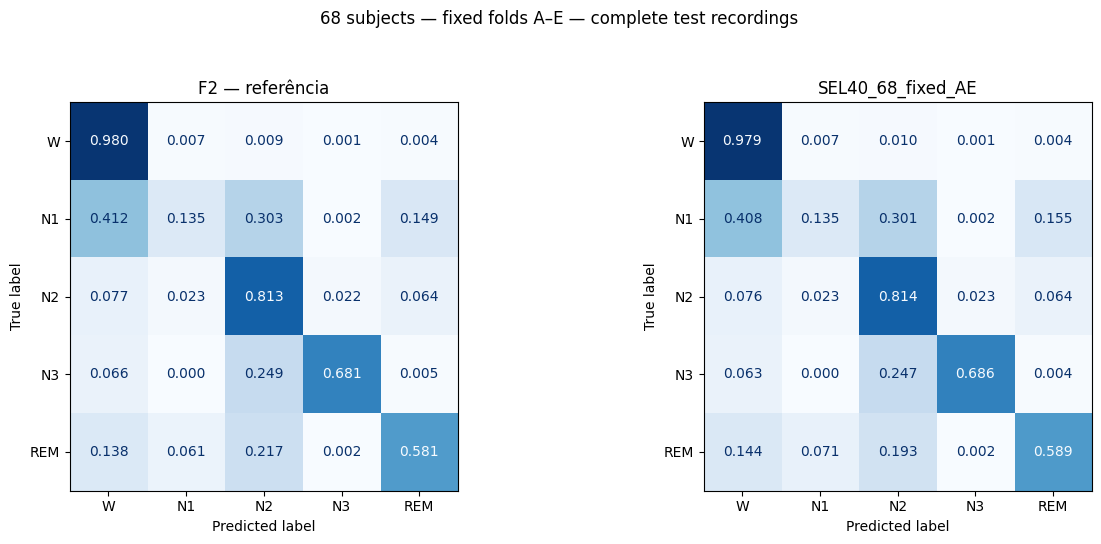

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/SEL40_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/SEL40_68_fixed_AE_confusion.png

KAPPA NOS MESMOS FOLDS


,F2,LP40,SEL40,SEL40 - F2,SEL40 - LP40
Fold,,,,,
A,0.753,0.756,0.752,-0.001,-0.004
B,0.718,0.719,0.718,0.000,-0.001
C,0.739,0.736,0.737,-0.002,0.001
D,0.717,0.716,0.720,0.003,0.004
E,0.748,0.751,0.752,0.004,0.001



MÉTRICAS GLOBAIS — TRÊS ESTRATÉGIAS


,F2,LP40,SEL40
cohens_kappa,0.735,0.736,0.736
macro_f1,0.659,0.661,0.660
accuracy,0.876,0.876,0.876
balanced_accuracy,0.638,0.641,0.640


In [30]:
RUN_SEL40_68 = False  # Voltar a False depois de concluir.
NOME_SEL40_68 = "SEL40_68_fixed_AE"

if RUN_SEL40_68:
    SEL40_READY_68 = False

    assert SESSAO_PRONTA, "Executa primeiro a secção 1."
    assert np.all(_cobertura_sel40_features == 1), (
        "Preparação SEL40 incompleta."
    )
    assert X_sel40_68.shape == X_f2_68.shape
    assert np.isfinite(X_sel40_68).all()

    np.testing.assert_array_equal(
        SEL40_MASK_68, FRACAO_ALTA_68 >= 10.0
    )
    assert SELECTIVE_LP40_CONFIG_68["threshold_percent"] == 10.0
    assert (
        SEL40_RECIPE_68["preprocessing"]
        == SELECTIVE_LP40_CONFIG_68
    )
    assert (
        SEL40_RECIPE_68["selected_epochs"]
        == int(SEL40_MASK_68.sum())
    )
    assert (
        SEL40_RECIPE_68["selection_sha256"]
        == assinatura_arrays_68(
            SEL40_MASK_68, record_ids_b0_68
        )
    )

    # Recuperar a referência LP40 sem voltar a treiná-la.
    resultados_lp40_68 = {
        f: _read_json(
            EXPERIMENTS_DIR
            / f"LP40_68_fixed_AE_fold_{f}.json"
        )
        for f in "ABCDE"
    }

    for f, r in resultados_lp40_68.items():
        meta = r.get("metadata", r)

        assert r["fold"] == f
        assert meta["course_revision"] == COURSE_REVISION
        assert meta["fold_assignment"] == FOLDS_68
        assert meta["feature_names"] == list(
            nomes_features_f2_68
        )
        assert meta["classifier_params"] == (
            modelo_base_f2_68.named_steps["clf"].get_params()
        )
        assert meta["scaler_params"] == (
            modelo_base_f2_68.named_steps["scale"].get_params()
        )

    previsoes_lp40_68, relatorio_lp40_68 = (
        juntar_previsoes_68(resultados_lp40_68)
    )

    SEL40_READY_68 = True

    # Cinco modelos novos, um por fold.
    # Todas as épocas de treino continuam incluídas.
    (
        resultados_sel40_68,
        tabela_sel40_68,
        previsoes_sel40_68,
        relatorio_sel40_68,
    ) = avaliar_nova_experiencia_68(
        nome=NOME_SEL40_68,
        X=X_sel40_68,
        nomes_features=nomes_features_f2_68,
        receita=SEL40_RECIPE_68,
    )

    # Painel completo, confusion matrix e exportação.
    (
        comparacao_global_f2_sel40_68,
        comparacao_participantes_f2_sel40_68,
    ) = apresentar_experiencia_68(
        NOME_SEL40_68,
        resultados_sel40_68,
        tabela_sel40_68,
        previsoes_sel40_68,
        relatorio_sel40_68,
        guardar=True,
    )

    comparacao_folds_sel40_68 = pd.DataFrame({
        "F2": [
            resultados_f2_68[f]["report"]["cohens_kappa"]
            for f in "ABCDE"
        ],
        "LP40": [
            resultados_lp40_68[f]["report"]["cohens_kappa"]
            for f in "ABCDE"
        ],
        "SEL40": (
            tabela_sel40_68["cohens_kappa"].to_numpy()
        ),
    }, index=tabela_sel40_68.index)

    comparacao_folds_sel40_68["SEL40 - F2"] = (
        comparacao_folds_sel40_68["SEL40"]
        - comparacao_folds_sel40_68["F2"]
    )
    comparacao_folds_sel40_68["SEL40 - LP40"] = (
        comparacao_folds_sel40_68["SEL40"]
        - comparacao_folds_sel40_68["LP40"]
    )

    print("\nKAPPA NOS MESMOS FOLDS")
    display(comparacao_folds_sel40_68.round(3))

    comparacao_tres_globais_sel40_68 = pd.DataFrame({
        "F2": {
            m: relatorio_f2_68[m]
            for m in METRICAS_68
        },
        "LP40": {
            m: relatorio_lp40_68[m]
            for m in METRICAS_68
        },
        "SEL40": {
            m: relatorio_sel40_68[m]
            for m in METRICAS_68
        },
    })

    print("\nMÉTRICAS GLOBAIS — TRÊS ESTRATÉGIAS")
    display(comparacao_tres_globais_sel40_68.round(3))

else:
    print("Treino SEL40 desligado.")

In [31]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    cohen_kappa_score, f1_score,
)

# Recuperar previsões e confirmar o alinhamento.
_relatorios_diag_sel40 = {}
_previsoes_diag_sel40 = {}

for modelo, nome in {
    "F2": "F2_68_fixed_AE",
    "LP40": "LP40_68_fixed_AE",
    "SEL40": "SEL40_68_fixed_AE",
}.items():
    guardado = _read_json(EXPERIMENTS_DIR / f"{nome}.json")

    assert guardado["experiment"] == nome
    assert guardado["fold_assignment"] == FOLDS_68

    np.testing.assert_array_equal(
        guardado["report"]["y_true"], y_b0_68
    )
    np.testing.assert_array_equal(
        guardado["report"]["y_group"], groups_b0_68
    )

    pred = np.asarray(guardado["report"]["y_pred"])
    assert pred.shape == y_b0_68.shape

    _previsoes_diag_sel40[modelo] = pred
    _relatorios_diag_sel40[modelo] = guardado

np.testing.assert_array_equal(
    SEL40_MASK_68, FRACAO_ALTA_68 >= 10.0
)

# Comparar os três modelos nas mesmas épocas.
_linhas_subconjuntos_sel40 = []

for grupo, mascara in [
    ("Cumpre critério >=10%", SEL40_MASK_68),
    ("Restantes épocas", ~SEL40_MASK_68),
]:
    yt = y_b0_68[mascara]
    assert len(yt) > 0

    for modelo, pred in _previsoes_diag_sel40.items():
        yp = pred[mascara]

        _linhas_subconjuntos_sel40.append({
            "Grupo": grupo,
            "Modelo": modelo,
            "Épocas": len(yt),
            "Kappa": (
                cohen_kappa_score(yt, yp)
                if len(np.unique(yt)) > 1 else np.nan
            ),
            "Macro-F1": f1_score(
                yt, yp, labels=ESTAGIOS_68,
                average="macro", zero_division=0,
            ),
            "Accuracy": accuracy_score(yt, yp),
            "Balanced accuracy": balanced_accuracy_score(yt, yp),
        })

diagnostico_subconjuntos_sel40_68 = pd.DataFrame(
    _linhas_subconjuntos_sel40
).set_index(["Grupo", "Modelo"])

print("COMPARAR OS MODELOS DENTRO DE CADA GRUPO")
display(diagnostico_subconjuntos_sel40_68.round(3))

# Inspecionar as dez gravações com maior percentagem selecionada.
_top_registos_sel40 = (
    resumo_sel40_gravacoes_68
    .sort_values(
        ["Com LP40 (%)", "Gravação"],
        ascending=[False, True],
    )
    .head(10).index
)

_linhas_registos_sel40 = []

for record in _top_registos_sel40:
    mascara = record_ids_b0_68 == record
    yt = y_b0_68[mascara]

    linha = {
        "Gravação": record,
        "Com LP40 (%)": float(
            resumo_sel40_gravacoes_68.loc[record, "Com LP40 (%)"]
        ),
    }

    for modelo, pred in _previsoes_diag_sel40.items():
        linha[modelo] = (
            cohen_kappa_score(yt, pred[mascara])
            if len(np.unique(yt)) > 1 else np.nan
        )

    linha["SEL40 - F2"] = linha["SEL40"] - linha["F2"]
    linha["SEL40 - LP40"] = linha["SEL40"] - linha["LP40"]

    _linhas_registos_sel40.append(linha)

diagnostico_registos_sel40_68 = pd.DataFrame(
    _linhas_registos_sel40
).set_index("Gravação")

print("\nDEZ GRAVAÇÕES COM MAIOR PERCENTAGEM SELECIONADA")
display(diagnostico_registos_sel40_68.round(3))

# Acrescentar os diagnósticos ao relatório existente.
_destino_diag_sel40 = EXPERIMENTS_DIR / "SEL40_68_fixed_AE.json"
_export_diag_sel40 = _relatorios_diag_sel40["SEL40"]

_export_diag_sel40["diagnostics_by_selection"] = (
    diagnostico_subconjuntos_sel40_68.reset_index()
    .to_dict(orient="records")
)
_export_diag_sel40["diagnostics_top_recordings"] = (
    diagnostico_registos_sel40_68.reset_index()
    .to_dict(orient="records")
)

_atomic_json(_destino_diag_sel40, _export_diag_sel40)
print("Diagnósticos acrescentados ao relatório:", _destino_diag_sel40)

COMPARAR OS MODELOS DENTRO DE CADA GRUPO


Épocas  Kappa  Macro-F1  Accuracy  \
Grupo                 Modelo                                      
Cumpre critério >=10% F2       25446  0.524     0.469     0.739   
                      LP40     25446  0.533     0.513     0.744   
                      SEL40    25446  0.538     0.515     0.743   
Restantes épocas      F2      335175  0.754     0.672     0.886   
                      LP40    335175  0.754     0.670     0.886   
                      SEL40   335175  0.753     0.670     0.886   

                              Balanced accuracy  
Grupo                 Modelo                     
Cumpre critério >=10% F2                  0.446  
                      LP40                0.478  
                      SEL40               0.479  
Restantes épocas      F2                  0.654  
                      LP40                0.655  
                      SEL40               0.654


DEZ GRAVAÇÕES COM MAIOR PERCENTAGEM SELECIONADA


,Com LP40 (%),F2,LP40,SEL40,SEL40 - F2,SEL40 - LP40
Gravação,,,,,,
SC4232E0,81.025,0.520,0.529,0.531,0.011,0.003
SC4202E0,72.247,0.464,0.381,0.466,0.002,0.085
SC4272F0,59.443,0.777,0.779,0.772,-0.006,-0.007
SC4762E0,46.243,0.511,0.492,0.463,-0.048,-0.029
SC4111E0,43.733,0.511,0.494,0.487,-0.025,-0.007
SC4512E0,43.418,0.727,0.723,0.741,0.015,0.018
SC4382F0,41.877,0.797,0.806,0.790,-0.007,-0.016
SC4591G0,40.050,0.614,0.589,0.566,-0.047,-0.023
SC4611E0,39.221,0.303,0.339,0.355,0.052,0.016


Diagnósticos acrescentados ao relatório: /content/drive/MyDrive/CM2013_data/experiments/SEL40_68_fixed_AE.json
